# *De Novo* Drug Design — From Generation to Docking, in One Pipeline
### Conditional Graph VAE + WGAN-GP + multi-objective RL + latent diffusion → AutoDock Vina → active learning → hit list

---

This notebook runs the whole chain, from the MoleculeNet **HIV** dataset to a ranked list of
candidates that could be synthesised and assayed:

| Part | What it does | Output |
|---|---|---|
| **A · Generation** | Conditional Graph VAE → WGAN-GP + Tchebycheff RL → latent DDPM | `generated_candidates.csv` |
| **B · Docking** | Prepare 1HSG (protease) and 1VRT (RT), validate by redocking, screen | `dock_1HSG.csv`, `dock_1VRT.csv` |
| **C · Active learning** | surrogate → RL → dock a sample → retrain surrogate (closed loop) | `al_rounds.csv`, `al_model.pt` |
| **D · Hit selection** | Tiered funnel calibrated on known actives + Pareto ranking | **`hits.csv`** |

**Why one file?** The three stages consume each other's output, and the most important link
between them is that Part D's thresholds are derived from the distribution of the *known
actives* docked in Part B. Split across notebooks, that link lives in hand-carried CSVs and
breaks silently.

**Every expensive stage writes to disk and is skipped if its output exists.** If the Colab
session drops you resume where you left off; `FORCE_RECOMPUTE` overrides that.

> **Honesty note.** This is a research scaffold. A docking score is a binding *estimate*, not
> evidence of binding, and the generated molecules are computational hypotheses. Each part
> ends with a statement of what it does and does not show.

## 0. Setup

### 0.1 Google Drive

All inputs and outputs live in a single Drive folder, so the run survives a disconnected
session. Create a folder named **`HIV`** in the root of your Drive ("My Drive") and put the
input files there; everything this notebook produces is written back to the same place.

Outside Colab the cell is a no-op and the current directory is used, so the notebook stays
runnable locally.

In [1]:
import os, sys, subprocess, shutil, importlib

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")
DRIVE_FOLDER = "HIV"          # folder name in the root of your Drive
WORK_DIR = "."

if IN_COLAB:
    try:
        from google.colab import drive
        drive.mount("/content/drive", force_remount=False)
        WORK_DIR = f"/content/drive/MyDrive/{DRIVE_FOLDER}"
        os.makedirs(WORK_DIR, exist_ok=True)
    except Exception as e:
        print(f"Drive could not be mounted ({e}); falling back to the local directory.")
        WORK_DIR = "/content"

# Working from inside WORK_DIR means every relative path in the notebook resolves to
# Drive without threading a prefix through dozens of call sites.
os.chdir(WORK_DIR)
print("working directory:", os.getcwd())
print("contents:", sorted(os.listdir("."))[:20] or "(empty)")

Mounted at /content/drive
working directory: /content/drive/MyDrive/HIV
contents: ['1HSG.cif', '1HSG.pdb', '1HSG_rec.pdb', '1HSG_rec.pdbqt', '1HSG_rec_h.pdb', '1VRT.cif', '1VRT.pdb', '1VRT_rec.pdb', '1VRT_rec.pdbqt', '1VRT_rec_h.pdb', 'HIV.csv', '_xtal.pdb', '_xtal.pdbqt', 'ablation_multiseed.csv', 'al_docked.csv', 'al_model.pt', 'al_rounds.csv', 'cgvae_model.pt', 'control_sweep_multiseed.csv', 'dock_1HSG.csv']


### 0.2 Packages

> **Colab / Python 3.13 warning.** The `vina` package on PyPI only ships wheels up to cp312.
> On Python 3.13 `pip install vina` falls back to the source distribution, needs Boost and
> SWIG, and fails with `metadata-generation-failed`. The cell below handles this: if no wheel
> is available it downloads the **static Vina binary**, which has no Python-version
> constraint. The notebook works with either backend — measured, the two agree to within
> 0.15 kcal/mol.

In [2]:
def sh(cmd):
    return subprocess.run(cmd, shell=True, capture_output=True, text=True)

print("Python", sys.version.split()[0])
sh("pip install -q rdkit meeko gemmi openbabel-wheel scikit-learn pandas matplotlib scipy torch")

VINA_BACKEND = None
try:
    import vina; VINA_BACKEND = "python"
except Exception:
    sh("pip install -q vina"); importlib.invalidate_caches()
    try:
        import vina; VINA_BACKEND = "python"
    except Exception:
        url = ("https://github.com/ccsb-scripps/AutoDock-Vina/releases/download/"
               "v1.2.5/vina_1.2.5_linux_x86_64")
        sh(f"wget -q {url} -O /usr/local/bin/vina && chmod +x /usr/local/bin/vina")
        if shutil.which("vina"):
            VINA_BACKEND = "cli"
if VINA_BACKEND is None:
    raise RuntimeError("Vina could not be installed — see the note above.")
print("Vina backend:", VINA_BACKEND)
print("obabel:", shutil.which("obabel") or "NOT FOUND")

Python 3.13.15
Vina backend: cli
obabel: /usr/local/bin/obabel


In [3]:
import math, time, json, pickle, random, warnings, collections, re, tempfile, glob
from dataclasses import dataclass, asdict

import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

from rdkit import Chem, RDLogger, DataStructs
from rdkit.Chem import QED, Crippen, Descriptors, AllChem, Draw, RDConfig, FilterCatalog
from rdkit.Chem.FilterCatalog import FilterCatalogParams
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import roc_auc_score, average_precision_score
from scipy import stats
from meeko import MoleculePreparation, PDBQTWriterLegacy

sys.path.append(os.path.join(RDConfig.RDContribDir, "SA_Score"))
import sascorer

warnings.filterwarnings("ignore"); RDLogger.DisableLog("rdApp.*")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 600, "pdf.fonttype": 42,
                     "ps.fonttype": 42, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 9, "figure.facecolor": "white"})
PALETTE = ["#4C6EF5", "#F28C28", "#2BA84A", "#D64550", "#8B5CF6", "#0EA5E9"]

# ---------------------------------------------------------------- figure export
# Figures are authored on a wide canvas for the notebook but printed much
# narrower, so text shrinks with the canvas. save_fig() re-sizes the figure to
# the width it occupies in the manuscript and rescales every text object by
# sqrt(scale), which keeps labels legible without re-tuning each plot by hand,
# then writes a 600 dpi PNG for the manuscript and a vector PDF for the journal.
import matplotlib.text as _mtext
import matplotlib.lines as _mlines
import matplotlib.collections as _mcoll

# The setup cell already mounts Drive and changes into the working folder, so a
# relative path lands beside the data and survives the runtime being recycled.
# Point FIG_DIR somewhere else before the first save_fig() call to override.
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)
print(f"figures -> {os.path.abspath(FIG_DIR)}")

FIG_DPI = 600
# (width, height) in inches as placed in the manuscript. height None keeps the
# authored aspect ratio; it is given explicitly where preserving the aspect at
# the narrower print width would leave the panels too short for their legends.
FIG_SIZE = {
    "fig3":  (6.30, None), "fig4":  (6.30, None), "fig5":  (6.30, 2.70),
    "fig6":  (6.30, None), "fig7":  (4.00, None), "fig8":  (6.30, None),
    "fig9":  (6.30, None), "fig10": (5.00, None), "fig11": (6.30, None),
    "fig12": (5.20, None), "fig13": (5.60, None),
}
FIG_W = {k: v[0] for k, v in FIG_SIZE.items()}

# save_fig scales text by sqrt(width ratio) by default. Figures whose panel
# titles are long relative to the panel need a smaller factor or the title
# overruns its own panel; these were set by looking at the exported PNG.
FIG_FONT_SCALE = {}

# legend text size in points at the printed width, per figure where the default
# does not suit; the docking figures no longer need one now that they are 2x2
FIG_LEGEND_PT = {}


# Legends sit inside the axes, so the text boost that keeps titles and ticks
# legible makes them swallow a growing share of the panel as the canvas shrinks.
# They are therefore rebuilt at an absolute print size with tight padding
# instead of being scaled along with everything else.
LEGEND_PT = 5.5
LEGEND_KW = dict(frameon=True, framealpha=.75, borderpad=.3, labelspacing=.25,
                 handlelength=1.2, handletextpad=.4, columnspacing=.8,
                 borderaxespad=.3)

# Figures whose legend says the same thing about every panel: it is moved below
# the panels once instead of sitting inside one of them. "auto" shares only when
# two or more panels carry an identical legend.
FIG_SHARE_LEGEND = {"fig5": True, "fig6": True, "fig11": True}


def _legend_contents(leg):
    return ([t.get_text() for t in leg.get_texts()],
            getattr(leg, "legend_handles", None) or getattr(leg, "legendHandles", None))


def compact_legends(fig, pt=None, share="auto", **kw):
    pt = LEGEND_PT if pt is None else pt
    opts = {**LEGEND_KW, **kw}
    found = [(ax, ax.get_legend()) for ax in fig.axes if ax.get_legend() is not None]
    if not found:
        return None

    if share == "auto":
        sets = {tuple(_legend_contents(leg)[0]) for _, leg in found}
        share = len(found) > 1 and len(sets) == 1
    if share and len(fig.axes) > 1:
        labels, handles = _legend_contents(found[0][1])
        for _, leg in found:
            leg.remove()
        return handles, labels              # placed after the layout is settled

    for ax, leg in found:
        labels, handles = _legend_contents(leg)
        try:
            ax.legend(handles, labels, fontsize=pt,
                      ncol=getattr(leg, "_ncols", getattr(leg, "_ncol", 1)),
                      loc=getattr(leg, "_loc", "best"), **opts)
        except Exception:                      # fall back to resizing in place
            for t in leg.get_texts():
                t.set_fontsize(pt)
    return None


def place_shared_legend(fig, handles, labels, pt=None):
    """Put one legend under the panels, clear of the lowest axis label.

    The position is measured after the layout is settled: a fixed figure-fraction
    offset collides with the x labels on short figures and floats away on tall ones.
    """
    pt = LEGEND_PT if pt is None else pt
    fig.canvas.draw()
    rend = fig.canvas.get_renderer()
    inv = fig.transFigure.inverted()
    y0 = min(ax.get_tightbbox(rend).transformed(inv).y0 for ax in fig.axes)
    fig.legend(handles, labels, fontsize=pt, loc="upper center",
               bbox_to_anchor=(.5, y0 - .012), ncol=max(1, len(labels)),
               frameon=False, handlelength=1.2, handletextpad=.4, columnspacing=1.2)
    return fig


def _letter(k):
    import string
    a = string.ascii_lowercase
    return a[k] if k < 26 else a[k // 26 - 1] + a[k % 26]


def letter_axes(fig, axes=None, fmt="({})", sep=" ", start=0, min_panels=2):
    """Prefix each panel title with (a), (b), (c) ... in reading order.

    Lettering the panels is what lets the manuscript cite them individually
    ("Fig. 4c") instead of pointing at the whole figure. The title Text object
    is edited in place rather than through set_title(), which would reset the
    per-axes font sizes the plotting cells set explicitly.
    """
    axs = list(axes) if axes is not None else [
        a for a in fig.axes if a.get_label() != "<colorbar>"]
    if len(axs) < min_panels:
        return fig
    for k, a in enumerate(axs):
        tag = fmt.format(_letter(start + k))
        old = a.title.get_text()
        if old.startswith(tag):
            continue
        a.title.set_text(f"{tag}{sep}{old}" if old else tag)
    return fig


def save_fig(fig, name, width_in=None, height_in=None, font_scale=None, pdf=True,
             letters=True, legends=True, legend_pt=None, share_legend=None):
    """Export `fig` as <name>.png at 600 dpi (and <name>.pdf) at print width.

    letters=True prefixes the panel titles with (a), (b), ... ; it is a no-op
    on single-panel figures. Pass letters=False to leave a figure unlettered.
    """
    if letters:
        letter_axes(fig)
    w0, h0 = fig.get_size_inches()
    dw, dh = FIG_SIZE.get(name, (6.30, None))
    W = width_in if width_in is not None else dw
    H = height_in if height_in is not None else dh
    s = W / w0
    fs = font_scale if font_scale is not None else FIG_FONT_SCALE.get(name, s ** 0.5)
    for t in fig.findobj(_mtext.Text):
        t.set_fontsize(t.get_fontsize() * fs)
    # marker sizes are in points as well, so they have to shrink with the canvas
    # or a scatter sized for the wide notebook figure prints as a blob
    for ln in fig.findobj(_mlines.Line2D):
        ln.set_markersize(ln.get_markersize() * fs)
    for col in fig.findobj(_mcoll.PathCollection):
        col.set_sizes([sz * fs ** 2 for sz in col.get_sizes()])   # s is an area
    pt = legend_pt if legend_pt is not None else FIG_LEGEND_PT.get(name, LEGEND_PT)
    shared = compact_legends(
        fig, pt=pt,
        share=share_legend if share_legend is not None
        else FIG_SHARE_LEGEND.get(name, "auto")) if legends else None
    fig.set_size_inches(W, H if H is not None else h0 * s)
    try:
        fig.tight_layout()
    except Exception:
        pass
    if shared:
        place_shared_legend(fig, *shared, pt=pt)
    from PIL import Image
    png = os.path.join(FIG_DIR, f"{name}.png")
    # bbox_inches="tight" trims the canvas, so the nominal dpi under-delivers at
    # the placed width; re-save once at the dpi that actually reaches FIG_DPI.
    dpi = FIG_DPI
    for _ in range(2):
        fig.savefig(png, dpi=dpi, bbox_inches="tight", facecolor="white")
        px = Image.open(png).size
        if px[0] / W >= FIG_DPI:
            break
        dpi = math.ceil(dpi * FIG_DPI * W / px[0]) + 1
    if pdf:
        fig.savefig(os.path.join(FIG_DIR, f"{name}.pdf"),
                    bbox_inches="tight", facecolor="white")
    print(f"  saved {name}.png  {px[0]}x{px[1]} px  -> {px[0]/W:.0f} dpi at {W}\" wide")
    return fig


def save_grid(mols, name, legends=None, molsPerRow=4, width_in=None,
              dpi=FIG_DPI, mol_aspect=0.78, letters=True):
    """RDKit structure grid at `dpi` for the printed width, plus an SVG copy.

    MolsToGridImage rasterises at subImgSize, so the panel size is derived from
    the target width instead of the notebook default. Legends are drawn here
    rather than by RDKit, whose multi-line legend spacing does not scale with
    the canvas and collapses into itself at print resolution.
    """
    from PIL import Image, ImageDraw, ImageFont
    import matplotlib.font_manager as _fm

    W = width_in if width_in is not None else FIG_W.get(name, 5.20)
    cell = int(round(W * dpi / molsPerRow))
    mol_h = int(round(cell * mol_aspect))
    rows = -(-len(mols) // molsPerRow)

    opts = Draw.rdMolDraw2D.MolDrawOptions()
    opts.maxFontSize = -1                      # atom labels scale with the canvas
    grid = Draw.MolsToGridImage(mols, molsPerRow=molsPerRow,
                                subImgSize=(cell, mol_h), returnPNG=False,
                                drawOptions=opts)

    legends = list(legends or [""] * len(mols))
    lines = [[l for l in str(t).split("\n") if l] for t in legends]
    # the panel letter goes on its own bold line so the structures can be cited
    # individually from the manuscript, the same way the plot panels are
    tags = [f"({_letter(k)})" for k in range(len(mols))] if letters and len(mols) > 1 else None
    n_line = max((len(l) for l in lines), default=0) + (1 if tags else 0)
    font = ImageFont.truetype(_fm.findfont(_fm.FontProperties(family="DejaVu Sans")),
                              max(8, int(cell * 0.040)))
    bold = ImageFont.truetype(
        _fm.findfont(_fm.FontProperties(family="DejaVu Sans", weight="bold")),
        max(9, int(cell * 0.046)))
    line_h = int(font.size * 1.35)
    band = n_line * line_h + int(cell * 0.04) if n_line else 0

    out = Image.new("RGB", (molsPerRow * cell, rows * (mol_h + band)), "white")
    draw = ImageDraw.Draw(out)
    for k in range(len(mols)):
        r, c = divmod(k, molsPerRow)
        out.paste(grid.crop((c * cell, r * mol_h, (c + 1) * cell, (r + 1) * mol_h)),
                  (c * cell, r * (mol_h + band)))
        y = r * (mol_h + band) + mol_h + int(cell * 0.015)
        for ln, fnt in ([(tags[k], bold)] if tags else []) + [(l, font) for l in lines[k]]:
            w = draw.textbbox((0, 0), ln, font=fnt)[2]
            draw.text((c * cell + (cell - w) // 2, y), ln, font=fnt, fill=(0, 0, 0))
            y += line_h

    png = os.path.join(FIG_DIR, f"{name}.png")
    out.save(png, dpi=(dpi, dpi))
    svg = Draw.MolsToGridImage(mols, molsPerRow=molsPerRow, subImgSize=(300, 260),
                               legends=legends, useSVG=True)
    with open(os.path.join(FIG_DIR, f"{name}.svg"), "w") as fh:
        fh.write(svg.data if hasattr(svg, "data") else str(svg))
    print(f"  saved {name}.png  {out.size[0]}x{out.size[1]} px  -> {out.size[0]/W:.0f} dpi at {W}\" wide")
    return out



@dataclass
class Config:
    # ---------- data ----------
    csv_path: str = "HIV.csv"
    struct_dir: str = "."
    max_nodes: int = 24
    max_molecules: int = 6000
    min_heavy_atoms: int = 5

    # ---------- model ----------
    d_latent: int = 64
    d_hidden: int = 128
    d_graph: int = 256
    n_gnn_layers: int = 3
    d_node_dec: int = 96
    n_refine: int = 3
    n_heads: int = 8

    # ---------- A: generation ----------
    vae_epochs: int = 14
    vae_lr: float = 1e-3
    beta_max: float = 0.05
    beta_warmup: float = 0.2
    free_bits: float = 0.02
    bond_weight: float = 0.4      # CE weight of the "no bond" class (see A6)
    batch_size: int = 128
    adv_steps: int = 100
    n_critic: int = 5
    lam_gp: float = 10.0
    lam_adv: float = 0.5          # the three terms live on different scales; all brought to O(1)
    lam_rl: float = 4.0
    lam_vae: float = 0.02
    lr_g: float = 1e-4
    lr_d: float = 1e-4
    lr_r: float = 1e-3
    gumbel_tau: float = 1.0
    scalarization: str = "tchebycheff"     # "tchebycheff" | "ws"
    preference: tuple = (0.35, 0.25, 0.15, 0.15, 0.10)
    diff_epochs: int = 15
    diff_steps: int = 200
    diff_lr: float = 2e-4
    p_uncond: float = 0.1
    guidance: float = 2.0
    ddim_steps: int = 50
    n_samples: int = 1200
    sample_tau: float = 0.9

    # ---------- B: docking ----------
    exhaustiveness: int = 4       # 4 vs 16 differ by < 0.1 kcal/mol (measured)
    n_dock_generated: int = 100
    n_dock_known: int = 75

    # ---------- C: active learning ----------
    al_rounds: int = 3
    al_rl_steps: int = 40
    al_dock_per_round: int = 30
    al_generate: int = 400

    # ---------- D: hit selection ----------
    hits_min: int = 10

    seed: int = 42


QUICK_RUN = True          # False: full budget (GPU + several hours)
FORCE_RECOMPUTE = ["D"]      # e.g. ["A", "B"] -> those stages ignore the cache

CFG = Config()
if not QUICK_RUN:
    CFG.max_molecules = None
    CFG.vae_epochs, CFG.adv_steps, CFG.diff_epochs, CFG.n_samples = 80, 2000, 120, 10000
    CFG.n_dock_generated, CFG.n_dock_known = 300, 200
    # 150 RL steps per round was measured to be too many: against a weak surrogate the
    # generator collapsed (reward 0.515->0.351, uniqueness 59%, true docking -6.5->-4.2).
    CFG.al_rounds, CFG.al_rl_steps, CFG.al_dock_per_round = 5, 50, 80

for _p in [CFG.csv_path, "data/HIV.csv", "/mnt/user-data/uploads/HIV.csv"]:
    if os.path.exists(_p):
        CFG.csv_path = _p; break

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(CFG.seed); np.random.seed(CFG.seed); random.seed(CFG.seed)
if DEVICE.type == "cpu":
    torch.set_num_threads(max(1, os.cpu_count() or 1))

TARGETS = {
    "1HSG": {"name": "HIV-1 protease",            "drug": "indinavir"},
    "1VRT": {"name": "HIV-1 reverse transcriptase", "drug": "nevirapine"},
}
OBJECTIVES = ["affinity", "qed", "safety", "synth", "logp_win"]
OBJ_LABELS = ["Affinity", "QED", "Safety", "Synthesizability", "LogP window"]
N_OBJ = len(OBJECTIVES)
FPGEN = AllChem.GetMorganGenerator(radius=2, fpSize=2048)

ART = {                              # stage outputs (if present, the stage is skipped)
    "A": "generated_candidates.csv",
    "B": "dock_{t}.csv",
    "C": "al_rounds.csv",
    "D": "hits.csv",
}


def stage_done(stage, fmt=None):
    """Is this stage's output already on disk? Not if it is in FORCE_RECOMPUTE."""
    if stage in FORCE_RECOMPUTE:
        return False
    pat = ART[stage]
    if "{t}" in pat:
        return all(os.path.exists(pat.format(t=t)) for t in TARGETS)
    return os.path.exists(pat)


# Names the older sections expect, derived from the single config above
QUICK = QUICK_RUN
EXHAUSTIVENESS = CFG.exhaustiveness
STRUCT_DIR = CFG.struct_dir
GENERATED_CSV = ART["A"]
HIV_CSV = CFG.csv_path
# SKIP_A_TRAIN = stage_done("A") and os.path.exists("cgvae_model.pt")
SKIP_A_TRAIN = False


print(f"device={DEVICE}  torch={torch.__version__}  rdkit={Chem.rdBase.rdkitVersion}")
print(f"data={CFG.csv_path}  QUICK_RUN={QUICK_RUN}")
print("stage status:", {s: ("CACHED (will skip)" if stage_done(s) else "will run")
                        for s in "ABCD"})
print("Part A training:", "WILL SKIP (checkpoint found)" if SKIP_A_TRAIN else "will run")

figures -> /content/drive/MyDrive/HIV/figures
device=cuda  torch=2.11.0+cu130  rdkit=2026.03.6
data=HIV.csv  QUICK_RUN=True
stage status: {'A': 'CACHED (will skip)', 'B': 'CACHED (will skip)', 'C': 'CACHED (will skip)', 'D': 'will run'}
Part A training: will run


### 0.3 Preflight — required files

Learning that a file is missing **now** beats hitting an incomprehensible error ten cells later.
Put these in your Drive `HIV` folder:

| File | Where to get it |
|---|---|
| `HIV.csv` | MoleculeNet HIV dataset |
| `1HSG.cif` (or `.pdb`) | rcsb.org/structure/1HSG |
| `1VRT.cif` (or `.pdb`) | rcsb.org/structure/1VRT |

The cached files below are optional — if present, the matching stage is skipped.

In [4]:
need = {"HIV.csv": glob.glob(CFG.csv_path)}
for t in TARGETS:
    need[f"structure ({t})"] = (glob.glob(f"{CFG.struct_dir}/*{t}*.cif") +
                                glob.glob(f"{CFG.struct_dir}/*{t}*.pdb"))
opt = {k: glob.glob(v if "{t}" not in v else v.format(t="1HSG")) for k, v in
       [("A: generated molecules", ART["A"]), ("B: docking results", ART["B"]),
        ("C: active-learning rounds", ART["C"]), ("D: hit list", ART["D"])]}

print("working directory:", os.getcwd())
print("\nREQUIRED:")
for k, v in need.items():
    print(f"  {'OK   ' if v else 'MISS '} {k:22s} {v[0] if v else ''}")
print("\nCACHE (if present the stage is skipped):")
for k, v in opt.items():
    print(f"  {'OK   ' if v else 'MISS '} {k:28s} {v[0] if v else ''}")

missing = [k for k, v in need.items() if not v]
if missing:
    raise FileNotFoundError(
        "Missing: " + ", ".join(missing) +
        f"\nUpload them to your Drive folder '{DRIVE_FOLDER}' (currently {os.getcwd()}). "
        "Structures come from rcsb.org/structure/1HSG and .../1VRT.")
print("\npreflight OK")

working directory: /content/drive/MyDrive/HIV

REQUIRED:
  OK    HIV.csv                HIV.csv
  OK    structure (1HSG)       ./1HSG.cif
  OK    structure (1VRT)       ./1VRT.cif

CACHE (if present the stage is skipped):
  OK    A: generated molecules       generated_candidates.csv
  OK    B: docking results           dock_1HSG.csv
  OK    C: active-learning rounds    al_rounds.csv
  OK    D: hit list                  hits.csv

preflight OK


# A · Molecule generation

We train a conditional generator on the MoleculeNet HIV data. This is the heavy part (~35 min on CPU at QUICK_RUN). **Training is skipped if a checkpoint exists:** if `generated_candidates.csv` and `cgvae_model.pt` are on disk, the training cells below are passed over automatically and the models are loaded from file. Data preparation (~1 min) always runs, because Parts B and C need the tensors it produces.

## 1. Data: MoleculeNet HIV

The dataset comes from the DTP AIDS Antiviral Screen: each molecule is labelled by its ability
to inhibit HIV replication (`CI` = inactive, `CM` = moderately active, `CA` = confirmed active).
The binary label `HIV_active` is the training signal for our **affinity proxy**.

One thing to watch: the data is **heavily imbalanced** (~3.5% active). That governs both how the
surrogate model must be evaluated and how "hard" the generation target is.

In [5]:
df_raw = pd.read_csv(CFG.csv_path)
print(f"raw data: {df_raw.shape}  columns={list(df_raw.columns)}")
display(df_raw.head(3))

mols_all, y_all, smi_all = [], [], []
for s, y in zip(df_raw["smiles"], df_raw["HIV_active"]):
    m = Chem.MolFromSmiles(s)
    if m is None:
        continue
    mols_all.append(m); y_all.append(int(y)); smi_all.append(Chem.MolToSmiles(m))
y_all = np.array(y_all)
print(f"parsed by RDKit: {len(mols_all)} / {len(df_raw)}   active: {y_all.sum()} "
      f"({100*y_all.mean():.2f}%)")

raw data: (41127, 3)  columns=['smiles', 'activity', 'HIV_active']


,smiles,activity,HIV_active
0,CCC1=[O+][Cu-3]2([O+]=C(CC)C1)[O+]=C(CC)CC(CC)...,CI,0
1,C(=Cc1ccccc1)C1=[O+][Cu-3]2([O+]=C(C=Cc3ccccc3...,CI,0
2,CC(=O)N1c2ccccc2Sc2c1ccc1ccccc21,CI,0


parsed by RDKit: 41120 / 41127   active: 1443 (3.51%)


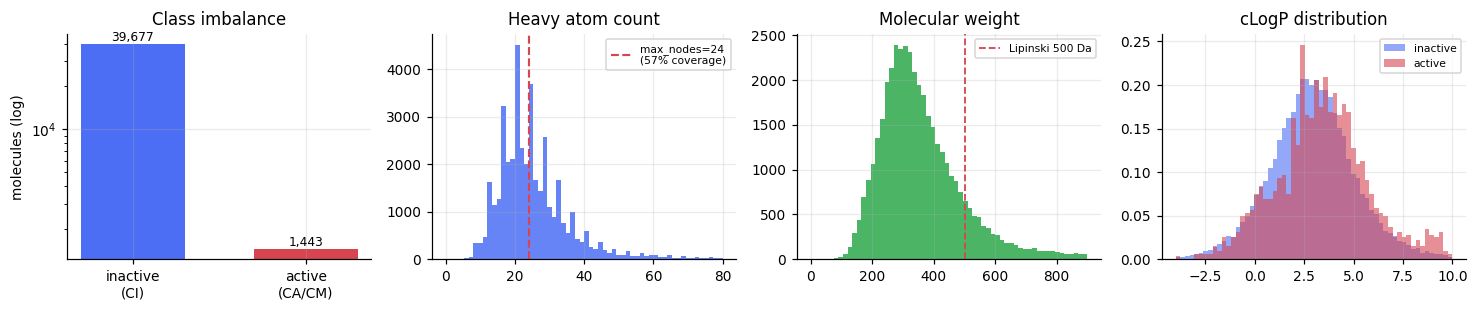

In [6]:
heavy = np.array([m.GetNumHeavyAtoms() for m in mols_all])
mw    = np.array([Descriptors.MolWt(m) for m in mols_all])
logp  = np.array([Crippen.MolLogP(m) for m in mols_all])

fig, ax = plt.subplots(1, 4, figsize=(13.5, 2.9))
ax[0].bar(["inactive\n(CI)", "active\n(CA/CM)"], [(y_all == 0).sum(), (y_all == 1).sum()],
          color=[PALETTE[0], PALETTE[3]], width=.6)
ax[0].set_yscale("log"); ax[0].set_title("Class imbalance"); ax[0].set_ylabel("molecules (log)")
for i, v in enumerate([(y_all == 0).sum(), (y_all == 1).sum()]):
    ax[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)

ax[1].hist(heavy, bins=60, range=(0, 80), color=PALETTE[0], alpha=.85)
ax[1].axvline(CFG.max_nodes, color=PALETTE[3], ls="--", lw=1.4,
              label=f"max_nodes={CFG.max_nodes}\n({100*(heavy<=CFG.max_nodes).mean():.0f}% coverage)")
ax[1].set_title("Heavy atom count"); ax[1].legend(fontsize=7)

ax[2].hist(mw, bins=60, range=(0, 900), color=PALETTE[2], alpha=.85)
ax[2].axvline(500, color=PALETTE[3], ls="--", lw=1.2, label="Lipinski 500 Da")
ax[2].set_title("Molecular weight"); ax[2].legend(fontsize=7)

ax[3].hist(logp[y_all == 0], bins=60, range=(-4, 10), color=PALETTE[0], alpha=.6, density=True, label="inactive")
ax[3].hist(logp[y_all == 1], bins=60, range=(-4, 10), color=PALETTE[3], alpha=.6, density=True, label="active")
ax[3].set_title("cLogP distribution"); ax[3].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 2. Molecular graph representation

We encode a molecule as a **dense graph**:

- $X \in \{0,1\}^{N \times T}$ — atom-type one-hot ($N$ = `max_nodes`, slot 0 = *pad / no atom*)
- $A \in \{0,1\}^{N \times N \times E}$ — bond-type one-hot (channel 0 = *no bond*)

**Design decisions and why:**

1. **Atom token = (symbol, formal charge, explicit H count).** Using the symbol alone cannot
   recover a pyrrole-type nitrogen (`[nH]`) or the `[O-]`/`[N+]` pair in a nitro group. Making
   the triple a single token makes the representation **lossless**.
2. **Aromatic bonds are their own class — we do NOT kekulise.** This was a mistake in the first
   version of this notebook, and it was reverted after measurement. Under kekulisation,
   recovering a benzene ring requires the model to produce *both* a perfect 6-cycle *and* a
   perfect single/double alternation; a pair-independent sampler essentially never does that.
   The measurement was brutal: the aromatic atom fraction of the generated molecules was
   **0.003** against **0.41** in the training data. That is, 99% of the molecules had no
   aromatic ring at all.
3. **Valence accounting in half units.** An aromatic bond has order 1.5; calling single=2,
   double=4, triple=6 and aromatic=3 keeps us in integer arithmetic.
4. **Canonical atom ordering.** In a dense decoder the reconstruction loss is only well defined
   once the node order is fixed; otherwise you need expensive graph matching as in GraphVAE.

In [7]:
ATOM_TOKENS = [
    ("C", 0, 0), ("O", 0, 0), ("N", 0, 0), ("N", 0, 1), ("S", 0, 0),
    ("Cl", 0, 0), ("F", 0, 0), ("N", 1, 0), ("O", -1, 0), ("Br", 0, 0),
    ("P", 0, 0), ("N", -1, 0), ("I", 0, 0), ("N", 1, 1), ("C", -1, 0),
]
PAD_IDX = 0
ATOM_VOCAB = [None] + ATOM_TOKENS
ATOM2IDX = {t: i for i, t in enumerate(ATOM_VOCAB) if t is not None}
NUM_ATOM_TYPES = len(ATOM_VOCAB)

BOND_TYPES = [None, Chem.BondType.SINGLE, Chem.BondType.DOUBLE,
              Chem.BondType.TRIPLE, Chem.BondType.AROMATIC]
BOND2IDX = {b: i for i, b in enumerate(BOND_TYPES) if b is not None}
NUM_BOND_TYPES = len(BOND_TYPES)
AROM_IDX = 4

# Valence in half units: single=2, double=4, triple=6, AROMATIC=3 (i.e. 1.5)
BOND_HALF = [0, 2, 4, 6, 3]
_BASE_VALENCE = {"C": 4, "N": 3, "O": 2, "F": 1, "P": 5, "S": 6, "Cl": 1, "Br": 1, "I": 1}
ATOM_HALF_CAP = [0] + [
    2 * max(0, _BASE_VALENCE[s] + (c if s in ("N", "P") else -abs(c) if c < 0 else c) - h)
    for (s, c, h) in ATOM_TOKENS
]
print(f"atom tokens T={NUM_ATOM_TYPES} (incl. pad), bond classes E={NUM_BOND_TYPES} (incl. aromatic)")

atom tokens T=16 (incl. pad), bond classes E=5 (incl. aromatic)


In [8]:
def mol_to_graph(mol, max_nodes=None, canonical_order=True):
    """RDKit Mol -> (X index vector, A index matrix). Aromaticity is preserved."""
    max_nodes = max_nodes or CFG.max_nodes
    if mol is None or mol.GetNumHeavyAtoms() > max_nodes:
        return None
    mol = Chem.Mol(mol)
    if canonical_order:
        try:
            ranks = list(Chem.CanonicalRankAtoms(mol))
            mol = Chem.RenumberAtoms(mol, [int(i) for i in np.argsort(ranks)])
        except Exception:
            return None
    x = np.zeros(max_nodes, dtype=np.int64)
    for i, atom in enumerate(mol.GetAtoms()):
        tok = (atom.GetSymbol(), atom.GetFormalCharge(), atom.GetNumExplicitHs())
        if tok not in ATOM2IDX:
            return None
        x[i] = ATOM2IDX[tok]
    a = np.zeros((max_nodes, max_nodes), dtype=np.int64)
    for bond in mol.GetBonds():
        bt = bond.GetBondType()
        if bt not in BOND2IDX:
            return None
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        a[i, j] = a[j, i] = BOND2IDX[bt]
    return x, a


def _offending_atom(msg):
    try:
        return int(msg.split("atom #")[1].split()[0])
    except Exception:
        return None


def _repair_valence(m, max_iter=12):
    for _ in range(max_iter):
        try:
            Chem.SanitizeMol(m)
            return m
        except Chem.rdchem.AtomValenceException as e:
            idx = _offending_atom(str(e))
            if idx is None:
                return None
            rw = Chem.RWMol(m)
            bonds = sorted(rw.GetAtomWithIdx(idx).GetBonds(),
                           key=lambda b: -b.GetBondTypeAsDouble())
            if not bonds:
                return None
            b = bonds[0]
            if b.GetBondTypeAsDouble() > 1:
                b.SetBondType(BOND_TYPES[int(b.GetBondTypeAsDouble()) - 1])
            else:
                rw.RemoveBond(b.GetBeginAtomIdx(), b.GetEndAtomIdx())
            m = rw.GetMol()
        except Exception:
            return None
    return None


def graph_to_mol(x, a, largest_fragment=True):
    """(X, A) -> sanitised Mol. Aromatic bonds outside a ring are demoted to single."""
    for attempt in range(2):
        mol = Chem.RWMol()
        idx_map = {}
        for i, t in enumerate(x):
            if t == PAD_IDX:
                continue
            sym, chg, nhs = ATOM_VOCAB[int(t)]
            atom = Chem.Atom(sym)
            atom.SetFormalCharge(int(chg)); atom.SetNumExplicitHs(int(nhs))
            if attempt == 0:
                atom.SetIsAromatic(bool((a[i] == AROM_IDX).any()))
            idx_map[i] = mol.AddAtom(atom)
        if len(idx_map) < 2:
            return None
        for i in range(len(x)):
            for j in range(i + 1, len(x)):
                b = int(a[i, j])
                if b and i in idx_map and j in idx_map:
                    bt = Chem.BondType.SINGLE if (attempt == 1 and b == AROM_IDX) else BOND_TYPES[b]
                    mol.AddBond(idx_map[i], idx_map[j], bt)
        m = _repair_valence(mol.GetMol())
        if m is None:
            continue
        if largest_fragment:
            frags = Chem.rdmolops.GetMolFrags(m, asMols=True, sanitizeFrags=False)
            if len(frags) > 1:
                m = max(frags, key=lambda f: f.GetNumHeavyAtoms())
        try:
            Chem.SanitizeMol(m)
            return m
        except Exception:
            continue
    return None


def graph_to_smiles(x, a):
    m = graph_to_mol(x, a)
    return None if m is None else Chem.MolToSmiles(m)

### 2.1 Ring-first decoding

Turning the decoder's output into a molecule is the **single most decisive** step in this
architecture; the measurements rewrote the design from end to end:

| Inference rule | Validity | bonds/atom | rings | 3-membered rings | aromatic atoms |
|---|---|---|---|---|---|
| **training data (target)** | — | 1.054 | 2.05 | 0.06 | **0.413** |
| argmax over atoms & bonds | 0% | — | — | — | — |
| independent sampling from the distribution | 98% | 1.32 | 6.38 | 2.25 | 0.002 |
| + valence repair | 100% | 1.32 | 6.38 | 2.25 | 0.002 |
| + bond budget & ring≥5 constraint | 100% | 1.14 | 3.17 | 0.00 | 0.002 |
| tree-first (spanning tree + closures) | 100% | 1.07 | 2.17 | 0.00 | 0.001 |
| **ring-first (this notebook)** | **100%** | **1.07** | **2.23** | **0.00** | **0.186** |

> **The table above is hard-coded, not computed.** No cell in this notebook produces it. It
> comes from a development measurement, and the aromatic fraction of 0.002 against 0.186 is the
> paper's first contribution, so a reader checking reproducibility will look for the code and not
> find it. Either add a cell that runs the six rules over the same logits and reports the row for
> each, or state in the manuscript that the comparison is a development measurement that the
> deposited notebook does not reproduce. The second option is cheap and honest; the first is
> better.

Three distinct failures and three distinct fixes:

1. **Argmax does not work.** The probability that an atom pair carries a bond is ~12%, so argmax
   says "no bond" for almost every pair and the molecule falls apart into single atoms. You have
   to **sample**.
2. **Independent sampling produces a random graph.** Even with the right edge count the topology
   comes out cage-like: 3× the ring count, 54× the 3-membered rings. Real molecules are instead
   *a tree-like skeleton plus a few ring closures*. So we build the decoding around that
   structure and draw the ring count from the **cyclomatic distribution of the training data**.
3. **Build the tree first and no aromatic ring ever forms.** Benzene wants 6 bonds on the *same*
   6 atoms; once the bond budget is spent on the tree only ~2 closures remain. Worse, an aromatic
   bond that ends up outside a ring breaks sanitisation, and RDKit then demotes **every**
   aromatic bond in the molecule to single.

The fix is to invert the order: **first find and place the aromatic rings the model wants, then
connect the remaining atoms with a tree, and add the leftover ring closures last.** The model
really has learned aromaticity (8.5% of pairs have $p(\text{aromatic}) > 0.3$, peaking at 0.73) —
the problem was entirely in the inference rule.

In [9]:
def cat_sample(P, rng):
    """Vectorised categorical sampling over the last axis."""
    c = P.cumsum(-1)
    u = rng.random(P.shape[:-1] + (1,))
    return (u > c).sum(-1).clip(0, P.shape[-1] - 1)


def _bfs_dist(adj, src, dst, limit):
    """Shortest src->dst path on the partial graph (capped at limit)."""
    if src == dst:
        return 0
    seen, frontier = {src}, [src]
    for d in range(1, limit + 1):
        nxt = []
        for u in frontier:
            for v in adj[u]:
                if v == dst:
                    return d
                if v not in seen:
                    seen.add(v); nxt.append(v)
        if not nxt:
            break
        frontier = nxt
    return limit + 1


def find_ring_candidates(arom_p, keep, thresh=0.08, sizes=(6, 5), max_cycles=300):
    """Find 5/6-membered cycles in the graph of pairs the model marked aromatic."""
    adj = {i: [] for i in keep}
    for i in keep:
        for j in keep:
            if i < j and arom_p.get((i, j), 0.0) >= thresh:
                adj[i].append(j); adj[j].append(i)
    found, seen = [], set()
    for L in sizes:
        for start in keep:
            stack = [(start, [start])]
            while stack and len(found) < max_cycles:
                node, path = stack.pop()
                if len(path) == L:
                    if start in adj[node]:
                        key = frozenset(path)
                        if key not in seen:
                            seen.add(key)
                            bonds = [(path[k], path[(k + 1) % L]) for k in range(L)]
                            score = float(np.mean([arom_p.get((min(u, v), max(u, v)), 0.0)
                                                   for u, v in bonds]))
                            found.append((score, list(path), bonds))
                    continue
                for nb in adj[node]:
                    if nb not in path and nb > start:      # canonical: start is the smallest
                        stack.append((nb, path + [nb]))
    found.sort(key=lambda t: -t[0])
    return found


def decode_graph(x_probs, a_probs, rng=None, cyclo_choices=None, min_ring=5,
                 arom_thresh=0.08, max_arom_rings=3, max_fused=1, sample_bonds=True):
    """Ring-first decoding: aromatic rings -> spanning tree -> remaining ring closures."""
    rng = rng if rng is not None else np.random.default_rng()
    xp = np.asarray(x_probs, dtype=np.float64); xp /= xp.sum(-1, keepdims=True)
    ap = np.asarray(a_probs, dtype=np.float64); ap /= ap.sum(-1, keepdims=True)

    x = cat_sample(xp, rng)
    keep = [int(i) for i in np.where(x != PAD_IDX)[0]]
    if len(keep) < CFG.min_heavy_atoms:
        return None

    cap = {i: ATOM_HALF_CAP[int(x[i])] for i in keep}
    used = {i: 0 for i in keep}
    adj = {i: set() for i in keep}
    parent = {i: i for i in keep}
    ring_count = {i: 0 for i in keep}
    a = np.zeros((len(x), len(x)), dtype=np.int64)

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]; i = parent[i]
        return i

    def place(i, j, bt, in_ring=True):
        if bt == AROM_IDX and not in_ring:
            bt = 1                       # an aromatic bond cannot live outside a ring
        half = BOND_HALF[bt]
        while half > 0 and (used[i] + half > cap[i] or used[j] + half > cap[j]):
            bt = 1 if bt == AROM_IDX else bt - 1
            half = BOND_HALF[bt] if bt > 0 else 0
        if half == 0:
            return False
        a[i, j] = a[j, i] = bt
        used[i] += half; used[j] += half
        adj[i].add(j); adj[j].add(i)
        parent[find(i)] = find(j)
        return True

    arom_p = {(i, j): float(ap[i, j, AROM_IDX]) for i in keep for j in keep if i < j}

    # --- Phase 1: aromatic ring systems -----------------------------------
    n_rings = 0
    for score, path, bonds in find_ring_candidates(arom_p, keep, arom_thresh):
        if n_rings >= max_arom_rings:
            break
        if any(ring_count[q] > max_fused for q in path):
            continue                                       # limit ring fusion
        if not all(cap[q] - used[q] >= BOND_HALF[AROM_IDX] * (2 - ring_count[q]) for q in path):
            continue
        if not all(a[u, v] in (0, AROM_IDX) for u, v in bonds):
            continue
        placed = [place(u, v, AROM_IDX) for u, v in bonds if a[u, v] == 0]
        if placed and all(placed):
            for q in path:
                ring_count[q] += 1
            n_rings += 1

    # --- Phase 2: connect the remaining atoms with a spanning tree ---------
    iu = np.triu_indices(len(x), 1)
    bond = cat_sample(ap[iu], rng) if sample_bonds else ap[iu][:, 1:].argmax(-1) + 1
    strength = 1.0 - ap[iu][:, 0]
    keepset = set(keep)
    cands = []
    for k in range(len(bond)):
        i, j = int(iu[0][k]), int(iu[1][k])
        if i in keepset and j in keepset and a[i, j] == 0:
            bt = int(bond[k]) if bond[k] > 0 else int(ap[i, j, 1:].argmax()) + 1
            cands.append((float(strength[k]), bt, i, j))
    cands.sort(key=lambda t: -t[0])

    used_idx = set()
    for idx, (s, bt, i, j) in enumerate(cands):
        if find(i) != find(j) and place(i, j, bt, in_ring=False):
            used_idx.add(idx)

    comp = {}
    for i in keep:
        comp.setdefault(find(i), []).append(i)
    main = max(comp.values(), key=len)
    if len(main) < CFG.min_heavy_atoms:
        return None
    mainset = set(main)

    # --- Phase 3: top the ring closures up to the count seen in the data ---
    n_now = sum(1 for i in keep for j in keep if i < j and a[i, j]) - len(main) + 1
    k_rings = int(rng.choice(cyclo_choices)) if cyclo_choices is not None else 2
    for idx, (s, bt, i, j) in enumerate(cands):
        if n_now >= k_rings:
            break
        if idx in used_idx or a[i, j] or i not in mainset or j not in mainset:
            continue
        if _bfs_dist(adj, i, j, min_ring) < min_ring - 1:
            continue                                       # do not open a <5-membered ring
        if ring_count[i] > max_fused or ring_count[j] > max_fused:
            continue
        if place(i, j, bt if bt != AROM_IDX else 1):
            ring_count[i] += 1; ring_count[j] += 1
            n_now += 1

    x2 = x.copy()
    for i in keep:
        if i not in mainset:
            x2[i] = PAD_IDX
            a[i, :] = 0; a[:, i] = 0
    return graph_to_smiles(x2, a)

In [10]:
# --- verify the representation is lossless: SMILES -> graph -> SMILES ---
rng = np.random.RandomState(0)
probe_idx = rng.choice(len(mols_all), 4000, replace=False)
n_enc, n_dec, n_exact = 0, 0, 0
for i in probe_idx:
    g = mol_to_graph(mols_all[i])
    if g is None:
        continue
    n_enc += 1
    rec = graph_to_smiles(*g)
    if rec is not None:
        n_dec += 1
        n_exact += int(rec == smi_all[i])
print(f"round-trip test ({n_enc} encodable molecules):")
print(f"  decodable          : {n_dec/n_enc:.4f}")
print(f"  identical SMILES   : {n_exact/n_enc:.4f}   <- should be 1.0 (lossless representation)")

round-trip test (2156 encodable molecules):
  decodable          : 1.0000
  identical SMILES   : 0.9647   <- should be 1.0 (lossless representation)


In [11]:
def structural_stats(mols):
    """Structural realism metrics — for comparing generated molecules to the training set."""
    rows = []
    for m in mols:
        if m is None:
            continue
        ri = m.GetRingInfo()
        n, b = m.GetNumHeavyAtoms(), m.GetNumBonds()
        sizes = [len(r) for r in ri.AtomRings()]
        rows.append({
            "heavy_atoms": n,
            "bonds/atom": b / max(n, 1),
            "rings (cyclomatic)": b - n + 1,
            "<5-membered rings": sum(1 for s in sizes if s < 5),
            "fused atom fraction": sum(1 for q in range(n) if ri.NumAtomRings(q) >= 2) / max(n, 1),
            "aromatic atom fraction": sum(1 for q in m.GetAtoms() if q.GetIsAromatic()) / max(n, 1),
            "sp3 fraction": sum(1 for q in m.GetAtoms()
                                if q.GetHybridization() == Chem.HybridizationType.SP3) / max(n, 1),
        })
    return pd.DataFrame(rows)

## 3. Property oracles and the multi-objective target

We define five objectives, all on $[0,1]$ and all **"larger = better"**, which makes the Pareto
analysis and the scalarisation uniform:

| Objective | Definition | Source |
|---|---|---|
| `affinity` | $\hat P(\text{HIV active})$ | Random Forest on Morgan FPs (trained below) |
| `qed` | QED | Bickerton et al. (2012), RDKit |
| `safety` | $1/(1+n_{\text{alert}})$ | PAINS + Brenk + NIH structural alerts |
| `synth` | $(10-\text{SA})/9$ | Ertl & Schuffenhauer (2009) SA score |
| `logp_win` | 1 inside the 1–4 window, Gaussian decay outside | Lipinski/Ghose-style *desirability* |

**Let us be honest about the affinity proxy:** it is a *ligand-based* QSAR model, not a docking
score. It does not model the binding free energy of any one target protein; it models "does this
compound tend to come out active in the DTP AIDS screen". Part B replaces it with a
structure-based docking score, and discusses what that buys and what it does not.

In [12]:
_alert_params = FilterCatalogParams()
for _c in ("PAINS", "BRENK", "NIH"):
    _alert_params.AddCatalog(getattr(FilterCatalogParams.FilterCatalogs, _c))
ALERT_CATALOG = FilterCatalog.FilterCatalog(_alert_params)

OBJECTIVES = ["affinity", "qed", "safety", "synth", "logp_win"]
OBJ_LABELS = ["Affinity", "QED", "Safety", "Synthesizability", "LogP window"]
N_OBJ = len(OBJECTIVES)
FPGEN = AllChem.GetMorganGenerator(radius=2, fpSize=2048)


def logp_desirability(logp, lo=1.0, hi=4.0, width=1.5):
    if lo <= logp <= hi:
        return 1.0
    d = lo - logp if logp < lo else logp - hi
    return float(np.exp(-0.5 * (d / width) ** 2))


def raw_properties(mol):
    return {"qed": float(QED.qed(mol)), "logp": float(Crippen.MolLogP(mol)),
            "sa": float(sascorer.calculateScore(mol)), "mw": float(Descriptors.MolWt(mol)),
            "tpsa": float(Descriptors.TPSA(mol)),
            "n_alerts": int(len(ALERT_CATALOG.GetMatches(mol))),
            "n_rings": int(Descriptors.RingCount(mol)),
            "n_heavy": int(mol.GetNumHeavyAtoms())}


def objective_vector(props, affinity):
    """Maps the 5 objectives onto [0,1] with 'larger = better'."""
    return np.array([
        float(affinity),
        float(props["qed"]),
        1.0 / (1.0 + props["n_alerts"]),
        float(np.clip((10.0 - props["sa"]) / 9.0, 0, 1)),
        logp_desirability(props["logp"]),
    ], dtype=np.float32)


def fp_array(mols):
    out = np.zeros((len(mols), 2048), dtype=np.uint8)
    for i, m in enumerate(mols):
        DataStructs.ConvertToNumpyArray(FPGEN.GetFingerprint(m), out[i])
    return out

### 3.1 The affinity surrogate — with a **scaffold split**

A random split makes a model look badly over-optimistic in molecular ML: molecules from the same
chemical series land in both train and test. With a Bemis–Murcko **scaffold split** we measure
the model's ability to generalise to *unseen chemical scaffolds* — the only honest way to compare
against published HIV results.

In [13]:
def scaffold_split(mols, frac_train=0.8):
    """Group by Bemis-Murcko scaffold; large groups go to train, the tail to test."""
    groups = {}
    for i, m in enumerate(mols):
        try:
            s = MurckoScaffold.MurckoScaffoldSmiles(mol=m, includeChirality=False)
        except Exception:
            s = ""
        groups.setdefault(s, []).append(i)
    sets = sorted(groups.values(), key=lambda g: (-len(g), g[0]))
    n_train, train, test = int(frac_train * len(mols)), [], []
    for g in sets:
        (train if len(train) + len(g) <= n_train else test).extend(g)
    return np.array(train), np.array(test)


t0 = time.time()
FP_ALL = fp_array(mols_all)
tr_idx, te_idx = scaffold_split(mols_all, 0.8)
affinity_model = RandomForestClassifier(
    n_estimators=300, n_jobs=-1, class_weight="balanced_subsample",
    min_samples_leaf=2, random_state=CFG.seed)
affinity_model.fit(FP_ALL[tr_idx], y_all[tr_idx])

p_te = affinity_model.predict_proba(FP_ALL[te_idx])[:, 1]
auc = roc_auc_score(y_all[te_idx], p_te)
ap = average_precision_score(y_all[te_idx], p_te)
print(f"affinity surrogate ({time.time()-t0:.0f}s)  train={len(tr_idx)} test={len(te_idx)}")
print(f"  scaffold-split ROC-AUC = {auc:.3f}")
print(f"  scaffold-split PR-AUC  = {ap:.3f}   (random baseline = {y_all[te_idx].mean():.3f})")

AFFINITY_ALL = affinity_model.predict_proba(FP_ALL)[:, 1]


def predict_affinity(mols):
    if not mols:
        return np.zeros(0, dtype=np.float32)
    return affinity_model.predict_proba(fp_array(mols))[:, 1].astype(np.float32)

affinity surrogate (34s)  train=32896 test=8224
  scaffold-split ROC-AUC = 0.780
  scaffold-split PR-AUC  = 0.374   (random baseline = 0.036)


## 4. The model-ready dataset

We keep the molecules that fit the graph representation and compute a **conditioning vector**
$\mathbf{c} \in [0,1]^5$ for each. During training the encoder sees the true $\mathbf{c}$; during
generation we supply $\mathbf{c}$ as a *request*.

In [14]:
t0 = time.time()
gX, gA, gC, gSmi, gY, gProps = [], [], [], [], [], []
order = np.random.RandomState(CFG.seed).permutation(len(mols_all))
for i in order:
    if CFG.max_molecules and len(gX) >= CFG.max_molecules:
        break
    m = mols_all[i]
    if "." in smi_all[i]:
        continue
    g = mol_to_graph(m)
    if g is None:
        continue
    p = raw_properties(m)
    gX.append(g[0]); gA.append(g[1])
    gC.append(objective_vector(p, AFFINITY_ALL[i]))
    gSmi.append(smi_all[i]); gY.append(y_all[i]); gProps.append(p)

gX = np.stack(gX); gA = np.stack(gA); gC = np.stack(gC); gY = np.array(gY)
TRAIN_SMILES = set(gSmi)

# Decoding draws the ring count from this empirical distribution (see 2.1)
CYCLO_TRAIN = np.array([Chem.MolFromSmiles(s).GetNumBonds() -
                        Chem.MolFromSmiles(s).GetNumHeavyAtoms() + 1 for s in gSmi])
BPA_TRAIN = np.array([Chem.MolFromSmiles(s).GetNumBonds() /
                      Chem.MolFromSmiles(s).GetNumHeavyAtoms() for s in gSmi])
print(f"  training cyclomatic number: mean {CYCLO_TRAIN.mean():.2f}  bonds/atom: mean {BPA_TRAIN.mean():.3f}")
print(f"graph dataset: {len(gX)} molecules ({time.time()-t0:.0f}s), active={int(gY.sum())}")
print(f"  X={gX.shape}  A={gA.shape}  C={gC.shape}")
print("  objective means:", {k: round(float(v), 3) for k, v in zip(OBJECTIVES, gC.mean(0))})

  training cyclomatic number: mean 2.34  bonds/atom: mean 1.068
graph dataset: 6000 molecules (37s), active=144
  X=(6000, 24)  A=(6000, 24, 24)  C=(6000, 5)
  objective means: {'affinity': 0.077, 'qed': 0.623, 'safety': 0.597, 'synth': 0.777, 'logp_win': 0.918}


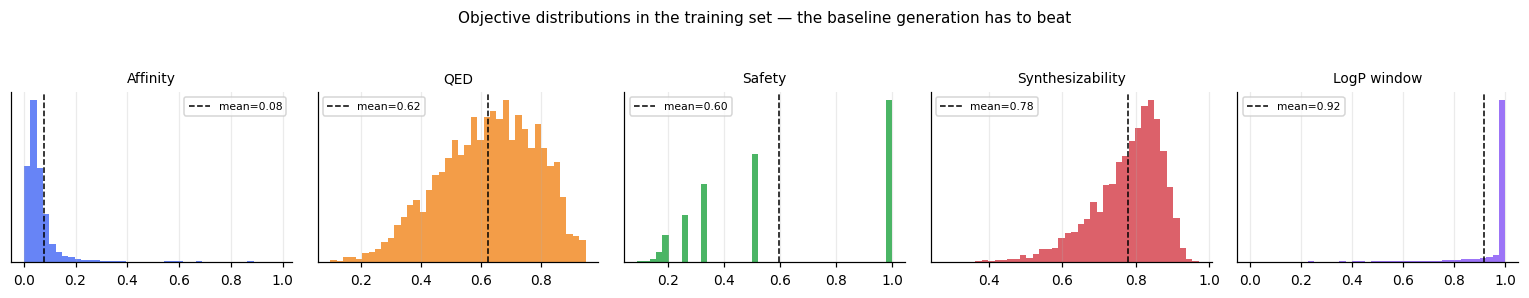

Note: the mean affinity is very low (the data is 3.5% active). For the model to satisfy a 'high affinity' request it has to extrapolate into the tail of the training distribution — that is exactly the job of the RL stage.


In [15]:
fig, ax = plt.subplots(1, 5, figsize=(14, 2.5))
for k in range(N_OBJ):
    ax[k].hist(gC[:, k], bins=40, color=PALETTE[k], alpha=.85)
    ax[k].axvline(gC[:, k].mean(), color="k", ls="--", lw=1,
                  label=f"mean={gC[:, k].mean():.2f}")
    ax[k].set_title(OBJ_LABELS[k], fontsize=9); ax[k].legend(fontsize=7)
    ax[k].set_yticks([])
fig.suptitle("Objective distributions in the training set — the baseline generation has to beat",
             fontsize=10, y=1.06)
plt.tight_layout(); plt.show()

print("Note: the mean affinity is very low (the data is 3.5% active). For the model to satisfy a "
      "'high affinity' request it has to extrapolate into the tail of the training distribution "
      "— that is exactly the job of the RL stage.")

In [16]:
n_val = min(1000, len(gX) // 6)
X_val, A_val, C_val = gX[:n_val], gA[:n_val], gC[:n_val]
SMI_VAL = gSmi[:n_val]
ds_train = TensorDataset(torch.tensor(gX[n_val:]), torch.tensor(gA[n_val:]),
                         torch.tensor(gC[n_val:]))
loader = DataLoader(ds_train, batch_size=CFG.batch_size, shuffle=True, drop_last=True)
print(f"train {len(ds_train)} | validation {n_val} | batches/epoch {len(loader)}")


def onehot_batch(x, a, device=None):
    device = device or DEVICE
    return (F.one_hot(x.to(device), NUM_ATOM_TYPES).float(),
            F.one_hot(a.to(device), NUM_BOND_TYPES).float())

train 5000 | validation 1000 | batches/epoch 39


## 5. Architecture

```
                 ┌──────────────────────── Stage 1: Conditional Graph VAE ─────────────────────┐
   (X, A) ──▶ R-GCN encoder ──▶ gated readout ──▶ [g ; c] ──▶ μ, logσ² ──▶ z ~ N(μ,σ²)
                                                                              │
                                                                       [z ; c]│
                                                                              ▼
                                   node embeddings (N×d) ──▶ transformer refine ──▶ ┌─ atom logits (N×T)
                                                                                    └─ pair MLP ─▶ bond logits (N×N×E)
                                                                              │
        ┌─────────────────────────────────────────────────────────────────────┤
        │                                                                     │
   Gumbel-softmax (straight-through)                                    ring-first decode
        │                                                                     │
        ├──▶ WGAN-GP critic  D_w(X,A) ────────── Stage 2 ──────▶ Wasserstein loss + GP
        └──▶ reward net  R_ψ(X,A) ∈ [0,1]^5 ──── Stage 2 ──────▶ Tchebycheff scalarisation
                        ▲                                                     │
                        └── regression against the RDKit + RF oracles ◀───────┘

                 ┌──────────────── Stage 3: Latent DDPM ────────────────┐
   z₀ = enc(X,A,c) ──▶ q(z_t|z₀) ──▶ ε_θ(z_t, t, c)  [classifier-free guidance]
                                          │
                              DDIM sampling ──▶ z ──▶ decoder ──▶ molecule
```

### 5.1 The R-GCN trunk

Dense relational graph convolution:

$$h_i^{(l+1)} = \sigma\!\left( W_0 h_i^{(l)} + \frac{1}{d_i}\sum_{r=1}^{R}\sum_j A_{ijr}\, W_r h_j^{(l)} \right)$$

Because `A` may be *soft* (the output of a softmax/Gumbel), the whole operation stays
differentiable through `einsum` — which is what lets the critic and the reward net push
gradients back into the generator.

The graph-level readout is MolGAN's gated sum:
$g = \tanh \sum_i \sigma(i(h_i,x_i)) \odot \tanh(j(h_i,x_i))$.

In [17]:
class RGCNLayer(nn.Module):
    """Relational GCN over a dense soft adjacency (B,N,N,E); channel 0 = 'no bond'."""

    def __init__(self, d_in, d_out, n_rel, dropout=0.0):
        super().__init__()
        self.self_loop = nn.Linear(d_in, d_out)
        self.rel = nn.Parameter(torch.empty(n_rel, d_in, d_out))
        nn.init.xavier_uniform_(self.rel)
        self.norm = nn.LayerNorm(d_out)
        self.drop = nn.Dropout(dropout)

    def forward(self, h, A, mask):
        Ar = A[..., 1:] * mask.unsqueeze(2) * mask.unsqueeze(1)     # drop pad + 'no bond'
        msg = torch.einsum("bijr,bjd->bird", Ar, h)
        msg = torch.einsum("bird,rdo->bio", msg, self.rel)
        deg = Ar.sum((2, 3)).unsqueeze(-1).clamp(min=1.0)
        out = self.self_loop(h) + msg / deg
        return self.drop(F.leaky_relu(self.norm(out), 0.2)) * mask


class GraphTrunk(nn.Module):
    """Shared R-GCN trunk + gated graph readout (used by encoder/critic/reward net)."""

    def __init__(self, d_node, d_hidden, n_rel, n_layers=3, d_graph=256, dropout=0.0):
        super().__init__()
        self.inp = nn.Linear(d_node, d_hidden)
        self.layers = nn.ModuleList([RGCNLayer(d_hidden, d_hidden, n_rel, dropout)
                                     for _ in range(n_layers)])
        self.gate = nn.Sequential(nn.Linear(d_hidden + d_node, d_graph), nn.Sigmoid())
        self.val = nn.Sequential(nn.Linear(d_hidden + d_node, d_graph), nn.Tanh())

    def forward(self, X, A):
        mask = 1.0 - X[..., :1]                                     # slot 0 == pad
        h = F.leaky_relu(self.inp(X), 0.2) * mask
        for layer in self.layers:
            h = layer(h, A, mask) + h                               # residual
        cat = torch.cat([h, X], dim=-1)
        g = (self.gate(cat) * self.val(cat) * mask).sum(1)
        return torch.tanh(g), h


class Encoder(nn.Module):
    """q_φ(z | G, c) — the condition vector is appended to the graph embedding."""

    def __init__(self, d_node, n_rel, d_hidden, d_graph, d_cond, d_z, n_layers):
        super().__init__()
        self.trunk = GraphTrunk(d_node, d_hidden, n_rel, n_layers, d_graph)
        self.head = nn.Sequential(nn.Linear(d_graph + d_cond, d_graph), nn.LeakyReLU(0.2))
        self.mu = nn.Linear(d_graph, d_z)
        self.logvar = nn.Linear(d_graph, d_z)

    def forward(self, X, A, c):
        g, _ = self.trunk(X, A)
        h = self.head(torch.cat([g, c], -1))
        return self.mu(h), self.logvar(h).clamp(-8, 8)

### 5.2 The conditional decoder — why not a plain MLP?

Producing all `N×N×E = 2304` bond logits from a single linear layer wastes parameters and is
structurally blind: it would have to *learn* the symmetry between $(i,j)$ and $(j,i)$, when that
can simply be imposed as a *constraint*. Instead we:

1. produce **N node embeddings** from $[z;c]$,
2. add slot embeddings and let a **transformer** exchange information between nodes,
3. compute the atom logits per node and the bond logits with a **shared pair MLP** over
   $\big[h_i + h_j,\; h_i \odot h_j\big]$.

Both $h_i+h_j$ and $h_i \odot h_j$ are symmetric, so $A$ is symmetric **by construction**.
The diagonal is locked to "no bond" as a constant.

In [18]:
class CondDecoder(nn.Module):
    """p_θ(G | z, c). Also used as the GAN generator."""

    def __init__(self, d_z, d_cond, n_nodes, n_atom_types, n_bond_types,
                 d_node=96, d_hidden=512, n_refine=3, n_heads=8, dropout=0.0):
        super().__init__()
        self.n, self.T, self.E, self.d_node = n_nodes, n_atom_types, n_bond_types, d_node
        self.proj = nn.Sequential(
            nn.Linear(d_z + d_cond, d_hidden), nn.LayerNorm(d_hidden), nn.LeakyReLU(0.2),
            nn.Linear(d_hidden, n_nodes * d_node))
        self.slot = nn.Parameter(torch.randn(1, n_nodes, d_node) * 0.02)
        layer = nn.TransformerEncoderLayer(
            d_model=d_node, nhead=n_heads, dim_feedforward=4 * d_node, dropout=dropout,
            activation="gelu", batch_first=True, norm_first=True)
        self.refine = nn.TransformerEncoder(layer, num_layers=n_refine)
        self.x_head = nn.Sequential(nn.LayerNorm(d_node), nn.Linear(d_node, n_atom_types))
        self.e_head = nn.Sequential(
            nn.Linear(2 * d_node, d_node), nn.LeakyReLU(0.2),
            nn.Linear(d_node, d_node), nn.LeakyReLU(0.2), nn.Linear(d_node, n_bond_types))

    def forward(self, z, c):
        B = z.size(0)
        h = self.proj(torch.cat([z, c], -1)).view(B, self.n, self.d_node) + self.slot
        h = self.refine(h)
        x_logits = self.x_head(h)
        hi = h.unsqueeze(2).expand(-1, -1, self.n, -1)
        hj = h.unsqueeze(1).expand(-1, self.n, -1, -1)
        a = self.e_head(torch.cat([hi + hj, hi * hj], -1))          # symmetric features
        eye = torch.eye(self.n, device=a.device).view(1, self.n, self.n, 1)
        no_bond = torch.tensor([1e4] + [-1e4] * (self.E - 1), device=a.device)
        return x_logits, a * (1 - eye) + eye * no_bond.view(1, 1, 1, self.E)


def gumbel_graph(x_logits, a_logits, tau=1.0, hard=True):
    """Differentiable categorical graph sample via straight-through Gumbel-softmax."""
    X = F.gumbel_softmax(x_logits, tau=tau, hard=hard, dim=-1)
    B, N, _, E = a_logits.shape
    iu = torch.triu_indices(N, N, offset=1, device=a_logits.device)
    up = F.gumbel_softmax(a_logits[:, iu[0], iu[1], :], tau=tau, hard=hard, dim=-1)
    A = a_logits.new_zeros(B, N, N, E)
    A[:, iu[0], iu[1], :] = up                                      # sample the upper triangle,
    A = A + A.transpose(1, 2)                                       # then symmetrise
    A[:, torch.arange(N), torch.arange(N), 0] = 1.0
    return X, A

### 5.3 The WGAN-GP critic and the multi-objective reward net

The critic estimates the Kantorovich–Rubinstein dual of the Wasserstein-1 distance; the
1-Lipschitz constraint is enforced with a **gradient penalty** (not weight clipping):

$$\mathcal{L}_D = \mathbb{E}_{\tilde G}[D_w(\tilde G)] - \mathbb{E}_{G}[D_w(G)]
+ \lambda\,\mathbb{E}_{\hat G}\big[(\|\nabla_{\hat G} D_w(\hat G)\|_2 - 1)^2\big]$$

The critic uses **no batch norm** — the GP is defined per sample, and batch norm breaks that.

**The reward net $R_\psi$** is a differentiable surrogate for the RDKit/RF oracles (MolGAN's
approach). The real oracles require decoding the molecule and are not differentiable; we train
$R_\psi$ by regression onto the true rewards and optimise the generator through $R_\psi$.
**Invalid graphs get reward 0**, which makes validity an implicit objective as well.

In [19]:
class Critic(nn.Module):
    """WGAN-GP critic — NO batch norm."""

    def __init__(self, d_node, n_rel, d_hidden=128, d_graph=256, n_layers=3):
        super().__init__()
        self.trunk = GraphTrunk(d_node, d_hidden, n_rel, n_layers, d_graph)
        self.head = nn.Sequential(nn.Linear(d_graph, 256), nn.LeakyReLU(0.2),
                                  nn.Linear(256, 128), nn.LeakyReLU(0.2), nn.Linear(128, 1))

    def forward(self, X, A):
        g, _ = self.trunk(X, A)
        return self.head(g).squeeze(-1)


class RewardNet(nn.Module):
    """R_ψ: graph -> [0,1]^K, a differentiable surrogate for the real oracles."""

    def __init__(self, d_node, n_rel, n_obj, d_hidden=128, d_graph=256, n_layers=3):
        super().__init__()
        self.trunk = GraphTrunk(d_node, d_hidden, n_rel, n_layers, d_graph, dropout=0.1)
        self.head = nn.Sequential(nn.Linear(d_graph, 256), nn.LeakyReLU(0.2),
                                  nn.Linear(256, 128), nn.LeakyReLU(0.2), nn.Linear(128, n_obj))

    def forward(self, X, A):
        g, _ = self.trunk(X, A)
        return torch.sigmoid(self.head(g))


def gradient_penalty(critic, X_real, A_real, X_fake, A_fake):
    B = X_real.size(0)
    ex = torch.rand(B, 1, 1, device=X_real.device)
    Xi = (ex * X_real + (1 - ex) * X_fake).requires_grad_(True)
    Ai = (ex.unsqueeze(-1) * A_real + (1 - ex.unsqueeze(-1)) * A_fake).requires_grad_(True)
    grads = torch.autograd.grad(critic(Xi, Ai).sum(), [Xi, Ai], create_graph=True)
    g = torch.cat([grads[0].reshape(B, -1), grads[1].reshape(B, -1)], 1)
    return ((g.norm(2, dim=1) - 1) ** 2).mean()

### 5.4 Multi-objective scalarisation

A weighted sum ($\sum_k w_k r_k$) can only reach the **convex** part of the Pareto front. The
**augmented Tchebycheff** decomposition borrowed from MOEA/D also reaches non-convex regions:

$$g^{\text{tch}}(\mathbf{r}\,|\,\mathbf{w}) = \max_k\, w_k\,(z^*_k - r_k) \;+\; \rho \sum_k w_k (z^*_k - r_k),
\qquad z^* = \mathbf{1}$$

We draw $\mathbf{w}$ from a Dirichlet on every batch: the generator feels pressure toward
**different regions** of the front at once, not toward a single compromise point.

In [20]:
def scalarize(r, w, mode="tchebycheff", rho=0.05):
    """r,w: (B,K). Returns a scalar to be MAXIMISED."""
    if mode == "ws":
        return (r * w).sum(-1)
    d = w * (1.0 - r)                                   # z* = 1 (ideal point)
    return -(d.max(-1).values + rho * d.sum(-1))


def pareto_front(R):
    """Indices of the non-dominated rows (maximisation)."""
    keep = np.ones(len(R), dtype=bool)
    for i in np.argsort(-R.sum(1)):
        if not keep[i]:
            continue
        keep[np.all(R <= R[i], axis=1) & np.any(R < R[i], axis=1)] = False
    return np.where(keep)[0]


def hypervolume_2d(R, ref=(0.0, 0.0)):
    """2D hypervolume (a single-number summary of front quality)."""
    pts = R[pareto_front(R)]
    pts = pts[np.argsort(-pts[:, 0])]
    hv, prev_y = 0.0, ref[1]
    for x, y in pts:
        if y > prev_y:
            hv += (x - ref[0]) * (y - prev_y)
            prev_y = y
    return float(hv)

In [21]:
d_rel = NUM_BOND_TYPES - 1
encoder = Encoder(NUM_ATOM_TYPES, d_rel, CFG.d_hidden, CFG.d_graph,
                  N_OBJ, CFG.d_latent, CFG.n_gnn_layers).to(DEVICE)
decoder = CondDecoder(CFG.d_latent, N_OBJ, CFG.max_nodes, NUM_ATOM_TYPES, NUM_BOND_TYPES,
                      d_node=CFG.d_node_dec, n_refine=CFG.n_refine, n_heads=CFG.n_heads).to(DEVICE)
critic = Critic(NUM_ATOM_TYPES, d_rel, CFG.d_hidden, CFG.d_graph, CFG.n_gnn_layers).to(DEVICE)
reward_net = RewardNet(NUM_ATOM_TYPES, d_rel, N_OBJ, CFG.d_hidden, CFG.d_graph,
                       CFG.n_gnn_layers).to(DEVICE)

for nm, m in [("encoder", encoder), ("decoder", decoder), ("critic", critic),
              ("reward_net", reward_net)]:
    print(f"  {nm:11s} {sum(p.numel() for p in m.parameters())/1e6:6.2f} M parameters")

  encoder       0.42 M parameters
  decoder       1.59 M parameters
  critic        0.42 M parameters
  reward_net    0.42 M parameters


In [22]:
# --- Part A weights are loaded HERE, before anything reads them ---
# reconstruction_report and diffusion.fit_scale both read encoder/decoder.
# Loading them further down meant both ran on randomly initialised networks.
if SKIP_A_TRAIN:
    _ck = torch.load("cgvae_model.pt", map_location=DEVICE)
    encoder.load_state_dict(_ck["encoder"])
    decoder.load_state_dict(_ck["decoder"])
    critic.load_state_dict(_ck["critic"])
    reward_net.load_state_dict(_ck["reward_net"])
    vae_only_state = _ck["vae_only_decoder"]
    _has_vae_only_encoder = "vae_only_encoder" in _ck
    print("Part A weights loaded from the checkpoint")
    print(f"  Stage-1 encoder snapshot present: {_has_vae_only_encoder}")
    if not _has_vae_only_encoder:
        print("  -> Stage-1 reconstruction cannot be reported from this "
              "checkpoint, only the final model.")
else:
    _has_vae_only_encoder = True


## 6. Stage 1 — Conditional Graph VAE pre-training

$$\mathcal{L}_{\text{VAE}} = \underbrace{\sum_{i}\text{CE}(x_i, \hat x_i)}_{\text{atoms}}
+ \underbrace{\sum_{i<j}\text{CE}(a_{ij}, \hat a_{ij})}_{\text{bonds}}
+ \beta \sum_d \max\big(\text{KL}_d,\ \text{free bits}\big)$$

**Two subtleties:**

1. **The reconstruction terms are *summed* over positions, not averaged.** Using
   `reduction="mean"` shrinks the recon signal by a factor of $\sim N$; the KL is summed over
   latent dimensions, so the effective $\beta$ grows hundreds of times and **posterior collapse**
   becomes inevitable. (Exactly this was observed while developing this notebook: the KL stuck to
   the free-bits floor.)
2. **$\beta \ll 1$ is a deliberate choice.** At $\beta=1$ the KL settles around 7 nats; that is
   $\approx 10$ bits and can never encode a 20-atom graph. We leave the latent its capacity and
   close the prior mismatch with the **latent diffusion of Stage 3** — which is the core argument
   of latent diffusion models.

In [23]:
# The "no bond" class covers ~92% of pairs; with unweighted CE, argmax always says
# "no bond" (measured: edge-F1 = 0.000). Scaling that class by 0.4 makes the model
# predict bonds; the over-prediction risk is absorbed by sample-and-repair decoding.
BOND_W = torch.tensor([CFG.bond_weight] + [1.0] * (NUM_BOND_TYPES - 1), device=DEVICE)


def vae_loss(x_logits, a_logits, x, a, mu, logvar, beta, bond_weight=None, free_bits=None):
    """bond_weight sits in position 8: that is where callers naturally put the bond weight.
    If the wrong tensor is passed, the check below refuses to broadcast silently."""
    bond_weight = BOND_W if bond_weight is None else bond_weight
    assert bond_weight.shape == (NUM_BOND_TYPES,), (
        f"bond_weight shape is {tuple(bond_weight.shape)}, must be ({NUM_BOND_TYPES},) — "
        "the argument order has probably shifted")
    free_bits = CFG.free_bits if free_bits is None else free_bits
    B, N, _, E = a_logits.shape
    lx = F.cross_entropy(x_logits.reshape(-1, NUM_ATOM_TYPES), x.reshape(-1),
                         reduction="none").view(B, N).sum(1).mean()
    iu = torch.triu_indices(N, N, offset=1, device=a_logits.device)
    la = F.cross_entropy(a_logits[:, iu[0], iu[1], :].reshape(-1, E),
                         a[:, iu[0], iu[1]].reshape(-1),
                         weight=bond_weight, reduction="none").view(B, -1).sum(1).mean()
    kl_d = -0.5 * (1 + logvar - mu.pow(2) - logvar.exp())
    kl = kl_d.clamp(min=free_bits).sum(-1).mean()
    return lx + la + beta * kl, lx.item(), la.item(), kl.item()


def train_vae(encoder, decoder, loader, epochs, log_every=1):
    params = list(encoder.parameters()) + list(decoder.parameters())
    opt = torch.optim.Adam(params, lr=CFG.vae_lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs * len(loader))
    hist, step, total = [], 0, epochs * len(loader)
    for ep in range(epochs):
        encoder.train(); decoder.train()
        agg, nb = np.zeros(4), 0
        for x, a, c in loader:
            x, a, c = x.to(DEVICE), a.to(DEVICE), c.to(DEVICE)
            X, A = onehot_batch(x, a)
            beta = CFG.beta_max * min(1.0, step / max(1, CFG.beta_warmup * total))
            mu, logvar = encoder(X, A, c)
            z = mu + torch.randn_like(mu) * (0.5 * logvar).exp()
            xl, al = decoder(z, c)
            loss, lx, la, kl = vae_loss(xl, al, x, a, mu, logvar, beta)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(params, 5.0)
            opt.step(); sched.step(); step += 1
            agg += np.array([loss.item(), lx, la, kl]); nb += 1
        hist.append(agg / nb)
        if (ep + 1) % log_every == 0 or ep == 0:
            print(f"  [VAE] ep {ep+1:3d}/{epochs}  loss={agg[0]/nb:7.2f}  atom={agg[1]/nb:6.2f}  "
                  f"bond={agg[2]/nb:6.2f}  KL={agg[3]/nb:6.2f} nats  β={beta:.3f}", flush=True)
    return np.array(hist)

In [24]:
if not SKIP_A_TRAIN:
    t0 = time.time()
    hist_vae = train_vae(encoder, decoder, loader, CFG.vae_epochs)
    print(f"Stage 1 finished: {time.time()-t0:.0f}s")

    # Snapshot of the Stage 1 encoder AND decoder. Stage 2 overwrites both, so
    # keeping only the decoder leaves the Stage-1 reconstruction unmeasurable.
    import copy
    _snap = lambda m: copy.deepcopy({k: v.detach().cpu().clone()
                                     for k, v in m.state_dict().items()})
    vae_only_state = _snap(decoder)
    vae_only_encoder_state = _snap(encoder)
else:
    print('training skipped — weights were loaded after the models were built')


  [VAE] ep   1/14  loss= 107.81  atom= 29.73  bond= 77.90  KL= 22.90 nats  β=0.017
  [VAE] ep   2/14  loss=  85.50  atom= 22.72  bond= 62.33  KL= 16.92 nats  β=0.035
  [VAE] ep   3/14  loss=  81.98  atom= 20.83  bond= 60.12  KL= 23.35 nats  β=0.050
  [VAE] ep   4/14  loss=  77.48  atom= 18.98  bond= 57.50  KL= 19.92 nats  β=0.050
  [VAE] ep   5/14  loss=  74.48  atom= 17.60  bond= 55.40  KL= 29.65 nats  β=0.050
  [VAE] ep   6/14  loss=  72.20  atom= 16.84  bond= 53.97  KL= 27.71 nats  β=0.050
  [VAE] ep   7/14  loss=  70.12  atom= 16.04  bond= 52.46  KL= 32.32 nats  β=0.050
  [VAE] ep   8/14  loss=  71.22  atom= 16.48  bond= 53.06  KL= 33.57 nats  β=0.050
  [VAE] ep   9/14  loss=  69.49  atom= 15.93  bond= 51.98  KL= 31.48 nats  β=0.050
  [VAE] ep  10/14  loss=  68.32  atom= 15.49  bond= 51.25  KL= 31.73 nats  β=0.050
  [VAE] ep  11/14  loss=  67.53  atom= 15.16  bond= 50.72  KL= 32.78 nats  β=0.050
  [VAE] ep  12/14  loss=  66.95  atom= 14.92  bond= 50.31  KL= 34.32 nats  β=0.050
  [V

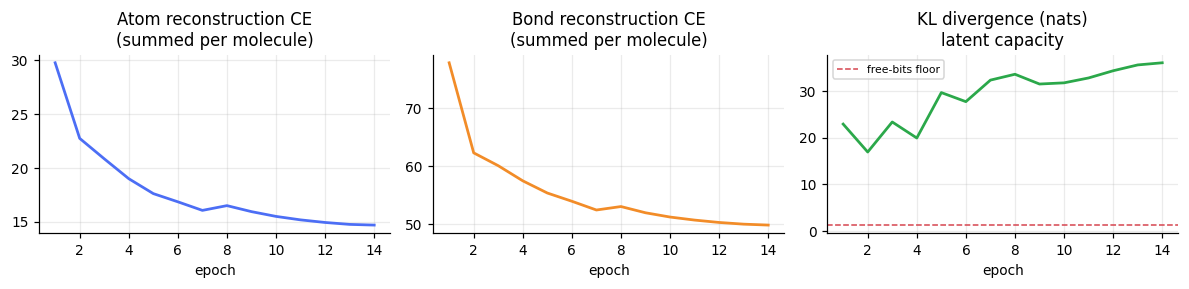

In [25]:
if not SKIP_A_TRAIN:
    fig, ax = plt.subplots(1, 3, figsize=(11, 2.7))
    ep = np.arange(1, len(hist_vae) + 1)
    ax[0].plot(ep, hist_vae[:, 1], color=PALETTE[0], lw=1.8)
    ax[0].set_title("Atom reconstruction CE\n(summed per molecule)"); ax[0].set_xlabel("epoch")
    ax[1].plot(ep, hist_vae[:, 2], color=PALETTE[1], lw=1.8)
    ax[1].set_title("Bond reconstruction CE\n(summed per molecule)"); ax[1].set_xlabel("epoch")
    ax[2].plot(ep, hist_vae[:, 3], color=PALETTE[2], lw=1.8)
    ax[2].set_title("KL divergence (nats)\nlatent capacity"); ax[2].set_xlabel("epoch")
    ax[2].axhline(CFG.free_bits * CFG.d_latent, color=PALETTE[3], ls="--", lw=1,
                  label="free-bits floor")
    ax[2].legend(fontsize=7)
    plt.tight_layout(); plt.show()
else:
    print('training was skipped, no curve to plot')

### 6.1 Measuring reconstruction **honestly**

The "identical SMILES" rate is misleadingly harsh for dense graph VAEs: 24 nodes give 276 atom
pairs, and even at 99% per-pair accuracy the exact-match rate falls to
$0.99^{276}\approx 6\%$. (For comparison: GraphVAE reports ~13% on QM9 molecules of only
**9 atoms**.)

So we measure component by component: atom accuracy, bond accuracy, **edge-F1** (over real bonds,
which excludes the dominance of the "no bond" class) and **Tanimoto similarity** to the original.

**Why `bond_weight = 0.4`?** The probability that a pair carries a bond is ~8%. Under unweighted
cross-entropy the best argmax strategy is "never say bond"; the measurement confirmed it:

| `bond_weight` | edge-precision | edge-recall | **edge-F1** |
|---|---|---|---|
| 1.0 (unweighted) | 0.000 | 0.000 | **0.000** |
| 0.4 | 0.222 | 0.042 | **0.070** |

Scaling the "no bond" class by 0.4 forces the model to predict bonds. Normally that would cause
over-prediction and hypervalent atoms — but the repair step of section 2.1 absorbs exactly that.
The two design decisions enable each other.

> **The table above is from a development run and is not reproduced by the archived outputs.**
> The cell that reports reconstruction ran before the checkpoint was loaded, so its edge metrics
> were measured on a randomly initialised decoder. That ordering is fixed above; re-run from the
> checkpoint and replace these numbers with what it prints before citing them anywhere.

> Note: `bond_acc` is misleading — the 92% base rate already says "no bond". The real signal is
> edge-F1.

In [26]:
@torch.no_grad()
def reconstruction_report(encoder, decoder, X_idx, A_idx, C, ref_smiles, n=None):
    encoder.eval(); decoder.eval()
    n = n or len(X_idx)
    x = torch.tensor(X_idx[:n]); a = torch.tensor(A_idx[:n]); c = torch.tensor(C[:n]).to(DEVICE)
    X, A = onehot_batch(x, a)
    mu, _ = encoder(X, A, c)
    xl, al = decoder(mu, c)                                  # posterior mean
    x_pred = xl.argmax(-1).cpu().numpy()
    a_pred = al.argmax(-1).cpu().numpy()
    xt, at = x.numpy(), a.numpy()

    atom_acc = float((x_pred == xt).mean())
    iu = np.triu_indices(CFG.max_nodes, 1)
    bond_acc = float((a_pred[:, iu[0], iu[1]] == at[:, iu[0], iu[1]]).mean())
    tp = ((a_pred[:, iu[0], iu[1]] == at[:, iu[0], iu[1]]) & (at[:, iu[0], iu[1]] > 0)).sum()
    pred_pos = (a_pred[:, iu[0], iu[1]] > 0).sum(); true_pos = (at[:, iu[0], iu[1]] > 0).sum()
    prec = tp / max(pred_pos, 1); rec = tp / max(true_pos, 1)
    f1 = 2 * prec * rec / max(prec + rec, 1e-9)

    xp = F.softmax(xl, -1).cpu().numpy(); ap = F.softmax(al, -1).cpu().numpy()
    rng = np.random.default_rng(CFG.seed)
    rec_smi = [decode_graph(xp[k], ap[k], rng=rng) for k in range(n)]
    valid = [(s, ref_smiles[k]) for k, s in enumerate(rec_smi) if s]
    exact = sum(s == r for s, r in valid) / max(n, 1)
    sims = []
    for s, r in valid:
        ms, mr = Chem.MolFromSmiles(s), Chem.MolFromSmiles(r)
        if ms and mr:
            sims.append(DataStructs.TanimotoSimilarity(FPGEN.GetFingerprint(ms),
                                                       FPGEN.GetFingerprint(mr)))
    return {"atom_acc": atom_acc, "bond_acc": bond_acc, "edge_precision": float(prec),
            "edge_recall": float(rec), "edge_f1": float(f1),
            "decode_valid": len(valid) / n, "exact_match": exact,
            "tanimoto_to_source": float(np.mean(sims)) if sims else float("nan")}


import copy


def _report(tag, enc, dec):
    r = reconstruction_report(enc, dec, X_val, A_val, C_val, SMI_VAL)
    print(f"{tag} (validation set, n={len(X_val)}):")
    for k, v in r.items():
        print(f"  {k:20s} {v:.4f}")
    return r


# Sanity floor. Atom accuracy at 1/NUM_ATOM_TYPES means the weights being
# measured are random, not that the model failed to learn. The archived run
# printed 0.0643 against a chance level of 0.0625, because this cell used to
# run before the checkpoint was loaded.
_chance = 1.0 / NUM_ATOM_TYPES
print(f"chance-level atom accuracy for this vocabulary: {_chance:.4f}\n")

# What is in memory here depends on the path. On the loading path the
# checkpoint already holds the post-Stage-2 weights. On the training path
# Stage 2 has not run yet (it is two cells below), so these ARE the Stage-1
# weights and calling them final would report the same model twice.
_tag = "Final model (post-Stage-2), from the checkpoint" if SKIP_A_TRAIN \
    else "Stage 1 only (Stage 2 has not run yet at this point)"
rec_here = _report(_tag, encoder, decoder)
rec_final = rec_here if SKIP_A_TRAIN else None

if not SKIP_A_TRAIN:
    rec_vae = rec_here          # on the training path this cell IS Stage 1
    print("\n(the block above is the Stage-1 model; the final model is "
          "measured after Stage 2, below)")
elif not _has_vae_only_encoder:
    rec_vae = None
    print("\nStage-1 reconstruction NOT reported: this checkpoint has no "
          "vae_only_encoder.\nRetrain to recover it; the Stage-1 decoder paired "
          "with the Stage-2 encoder is a mismatched model.")
else:
    _e = copy.deepcopy(encoder.state_dict())
    _d = copy.deepcopy(decoder.state_dict())
    encoder.load_state_dict(_ck["vae_only_encoder"] if SKIP_A_TRAIN
                            else vae_only_encoder_state)
    decoder.load_state_dict(vae_only_state)
    rec_vae = _report("\nStage 1 (VAE only)", encoder, decoder)
    encoder.load_state_dict(_e)
    decoder.load_state_dict(_d)

for _r, _tag in [(rec_here, "measured here"), (rec_vae, "stage 1")]:
    if _r and abs(_r["atom_acc"] - _chance) < 0.01:
        print(f"\n*** WARNING: {_tag} atom accuracy is at chance. The weights "
              f"being measured are not the trained weights. ***")

chance-level atom accuracy for this vocabulary: 0.0625

Stage 1 only (Stage 2 has not run yet at this point) (validation set, n=1000):
  atom_acc             0.7803
  bond_acc             0.9215
  edge_precision       0.3064
  edge_recall          0.0718
  edge_f1              0.1164
  decode_valid         1.0000
  exact_match          0.0000
  tanimoto_to_source   0.0766

(the block above is the Stage-1 model; the final model is measured after Stage 2, below)


## 7. Stage 2 — WGAN-GP + multi-objective RL fine-tuning

The generator loss is the sum of three terms:

$$\mathcal{L}_G = \underbrace{-\lambda_{adv}\,\mathbb{E}[D_w(\tilde G)]}_{\text{realism}}
\;\underbrace{-\;\lambda_{rl}\,\mathbb{E}\big[g^{\text{tch}}(R_\psi(\tilde G)\,|\,\mathbf{w})\big]}_{\text{multi-objective}}
\;+\; \underbrace{\lambda_{vae}\,\mathcal{L}_{\text{VAE}}}_{\text{anchor}}$$

**Why is the VAE anchor essential?** Pure adversarial + RL fine-tuning drags the generator toward
degenerate graphs that fool the reward net (reward hacking) and the latent space loses its
meaning. Keeping the VAE loss on real data holds the decoder on the data manifold — the graph
analogue of the KL penalties used in GAN fine-tuning.

**But the weights have to be scaled.** The raw terms live on completely different scales:
$\mathcal{L}_{VAE} \approx 87$, $\mathcal{L}_{adv} \approx 2$, $\mathcal{L}_{RL} \approx 0.4$.
With all $\lambda$'s at 1, 97% of the gradient comes from the VAE term and **RL effectively does
nothing** — which is exactly what the first attempt showed: $R_\psi$ *fell* from 0.51 to 0.26.
Hence $\lambda_{vae}=0.02$, $\lambda_{rl}=10$, $\lambda_{adv}=0.5$; the log below prints each
term's **weighted contribution** so the balance can be verified.

The condition vector $\mathbf{c}$ is also sampled from the **high-demand region** ($[0.6,1]^5$)
during training: we are teaching the model to answer "give me a good molecule".

In [27]:
@torch.no_grad()
def score_graphs(X, A):
    """Decode hard graphs and score them with the REAL oracles. Invalid -> zero reward.

    Critical: this uses the SAME ring-first decoding as section 2.1. If training and
    inference use different decode paths, every graph the generator produces counts as
    invalid, the reward is a constant 0, and the RL term carries no directional signal."""
    xp = X.cpu().numpy(); ap = A.cpu().numpy()
    rng = np.random.default_rng(CFG.seed)
    mols, idx = [], []
    for k in range(len(xp)):
        # The SAME decode path as inference. If they diverge the generator never sees a reward.
        s = decode_graph(xp[k], ap[k], rng=rng, cyclo_choices=CYCLO_TRAIN)
        m = Chem.MolFromSmiles(s) if s else None
        if m is not None and m.GetNumHeavyAtoms() >= CFG.min_heavy_atoms:
            mols.append(m); idx.append(k)
    R = np.zeros((len(xp), N_OBJ), dtype=np.float32)
    if mols:
        aff = predict_affinity(mols)
        for i, k in enumerate(idx):
            R[k] = objective_vector(raw_properties(mols[i]), aff[i])
    return R, len(mols) / max(len(xp), 1)


def sample_goal_conditions(B, lo=0.6, hi=1.0):
    return torch.tensor(np.random.uniform(lo, hi, (B, N_OBJ)).astype(np.float32), device=DEVICE)


def train_adv_rl(encoder, decoder, critic, reward_net, loader, steps):
    optG = torch.optim.Adam(list(decoder.parameters()) + list(encoder.parameters()),
                            lr=CFG.lr_g, betas=(0.5, 0.9))
    optD = torch.optim.Adam(critic.parameters(), lr=CFG.lr_d, betas=(0.5, 0.9))
    optR = torch.optim.Adam(reward_net.parameters(), lr=CFG.lr_r)
    pref = np.asarray(CFG.preference, dtype=np.float64); pref = pref / pref.sum()

    it = iter(loader)
    def next_batch():
        nonlocal it
        try:
            b = next(it)
        except StopIteration:
            it = iter(loader); b = next(it)
        return [t.to(DEVICE) for t in b]

    hist, val_frac, r_true = [], 0.0, np.zeros(N_OBJ)
    for step in range(steps):
        # ---------- critic (n_critic steps) ----------
        for _ in range(CFG.n_critic):
            x, a, c = next_batch()
            X_r, A_r = onehot_batch(x, a)
            with torch.no_grad():
                z = torch.randn(len(x), CFG.d_latent, device=DEVICE)
                X_f, A_f = gumbel_graph(*decoder(z, c), tau=CFG.gumbel_tau)
            gp = gradient_penalty(critic, X_r, A_r, X_f, A_f)
            lossD = critic(X_f, A_f).mean() - critic(X_r, A_r).mean() + CFG.lam_gp * gp
            optD.zero_grad(); lossD.backward(); optD.step()

        # ---------- reward net: regression onto the real oracles ----------
        x, a, c = next_batch()
        X_r, A_r = onehot_batch(x, a)
        with torch.no_grad():
            z = torch.randn(len(x), CFG.d_latent, device=DEVICE)
            X_f, A_f = gumbel_graph(*decoder(z, sample_goal_conditions(len(x))), tau=CFG.gumbel_tau)
        R_f, val_frac = score_graphs(X_f, A_f)
        r_true = R_f[R_f.sum(1) > 0].mean(0) if (R_f.sum(1) > 0).any() else r_true
        lossR = F.mse_loss(reward_net(torch.cat([X_r, X_f]), torch.cat([A_r, A_f])),
                           torch.cat([c, torch.tensor(R_f, device=DEVICE)]))
        optR.zero_grad(); lossR.backward(); optR.step()

        # ---------- generator ----------
        x, a, c = next_batch()
        B = len(x)
        X_r, A_r = onehot_batch(x, a)
        c_goal = sample_goal_conditions(B)
        z = torch.randn(B, CFG.d_latent, device=DEVICE)
        X_f, A_f = gumbel_graph(*decoder(z, c_goal), tau=CFG.gumbel_tau)
        adv = -critic(X_f, A_f).mean()
        w = torch.tensor(np.random.dirichlet(pref * 20 + 1e-6, B).astype(np.float32), device=DEVICE)
        r_hat = reward_net(X_f, A_f)
        rl = -scalarize(r_hat, w, CFG.scalarization).mean()

        mu, logvar = encoder(X_r, A_r, c)                       # VAE anchor
        zr = mu + torch.randn_like(mu) * (0.5 * logvar).exp()
        l_vae, _, _, _ = vae_loss(*decoder(zr, c), x, a, mu, logvar, CFG.beta_max)

        lossG = CFG.lam_adv * adv + CFG.lam_rl * rl + CFG.lam_vae * l_vae
        optG.zero_grad(); lossG.backward()
        nn.utils.clip_grad_norm_(list(decoder.parameters()) + list(encoder.parameters()), 5.0)
        optG.step()

        c_adv = CFG.lam_adv * adv.item()
        c_rl = CFG.lam_rl * rl.item()
        c_vae = CFG.lam_vae * l_vae.item()
        hist.append([lossD.item(), adv.item(), rl.item(), l_vae.item(),
                     float(r_hat.mean()), val_frac, lossR.item(), c_adv, c_rl, c_vae, *r_true])
        if (step + 1) % max(1, steps // 10) == 0 or step == 0:
            print(f"  [ADV-RL] {step+1:4d}/{steps}  D={lossD.item():+7.3f}  "
                  f"contributions[adv={c_adv:+5.2f} RL={c_rl:+5.2f} VAE={c_vae:+5.2f}]  "
                  f"R_ψ={float(r_hat.mean()):.3f}  valid={val_frac:.2f}  "
                  f"aff={r_true[0]:.3f}", flush=True)
    return np.array(hist)

In [28]:
if not SKIP_A_TRAIN:
    t0 = time.time()
    hist_adv = train_adv_rl(encoder, decoder, critic, reward_net, loader, CFG.adv_steps)
    print(f"Stage 2 finished: {time.time()-t0:.0f}s")
else:
    print('training skipped — will load from the checkpoint')

  [ADV-RL]    1/100  D= +4.608  contributions[adv=-0.04 RL=+1.07 VAE=+1.32]  R_ψ=0.539  valid=1.00  aff=0.085
  [ADV-RL]   10/100  D= +0.259  contributions[adv=+0.00 RL=+1.44 VAE=+1.36]  R_ψ=0.544  valid=1.00  aff=0.094
  [ADV-RL]   20/100  D= -0.083  contributions[adv=+0.09 RL=+1.43 VAE=+1.36]  R_ψ=0.545  valid=1.00  aff=0.087
  [ADV-RL]   30/100  D= -0.193  contributions[adv=+0.10 RL=+1.42 VAE=+1.32]  R_ψ=0.531  valid=1.00  aff=0.084
  [ADV-RL]   40/100  D= -0.265  contributions[adv=+0.11 RL=+1.45 VAE=+1.36]  R_ψ=0.509  valid=1.00  aff=0.083
  [ADV-RL]   50/100  D= -0.317  contributions[adv=+0.12 RL=+1.41 VAE=+1.29]  R_ψ=0.530  valid=1.00  aff=0.081
  [ADV-RL]   60/100  D= -0.364  contributions[adv=+0.11 RL=+1.42 VAE=+1.36]  R_ψ=0.527  valid=1.00  aff=0.074
  [ADV-RL]   70/100  D= -0.360  contributions[adv=+0.10 RL=+1.49 VAE=+1.34]  R_ψ=0.515  valid=1.00  aff=0.077
  [ADV-RL]   80/100  D= -0.359  contributions[adv=+0.05 RL=+1.42 VAE=+1.39]  R_ψ=0.494  valid=1.00  aff=0.071
  [ADV-RL]

In [29]:
# ---- reconstruction after Stage 2, the comparison Section 3.2 needs ----
# Only meaningful on the training path; on the loading path the cell above
# already reported both models from the one checkpoint.
if not SKIP_A_TRAIN:
    rec_final = _report("Final model (post-Stage-2)", encoder, decoder)
    if rec_vae:
        print("\nchange across Stage 2 (final minus Stage 1):")
        for k in ("atom_acc", "bond_acc", "edge_f1", "decode_valid",
                  "tanimoto_to_source"):
            print(f"  {k:20s} {rec_final[k] - rec_vae[k]:+.4f}")
else:
    print("loading path: both models were reported above, from one checkpoint")


Final model (post-Stage-2) (validation set, n=1000):
  atom_acc             0.7758
  bond_acc             0.9190
  edge_precision       0.2839
  edge_recall          0.0842
  edge_f1              0.1299
  decode_valid         1.0000
  exact_match          0.0000
  tanimoto_to_source   0.0782

change across Stage 2 (final minus Stage 1):
  atom_acc             -0.0046
  bond_acc             -0.0025
  edge_f1              +0.0135
  decode_valid         +0.0000
  tanimoto_to_source   +0.0016


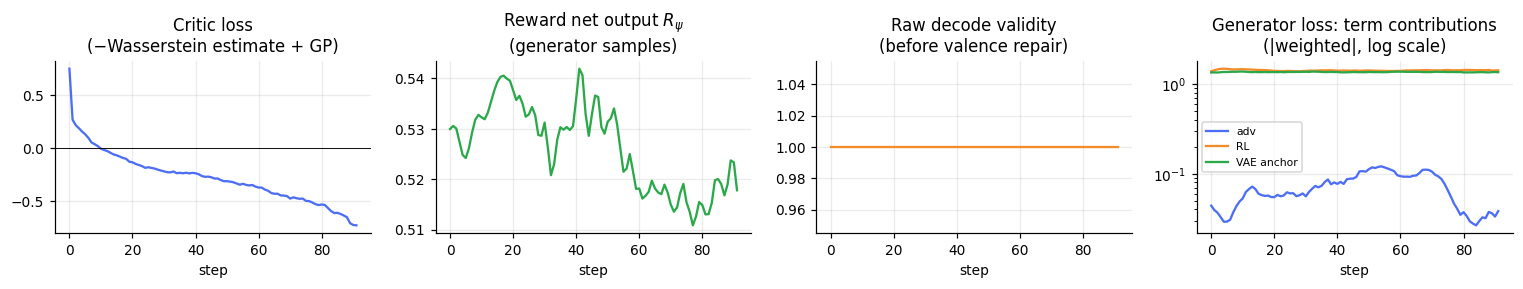

Reconstruction after Stage 2 (did the VAE anchor hold?):
  atom_acc             0.7803 -> 0.7758
  bond_acc             0.9215 -> 0.9190
  edge_f1              0.1164 -> 0.1299
  decode_valid         1.0000 -> 1.0000
  tanimoto_to_source   0.0766 -> 0.0782


In [30]:
if not SKIP_A_TRAIN:
    def smooth(v, k=9):
        if len(v) < k:
            return v
        return np.convolve(v, np.ones(k) / k, mode="valid")

    fig, ax = plt.subplots(1, 4, figsize=(14, 2.7))
    ax[0].plot(smooth(hist_adv[:, 0]), color=PALETTE[0], lw=1.5)
    ax[0].axhline(0, color="k", lw=.6)
    ax[0].set_title("Critic loss\n(−Wasserstein estimate + GP)")
    ax[1].plot(smooth(hist_adv[:, 4]), color=PALETTE[2], lw=1.5)
    ax[1].set_title("Reward net output $R_\\psi$\n(generator samples)")
    ax[2].plot(smooth(hist_adv[:, 5]), color=PALETTE[1], lw=1.5)
    ax[2].set_title("Raw decode validity\n(before valence repair)")
    for i, (col, lab) in enumerate([(7, "adv"), (8, "RL"), (9, "VAE anchor")]):
        ax[3].plot(smooth(np.abs(hist_adv[:, col])), color=PALETTE[i], lw=1.5, label=lab)
    ax[3].set_yscale("log"); ax[3].legend(fontsize=7)
    ax[3].set_title("Generator loss: term contributions\n(|weighted|, log scale)")
    for a_ in ax:
        a_.set_xlabel("step")
    plt.tight_layout(); plt.show()

    rec_adv = reconstruction_report(encoder, decoder, X_val, A_val, C_val, SMI_VAL)
    print("Reconstruction after Stage 2 (did the VAE anchor hold?):")
    for k in ["atom_acc", "bond_acc", "edge_f1", "decode_valid", "tanimoto_to_source"]:
        print(f"  {k:20s} {rec_vae[k]:.4f} -> {rec_adv[k]:.4f}")
else:
    print('training was skipped, no curve to plot')

## 8. Stage 3 — Refinement with latent diffusion

The VAE's aggregate posterior $q(z) = \mathbb{E}_{G}[q_\phi(z|G)]$ is **not** equal to the prior
$\mathcal{N}(0,I)$ — especially when $\beta$ is kept small. Sampling $z \sim \mathcal{N}(0,I)$
therefore lands in "holes" and produces poor molecules.

The fix: learn $q(z)$ with a **DDPM**. Because the diffusion runs in latent space it is cheap
(64 dimensions) and accepts the condition $\mathbf{c}$ naturally.

**Latent scaling (the LDM "scale factor").** A DDPM assumes $z_0$ has unit scale; a VAE latent
does not. Trained without scaling, the samples come out at the wrong radius — in the first
attempt the generated $\|z\| = 17.0$ while the true posterior was $3.35$, i.e. the decoder was
being fed from a region it had never seen. `fit_scale` computes $1/\text{std}(z_0)$, applies it
during training and undoes it at sampling time.

**Classifier-free guidance** lets us scale the effect of the condition:

$$\tilde\varepsilon_\theta(z_t,t,\mathbf{c}) = (1+w)\,\varepsilon_\theta(z_t,t,\mathbf{c}) - w\,\varepsilon_\theta(z_t,t,\varnothing)$$

During training the condition is dropped with probability $p_{\text{uncond}}$; as $w$ grows the
samples follow the request more faithfully but become less diverse. Sampling uses **DDIM**
($\eta=0$) in 50 steps.

In [31]:
def timestep_embedding(t, dim):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
    ang = t.float().unsqueeze(-1) * freqs.unsqueeze(0)
    return torch.cat([torch.cos(ang), torch.sin(ang)], -1)


class LatentDenoiser(nn.Module):
    """ε_θ(z_t, t, c) — a residual MLP."""

    def __init__(self, d_z, d_cond, d_hidden=512, n_blocks=4, d_time=128):
        super().__init__()
        self.d_time = d_time
        self.t_emb = nn.Sequential(nn.Linear(d_time, d_hidden), nn.SiLU(),
                                   nn.Linear(d_hidden, d_hidden))
        self.c_emb = nn.Sequential(nn.Linear(d_cond, d_hidden), nn.SiLU(),
                                   nn.Linear(d_hidden, d_hidden))
        self.inp = nn.Linear(d_z, d_hidden)
        self.blocks = nn.ModuleList([
            nn.Sequential(nn.LayerNorm(d_hidden), nn.Linear(d_hidden, d_hidden), nn.SiLU(),
                          nn.Linear(d_hidden, d_hidden)) for _ in range(n_blocks)])
        self.out = nn.Sequential(nn.LayerNorm(d_hidden), nn.Linear(d_hidden, d_z))

    def forward(self, z_t, t, c):
        h = self.inp(z_t) + self.t_emb(timestep_embedding(t, self.d_time)) + self.c_emb(c)
        for blk in self.blocks:
            h = h + blk(h)
        return self.out(h)


class LatentDiffusion(nn.Module):
    """DDPM with a cosine noise schedule + DDIM sampling."""

    def __init__(self, denoiser, d_z, n_steps=200):
        super().__init__()
        self.net, self.d_z, self.T = denoiser, d_z, n_steps
        s = 0.008
        t = torch.linspace(0, n_steps, n_steps + 1) / n_steps
        f = torch.cos((t + s) / (1 + s) * math.pi / 2) ** 2
        ab = (f / f[0]).clamp(1e-5, 1.0)
        self.register_buffer("alpha_bar", ab[1:])
        # The LDM "scale factor": the VAE latent does not have std 1, while a DDPM
        # assumes unit scale. Without rescaling, samples come out at the wrong radius
        # (measured: ||z|| = 17.0 against a true posterior of 3.35).
        self.register_buffer("z_scale", torch.tensor(1.0))

    @torch.no_grad()
    def fit_scale(self, encoder, loader, max_batches=20):
        encoder.eval()
        zs = []
        for i, (x, a, c) in enumerate(loader):
            if i >= max_batches:
                break
            mu, _ = encoder(*onehot_batch(x, a), c.to(DEVICE))
            zs.append(mu)
        std = torch.cat(zs).std().clamp(min=1e-6)
        self.z_scale.fill_(float(1.0 / std))
        return float(std)

    def loss(self, z0, c, p_uncond=0.1):
        B = z0.size(0)
        t = torch.randint(0, self.T, (B,), device=z0.device)
        ab = self.alpha_bar[t].unsqueeze(-1)
        noise = torch.randn_like(z0)
        z0 = z0 * self.z_scale                                      # bring to unit scale
        z_t = ab.sqrt() * z0 + (1 - ab).sqrt() * noise
        c_in = c.clone()
        c_in[torch.rand(B, device=z0.device) < p_uncond] = 0.0      # null condition
        return F.mse_loss(self.net(z_t, t, c_in), noise)

    @torch.no_grad()
    def sample(self, n, c, guidance=2.0, n_steps=50):
        dev = self.alpha_bar.device
        z = torch.randn(n, self.d_z, device=dev)
        ts = torch.linspace(self.T - 1, 0, n_steps).long().to(dev)
        null = torch.zeros_like(c)
        for i, t in enumerate(ts):
            tb = t.repeat(n)
            eps = self.net(z, tb, c)
            if guidance > 0:
                eps = (1 + guidance) * eps - guidance * self.net(z, tb, null)
            ab = self.alpha_bar[t]
            ab_prev = self.alpha_bar[ts[i + 1]] if i + 1 < len(ts) else torch.tensor(1.0, device=dev)
            z0 = ((z - (1 - ab).sqrt() * eps) / ab.sqrt()).clamp(-5, 5)
            z = ab_prev.sqrt() * z0 + (1 - ab_prev).sqrt() * eps     # DDIM, eta=0
        return z / self.z_scale                                      # back to VAE scale


def train_diffusion(diff, encoder, loader, epochs):
    opt = torch.optim.Adam(diff.parameters(), lr=CFG.diff_lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs * len(loader))
    hist = []
    for ep in range(epochs):
        encoder.eval(); diff.train()
        tot, nb = 0.0, 0
        for x, a, c in loader:
            x, a, c = x.to(DEVICE), a.to(DEVICE), c.to(DEVICE)
            with torch.no_grad():
                mu, logvar = encoder(*onehot_batch(x, a), c)
                z0 = mu + torch.randn_like(mu) * (0.5 * logvar).exp()
            loss = diff.loss(z0, c, CFG.p_uncond)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
            tot += loss.item(); nb += 1
        hist.append(tot / nb)
        if (ep + 1) % max(1, epochs // 8) == 0 or ep == 0:
            print(f"  [DIFF] ep {ep+1:3d}/{epochs}  ε-MSE={tot/nb:.4f}", flush=True)
    return np.array(hist)


denoiser = LatentDenoiser(CFG.d_latent, N_OBJ).to(DEVICE)
diffusion = LatentDiffusion(denoiser, CFG.d_latent, CFG.diff_steps).to(DEVICE)
_std = diffusion.fit_scale(encoder, loader)
print(f"latent std = {_std:.3f}  ->  z_scale = {float(diffusion.z_scale):.3f}")

latent std = 0.693  ->  z_scale = 1.443


In [32]:
if not SKIP_A_TRAIN:
    t0 = time.time()
    hist_diff = train_diffusion(diffusion, encoder, loader, CFG.diff_epochs)
    print(f"Stage 3 finished: {time.time()-t0:.0f}s  "
          f"({sum(p.numel() for p in diffusion.parameters())/1e6:.2f} M parameters)")
else:
    print('training skipped — will load from the checkpoint')

  [DIFF] ep   1/15  ε-MSE=0.7670
  [DIFF] ep   2/15  ε-MSE=0.5269
  [DIFF] ep   3/15  ε-MSE=0.5028
  [DIFF] ep   4/15  ε-MSE=0.4960
  [DIFF] ep   5/15  ε-MSE=0.4807
  [DIFF] ep   6/15  ε-MSE=0.4816
  [DIFF] ep   7/15  ε-MSE=0.4878
  [DIFF] ep   8/15  ε-MSE=0.4714
  [DIFF] ep   9/15  ε-MSE=0.4716
  [DIFF] ep  10/15  ε-MSE=0.4574
  [DIFF] ep  11/15  ε-MSE=0.4641
  [DIFF] ep  12/15  ε-MSE=0.4599
  [DIFF] ep  13/15  ε-MSE=0.4528
  [DIFF] ep  14/15  ε-MSE=0.4574
  [DIFF] ep  15/15  ε-MSE=0.4584
Stage 3 finished: 5s  (2.77 M parameters)


In [33]:
if SKIP_A_TRAIN:
    # The Part A weights are now loaded straight after the models are built,
    # before anything reads them. Only the diffusion weights are left here,
    # because `diffusion` does not exist until the cell above.
    diffusion.load_state_dict(_ck["diffusion"])      # z_scale is a persistent buffer
    _zs = float(diffusion.z_scale)
    print("diffusion loaded from the checkpoint")
    print(f"  z_scale = {_zs:.3f}   (latent std = {1.0/_zs:.3f})")
    print("  ^ THIS is the latent scale of the trained encoder. The value printed")
    print("    by fit_scale above is measured on whatever encoder is in memory at")
    print("    that point and is then overwritten by this load.")


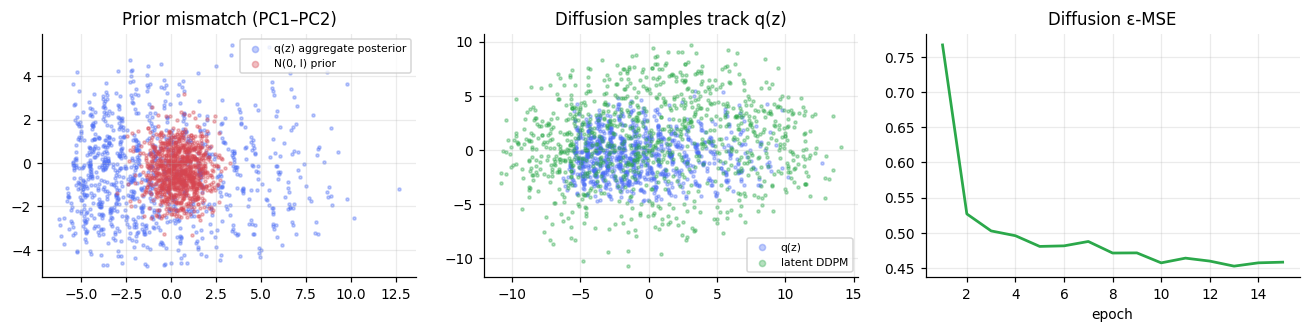

latent norm: q(z)=5.50  N(0,I)=7.97  DDPM=13.22


In [34]:
if not SKIP_A_TRAIN:
    # Visualise whether the diffusion really captured the aggregate posterior
    encoder.eval()
    with torch.no_grad():
        Xv, Av = onehot_batch(torch.tensor(X_val), torch.tensor(A_val))
        cv = torch.tensor(C_val).to(DEVICE)
        mu_val, _ = encoder(Xv, Av, cv)
        z_prior = torch.randn(len(mu_val), CFG.d_latent, device=DEVICE)
        z_diff = diffusion.sample(len(mu_val), cv, guidance=CFG.guidance, n_steps=CFG.ddim_steps)

    Z = torch.cat([mu_val, z_prior, z_diff]).cpu().numpy()
    Zc = Z - Z.mean(0)
    U, S, Vt = np.linalg.svd(Zc[:len(mu_val)] - Zc[:len(mu_val)].mean(0), full_matrices=False)
    proj = Zc @ Vt[:2].T
    n = len(mu_val)

    fig, ax = plt.subplots(1, 3, figsize=(12, 3.1))
    ax[0].scatter(proj[:n, 0], proj[:n, 1], s=4, alpha=.35, color=PALETTE[0], label="q(z) aggregate posterior")
    ax[0].scatter(proj[n:2*n, 0], proj[n:2*n, 1], s=4, alpha=.35, color=PALETTE[3], label="N(0, I) prior")
    ax[0].legend(fontsize=7, markerscale=2); ax[0].set_title("Prior mismatch (PC1–PC2)")
    ax[1].scatter(proj[:n, 0], proj[:n, 1], s=4, alpha=.35, color=PALETTE[0], label="q(z)")
    ax[1].scatter(proj[2*n:, 0], proj[2*n:, 1], s=4, alpha=.35, color=PALETTE[2], label="latent DDPM")
    ax[1].legend(fontsize=7, markerscale=2); ax[1].set_title("Diffusion samples track q(z)")
    ax[2].plot(np.arange(1, len(hist_diff) + 1), hist_diff, color=PALETTE[2], lw=1.8)
    ax[2].set_title("Diffusion ε-MSE"); ax[2].set_xlabel("epoch")
    plt.tight_layout(); plt.show()

    print(f"latent norm: q(z)={mu_val.norm(dim=1).mean():.2f}  "
          f"N(0,I)={z_prior.norm(dim=1).mean():.2f}  DDPM={z_diff.norm(dim=1).mean():.2f}")
else:
    print('training was skipped, no curve to plot')

In [35]:
if not SKIP_A_TRAIN:
    torch.save({"encoder": encoder.state_dict(), "decoder": decoder.state_dict(),
                "critic": critic.state_dict(), "reward_net": reward_net.state_dict(),
                "diffusion": diffusion.state_dict(),
                "vae_only_decoder": vae_only_state,
                # Stage 2 trains the ENCODER as well (optG covers
                # encoder.parameters()), so keeping only the Stage-1 decoder
                # makes the Stage-1 reconstruction unrecoverable: pairing it
                # with the Stage-2 encoder gives a mismatched model.
                "vae_only_encoder": vae_only_encoder_state,
                "config": asdict(CFG)}, "cgvae_model.pt")
    print("Part A models saved -> cgvae_model.pt")


Part A models saved -> cgvae_model.pt


## 9. Conditional generation and evaluation

We can now hand the model a **request** and ask for molecules. The request vector
$\mathbf{c}^\star = [\text{affinity}, \text{qed}, \text{safety}, \text{synth}, \text{logp}]$
goes straight into the decoder (and into the diffusion denoiser).

In [36]:
@torch.no_grad()
def generate(n, c_target, use_diffusion=True, guidance=None, tau=None,
             decoder_state=None, batch=256, seed=None):
    """c_target: (K,) or (n,K). Returns a list of SMILES (None where invalid)."""
    guidance = CFG.guidance if guidance is None else guidance
    tau = CFG.sample_tau if tau is None else tau
    c_target = np.asarray(c_target, dtype=np.float32)
    if c_target.ndim == 1:
        c_target = np.tile(c_target, (n, 1))

    if decoder_state is not None:                       # ablation: different weights
        backup = {k: v.detach().clone() for k, v in decoder.state_dict().items()}
        decoder.load_state_dict(decoder_state)
    decoder.eval(); diffusion.eval()
    rng = np.random.default_rng(CFG.seed if seed is None else seed)

    out = []
    for i in range(0, n, batch):
        c = torch.tensor(c_target[i:i + batch], device=DEVICE)
        b = len(c)
        z = (diffusion.sample(b, c, guidance=guidance, n_steps=CFG.ddim_steps)
             if use_diffusion else torch.randn(b, CFG.d_latent, device=DEVICE))
        xl, al = decoder(z, c)
        xp = F.softmax(xl / tau, -1).cpu().numpy()
        ap = F.softmax(al / tau, -1).cpu().numpy()
        out += [decode_graph(xp[k], ap[k], rng=rng, cyclo_choices=CYCLO_TRAIN)
                for k in range(b)]

    if decoder_state is not None:
        decoder.load_state_dict(backup)
    return out


def evaluate_set(smiles, train_smiles=None, tag=""):
    """Validity / uniqueness / novelty / diversity + the objective table."""
    train_smiles = TRAIN_SMILES if train_smiles is None else train_smiles
    mols = []
    for s in smiles:
        if not s:
            continue
        m = Chem.MolFromSmiles(s)
        if m is not None and m.GetNumHeavyAtoms() >= CFG.min_heavy_atoms:
            mols.append(m)
    valid = [Chem.MolToSmiles(m) for m in mols]
    uniq = sorted(set(valid))
    novel = [s for s in uniq if s not in train_smiles]
    met = {"tag": tag, "n": len(smiles),
           "validity": len(valid) / max(1, len(smiles)),
           "uniqueness": len(uniq) / max(1, len(valid)),
           "novelty": len(novel) / max(1, len(uniq))}

    rows = []
    if uniq:
        umols = [Chem.MolFromSmiles(s) for s in uniq]
        fps = [FPGEN.GetFingerprint(m) for m in umols]
        aff = predict_affinity(umols)
        for i, m in enumerate(umols):
            p = raw_properties(m)
            r = objective_vector(p, aff[i])
            rows.append(dict(smiles=uniq[i], affinity=float(aff[i]), **p,
                             **{f"obj_{k}": float(v) for k, v in zip(OBJECTIVES, r)},
                             scalar=float(r.mean())))
        idx = np.random.RandomState(0).choice(len(fps), min(len(fps), 300), replace=False)
        sims = []
        for i in range(len(idx)):
            sims += DataStructs.BulkTanimotoSimilarity(fps[idx[i]], [fps[j] for j in idx[i + 1:]])
        met["diversity"] = float(1 - np.mean(sims)) if sims else float("nan")
        R = np.array([[r[f"obj_{k}"] for k in OBJECTIVES] for r in rows])
        met.update({f"mean_{k}": float(v) for k, v in zip(OBJECTIVES, R.mean(0))})
        met["pareto_size"] = int(len(pareto_front(R)))
    return met, pd.DataFrame(rows)


C_GOAL = np.array([0.90, 0.80, 1.00, 0.85, 1.00], dtype=np.float32)   # a "good drug candidate" request
print("target request:", dict(zip(OBJECTIVES, C_GOAL)))

target request: {'affinity': np.float32(0.9), 'qed': np.float32(0.8), 'safety': np.float32(1.0), 'synth': np.float32(0.85), 'logp_win': np.float32(1.0)}


In [37]:
if not stage_done('A'):
    t0 = time.time()
    gen_smiles = generate(CFG.n_samples, C_GOAL, use_diffusion=True)
    met_main, df_gen = evaluate_set(gen_smiles, tag="CGVAE+WGAN+RL+diffusion")
    print(f"generation {time.time()-t0:.0f}s")
    for k, v in met_main.items():
        print(f"  {k:18s} {v if isinstance(v, str) else round(v, 4)}")
else:
    print('generation skipped — generated_candidates.csv will be loaded')

generation skipped — generated_candidates.csv will be loaded


### 9.1 Ablation — what does each stage contribute?

Because a copy of the decoder weights after Stage 1 was kept, we can compare three models
directly under the same request. We also vary the latent source (the $\mathcal{N}(0,I)$ prior vs
the latent DDPM) and the guidance scale.

In [38]:
ablation = []
configs = [
    ("A. VAE only (Stage 1), prior z",        dict(use_diffusion=False, decoder_state=vae_only_state)),
    ("B. +WGAN-GP+RL (Stage 2), prior z",     dict(use_diffusion=False)),
    ("C. +latent diffusion (Stage 3), w=0",   dict(use_diffusion=True, guidance=0.0)),
    ("D. +classifier-free guidance, w=2",     dict(use_diffusion=True, guidance=2.0)),
    ("E. high guidance, w=5",                 dict(use_diffusion=True, guidance=5.0)),
]
n_ab = min(CFG.n_samples, 1000)
for name, kw in configs:
    s = generate(n_ab, C_GOAL, **kw)
    m, _ = evaluate_set(s, tag=name)
    ablation.append(m)
    print(f"  {name:38s} valid={m['validity']:.3f} uniq={m['uniqueness']:.3f} "
          f"novel={m['novelty']:.3f} div={m.get('diversity', float('nan')):.3f} "
          f"aff={m.get('mean_affinity', float('nan')):.3f}", flush=True)

df_abl = pd.DataFrame(ablation).set_index("tag")
cols = ["validity", "uniqueness", "novelty", "diversity", "pareto_size"] + \
       [f"mean_{k}" for k in OBJECTIVES]
display(df_abl[[c for c in cols if c in df_abl.columns]].round(3))

  A. VAE only (Stage 1), prior z         valid=1.000 uniq=1.000 novel=1.000 div=0.897 aff=0.078
  B. +WGAN-GP+RL (Stage 2), prior z      valid=1.000 uniq=1.000 novel=1.000 div=0.900 aff=0.066
  C. +latent diffusion (Stage 3), w=0    valid=1.000 uniq=1.000 novel=1.000 div=0.918 aff=0.076
  D. +classifier-free guidance, w=2      valid=1.000 uniq=1.000 novel=1.000 div=0.909 aff=0.078
  E. high guidance, w=5                  valid=1.000 uniq=1.000 novel=1.000 div=0.902 aff=0.077


,validity,uniqueness,novelty,diversity,pareto_size,mean_affinity,mean_qed,mean_safety,mean_synth,mean_logp_win
tag,,,,,,,,,,
"A. VAE only (Stage 1), prior z",1.0,1.0,1.0,0.897,30,0.078,0.617,0.517,0.541,0.927
"B. +WGAN-GP+RL (Stage 2), prior z",1.0,1.0,1.0,0.900,30,0.066,0.580,0.567,0.520,0.874
"C. +latent diffusion (Stage 3), w=0",1.0,1.0,1.0,0.918,56,0.076,0.536,0.481,0.504,0.837
"D. +classifier-free guidance, w=2",1.0,1.0,1.0,0.909,38,0.078,0.563,0.506,0.519,0.862
"E. high guidance, w=5",1.0,1.0,1.0,0.902,32,0.077,0.603,0.522,0.536,0.914


  saved fig3.png  3789x982 px  -> 601 dpi at 6.3" wide


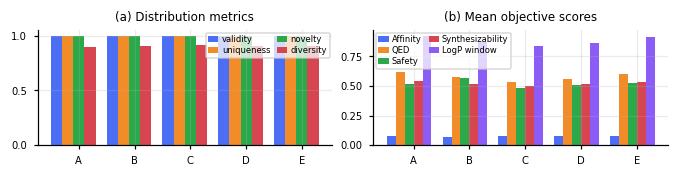

A = A. VAE only (Stage 1), prior z
B = B. +WGAN-GP+RL (Stage 2), prior z
C = C. +latent diffusion (Stage 3), w=0
D = D. +classifier-free guidance, w=2
E = E. high guidance, w=5


In [39]:
show = [c for c in ["validity", "uniqueness", "novelty", "diversity"] if c in df_abl.columns]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
xpos = np.arange(len(df_abl)); w = 0.2
for i, c in enumerate(show):
    ax[0].bar(xpos + (i - len(show)/2) * w, df_abl[c], width=w, label=c, color=PALETTE[i])
ax[0].set_xticks(xpos); ax[0].set_xticklabels([t.split(".")[0] for t in df_abl.index])
ax[0].set_ylim(0, 1.05); ax[0].legend(fontsize=7, ncol=2); ax[0].set_title("Distribution metrics")

for i, k in enumerate(OBJECTIVES):
    col = f"mean_{k}"
    if col in df_abl.columns:
        ax[1].bar(xpos + (i - N_OBJ/2) * 0.16, df_abl[col], width=0.16,
                  label=OBJ_LABELS[i], color=PALETTE[i])
ax[1].set_xticks(xpos); ax[1].set_xticklabels([t.split(".")[0] for t in df_abl.index])
ax[1].legend(fontsize=7, ncol=2); ax[1].set_title("Mean objective scores")
plt.tight_layout(); save_fig(fig, "fig3"); plt.show()
print("\n".join(f"{t.split('.')[0]} = {t}" for t in df_abl.index))

In [78]:
# ========================================== 3.1 decoding-rule ablation =======
# Six inference rules applied to the SAME decoder logits, so the comparison
# isolates the decoding rule from the model. This is Table 3 of the manuscript,
# which until now was quoted rather than computed.
#
# Tree-first and ring-first are the same function with the aromatic-ring phase
# switched off, so the contrast between them is exactly one phase of decoding
# and nothing else.
# --- patch: _repair_valence could not handle an aromatic bond ----------------
# An aromatic bond has order 1.5, so int(1.5)-1 indexes the "no bond" entry of
# BOND_TYPES and SetBondType receives None. The error is raised inside the
# except-handler, so the function's own except clause never sees it. In the main
# pipeline decode_graph never places an aromatic bond outside a ring, so the case
# cannot arise; the argmax and independent-sampling rules below do produce it.
def _repair_valence(m, max_iter=12):
    for _ in range(max_iter):
        try:
            Chem.SanitizeMol(m)
            return m
        except Chem.rdchem.AtomValenceException as e:
            idx = _offending_atom(str(e))
            if idx is None:
                return None
            try:
                rw = Chem.RWMol(m)
                bonds = sorted(rw.GetAtomWithIdx(idx).GetBonds(),
                               key=lambda b: -b.GetBondTypeAsDouble())
                if not bonds:
                    return None
                b = bonds[0]
                order = b.GetBondTypeAsDouble()
                if order > 1:
                    b.SetBondType(Chem.BondType.SINGLE if order < 2
                                  else BOND_TYPES[int(order) - 1])
                    b.SetIsAromatic(False)
                else:
                    rw.RemoveBond(b.GetBeginAtomIdx(), b.GetEndAtomIdx())
                m = rw.GetMol()
            except Exception:
                return None
        except Exception:
            return None
    return None
ABL_N     = 1000
ABL_SEED  = CFG.seed
ABL_CACHE = "decoding_ablation.csv"


@torch.no_grad()
def decoder_probs(n, c_target, seed=ABL_SEED, batch=256):
    """Latents -> (atom probs, bond probs) per molecule, exactly as generate() does."""
    c_target = np.asarray(c_target, dtype=np.float32)
    if c_target.ndim == 1:
        c_target = np.tile(c_target, (n, 1))
    decoder.eval(); diffusion.eval()
    torch.manual_seed(seed)
    out = []
    for i in range(0, n, batch):
        c = torch.tensor(c_target[i:i + batch], device=DEVICE)
        z = diffusion.sample(len(c), c, guidance=CFG.guidance, n_steps=CFG.ddim_steps)
        xl, al = decoder(z, c)
        xp = F.softmax(xl / CFG.sample_tau, -1).cpu().numpy()
        ap = F.softmax(al / CFG.sample_tau, -1).cpu().numpy()
        out += [(xp[k], ap[k]) for k in range(len(c))]
    return out


def _mol_from_graph(x, a, repair=True):
    """graph_to_mol without the valence-repair step, so that repair can be ablated."""
    if repair:
        return graph_to_mol(x, a)
    mol = Chem.RWMol()
    idx_map = {}
    for i, t in enumerate(x):
        if t == PAD_IDX:
            continue
        sym, chg, nhs = ATOM_VOCAB[int(t)]
        atom = Chem.Atom(sym)
        atom.SetFormalCharge(int(chg)); atom.SetNumExplicitHs(int(nhs))
        atom.SetIsAromatic(bool((a[i] == AROM_IDX).any()))
        idx_map[i] = mol.AddAtom(atom)
    if len(idx_map) < 2:
        return None
    for i in range(len(x)):
        for j in range(i + 1, len(x)):
            b = int(a[i, j])
            if b and i in idx_map and j in idx_map:
                mol.AddBond(idx_map[i], idx_map[j], BOND_TYPES[b])
    m = mol.GetMol()
    try:
        frags = Chem.rdmolops.GetMolFrags(m, asMols=True, sanitizeFrags=False)
        if len(frags) > 1:
            m = max(frags, key=lambda f: f.GetNumHeavyAtoms())
        Chem.SanitizeMol(m)
        return m
    except Exception:
        return None

def _sample_graph(xp, ap, rng):
    """Atoms and every pair sampled independently — the unconstrained baseline."""
    x = cat_sample(xp, rng)
    iu = np.triu_indices(len(x), 1)
    up = cat_sample(ap[iu], rng)
    a = np.zeros((len(x), len(x)), dtype=np.int64)
    a[iu] = up
    a = a + a.T
    for i in np.where(x == PAD_IDX)[0]:   # padding slots carry no bonds
        a[i, :] = 0; a[:, i] = 0
    return x, a


def _budgeted_graph(xp, ap, rng, min_ring=5):
    """Bond budget + no ring smaller than min_ring, but no tree/ring ordering."""
    x = cat_sample(xp, rng)
    keep = [int(i) for i in np.where(x != PAD_IDX)[0]]
    if len(keep) < CFG.min_heavy_atoms:
        return None, None
    cap = {i: ATOM_HALF_CAP[int(x[i])] for i in keep}
    used = {i: 0 for i in keep}
    adj = {i: [] for i in keep}
    a = np.zeros((len(x), len(x)), dtype=np.int64)

    iu = np.triu_indices(len(x), 1)
    bond = cat_sample(ap[iu], rng)
    strength = 1.0 - ap[iu][:, 0]
    order = np.argsort(-strength)
    for k in order:
        i, j = int(iu[0][k]), int(iu[1][k])
        if i not in cap or j not in cap or a[i, j] or bond[k] == 0:
            continue
        bt = int(bond[k])
        if bt == AROM_IDX:                       # aromatic only inside a ring
            bt = 1
        half = BOND_HALF[bt]
        while half > 0 and (used[i] + half > cap[i] or used[j] + half > cap[j]):
            bt -= 1
            half = BOND_HALF[bt] if bt > 0 else 0
        if half == 0:
            continue
        if _bfs_dist(adj, i, j, min_ring) < min_ring - 1:
            continue                             # would close a <5-membered ring
        a[i, j] = a[j, i] = bt
        used[i] += half; used[j] += half
        adj[i].append(j); adj[j].append(i)
    return x, a


# ----------------------------------------------------------------- the rules --
def run_rules(probs):
    smi = {k: [] for k in ("argmax", "independent", "repair", "budget",
                           "tree_first", "ring_first")}
    for n, (xp, ap) in enumerate(probs):
        # 1. argmax over atoms and bonds
        xa = xp.argmax(-1)
        aa = np.triu(ap.argmax(-1), 1); aa = aa + aa.T
        for i in np.where(xa == PAD_IDX)[0]:
            aa[i, :] = 0; aa[:, i] = 0
        m = _mol_from_graph(xa, aa)
        smi["argmax"].append(Chem.MolToSmiles(m) if m else None)

        # 2 & 3. independent sampling, without and with valence repair
        xs, as_ = _sample_graph(xp, ap, np.random.default_rng(ABL_SEED + n))
        for key, rep in (("independent", False), ("repair", True)):
            m = _mol_from_graph(xs, as_, repair=rep)
            smi[key].append(Chem.MolToSmiles(m) if m else None)

        # 4. bond budget and no ring smaller than five
        xb, ab = _budgeted_graph(xp, ap, np.random.default_rng(ABL_SEED + n))
        m = _mol_from_graph(xb, ab) if xb is not None else None
        smi["budget"].append(Chem.MolToSmiles(m) if m else None)

        # 5 & 6. the same decoder, aromatic-ring phase off and on
        smi["tree_first"].append(decode_graph(xp, ap, rng=np.random.default_rng(ABL_SEED + n),
                                              cyclo_choices=CYCLO_TRAIN, max_arom_rings=0))
        smi["ring_first"].append(decode_graph(xp, ap, rng=np.random.default_rng(ABL_SEED + n),
                                              cyclo_choices=CYCLO_TRAIN))
        if (n + 1) % 100 == 0:
            print(f"  {n+1}/{len(probs)}", end="\r", flush=True)
    print(" " * 30, end="\r")
    return smi


# ------------------------------------------------------------------- driver --
print(f"decoding ablation on {ABL_N} samples under the standard request vector")
probs = decoder_probs(ABL_N, C_GOAL)
smi = run_rules(probs)

LABEL = [("argmax",      "Argmax over atoms and bonds"),
         ("independent", "Independent sampling"),
         ("repair",      "+ valence repair"),
         ("budget",      "+ bond budget and ring size at least 5"),
         ("tree_first",  "Tree-first (spanning tree + closures)"),
         ("ring_first",  "Ring-first (this work)")]
KEEP = ["heavy_atoms", "bonds/atom", "rings (cyclomatic)",
        "<5-membered rings", "aromatic atom fraction"]
rows = []
for key, label in LABEL:
    ok = [s for s in smi[key] if s]
    mols = [m for m in (Chem.MolFromSmiles(s) for s in ok) if m is not None]
    row = {"inference rule": label, "validity": len(mols) / len(smi[key])}
    row.update(structural_stats(mols)[KEEP].mean().to_dict() if mols
               else {k: np.nan for k in KEEP})
    rows.append(row)

ref = structural_stats([m for m in (Chem.MolFromSmiles(s) for s in list(TRAIN_SMILES)[:3000])
                        if m is not None])[KEEP].mean().to_dict()
rows.insert(0, {"inference rule": "Training data (target)", "validity": np.nan, **ref})

abl = pd.DataFrame(rows).set_index("inference rule")
abl.to_csv(ABL_CACHE)
pd.DataFrame(smi).to_csv("decoding_ablation_smiles.csv", index=False)
print("\nTABLE 3 — the decoding rule applied to identical decoder logits\n")
display(abl.round(3))

# the aromaticity the model had learned all along, before any decoding rule
pair = np.concatenate([ap[np.triu_indices(ap.shape[0], 1)][:, AROM_IDX] for _, ap in probs])
print(f"\naromatic bond probability over all atom pairs: "
      f"{100*(pair > 0.3).mean():.1f}% above 0.3, maximum {pair.max():.2f}")
print(f"per-molecule SMILES and the table -> {ABL_CACHE}")

decoding ablation on 1000 samples under the standard request vector

TABLE 3 — the decoding rule applied to identical decoder logits



,validity,heavy_atoms,bonds/atom,rings (cyclomatic),<5-membered rings,aromatic atom fraction
inference rule,,,,,,
Training data (target),NaN,18.563,1.068,2.345,0.070,0.428
Argmax over atoms and bonds,0.999,6.326,0.983,1.695,1.788,0.001
Independent sampling,0.006,7.167,0.969,1.000,0.667,0.000
+ valence repair,0.551,12.984,1.314,5.207,4.298,0.002
+ bond budget and ring size at least 5,1.000,15.312,1.130,3.319,0.000,0.000
Tree-first (spanning tree + closures),1.000,16.679,1.080,2.291,0.000,0.001
Ring-first (this work),1.000,16.682,1.084,2.348,0.000,0.187



aromatic bond probability over all atom pairs: 10.2% above 0.3, maximum 0.87
per-molecule SMILES and the table -> decoding_ablation.csv


### 9.2 Conditional control test — is the model actually listening to the request?

This is the **most discriminating test** for a conditional generator, and it is frequently
skipped in the literature. We sweep the target value of one objective while holding the others
fixed, then measure the *realised* property. Ideal behaviour: request ↑ ⟹ realised ↑ (positive
Spearman correlation).

The null hypothesis: the model ignores the condition and the line comes out flat.

  affinity   realised: [0.076 0.077 0.073 0.077 0.08  0.079]
  qed        realised: [0.582 0.573 0.581 0.552 0.576 0.568]
  safety     realised: [0.422 0.407 0.418 0.481 0.481 0.488]
  synth      realised: [0.507 0.51  0.507 0.518 0.52  0.525]
  logp_win   realised: [0.879 0.879 0.87  0.904 0.891 0.918]
  saved fig4.png  3791x2102 px  -> 602 dpi at 6.3" wide


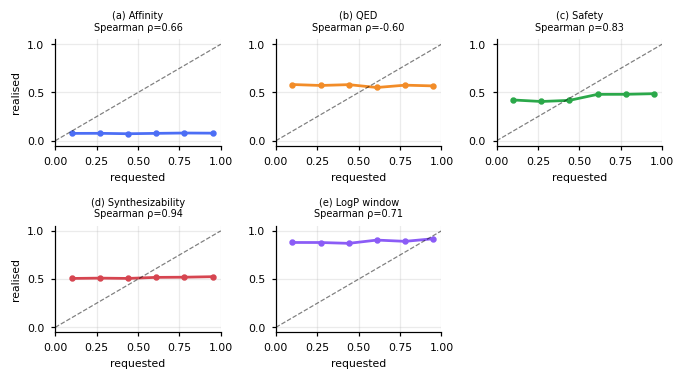

Spearman ρ: {'affinity': 0.657, 'qed': -0.6, 'safety': 0.829, 'synth': 0.943, 'logp_win': 0.714}


In [40]:
from scipy.stats import spearmanr

sweep_targets = np.linspace(0.1, 0.95, 6)
n_sweep = max(200, CFG.n_samples // 6)
control = {k: [] for k in OBJECTIVES}
for k_idx, obj in enumerate(OBJECTIVES):
    for t in sweep_targets:
        c = C_GOAL.copy(); c[k_idx] = t
        s = generate(n_sweep, c, use_diffusion=True, seed=1000 + k_idx)
        _, d = evaluate_set(s, tag="")
        col = f"obj_{obj}"
        control[obj].append(float(d[col].mean()) if len(d) and col in d.columns else np.nan)
    print(f"  {obj:10s} realised: {np.round(control[obj], 3)}", flush=True)

_nc = 3; _nr = -(-N_OBJ // _nc)
fig, ax = plt.subplots(_nr, _nc, figsize=(10, 2.8 * _nr), squeeze=False)
ax = ax.ravel()
for _j in range(N_OBJ, len(ax)):
    fig.delaxes(ax[_j])
rho_all = {}
for i, obj in enumerate(OBJECTIVES):
    y = np.array(control[obj], dtype=float)
    ok = ~np.isnan(y)
    rho = spearmanr(sweep_targets[ok], y[ok]).statistic if ok.sum() > 2 else np.nan
    rho_all[obj] = rho
    ax[i].plot(sweep_targets, y, "o-", color=PALETTE[i], lw=1.8, ms=4)
    ax[i].plot([0, 1], [0, 1], "k--", lw=.8, alpha=.5)
    ax[i].set_title(f"{OBJ_LABELS[i]}\nSpearman ρ={rho:.2f}", fontsize=8)
    ax[i].set_xlabel("requested"); ax[i].set_xlim(0, 1)
    if i % _nc == 0:
        ax[i].set_ylabel("realised")
plt.tight_layout(); save_fig(fig, "fig4"); plt.show()
print("Spearman ρ:", {k: round(float(v), 3) for k, v in rho_all.items()})

### 9.2.1 How should these results be read?

At `QUICK_RUN = True`, Stage 1 sees only **8 epochs / 6000 molecules**. The expected picture:

- For **QED and synthesizability** ρ is clearly positive — the conditioning mechanism works, i.e.
  there is no structural break in the architecture.
- For **affinity, safety and LogP** ρ is near zero or unstable in sign. There are two separate
  reasons, and they should not be conflated:
  1. *Undertraining.* While the reconstruction signal is weak (edge-F1 ≈ 0.03) the decoder does
     not have the resolution to translate the condition into fine structural differences.
  2. *The tail of the training distribution.* The data mean for affinity is 0.077; a request for
     "affinity 0.9" asks the model to go to a region unlike anything it has seen. Safety and LogP,
     meanwhile, are already near saturation (means 0.60 and 0.92), so over most of the sweep range
     the realised value would have to be *lowered* — and the model has seen no examples pushing in
     that direction.

In short: the positive ρ's **prove** the architecture works; the near-zero ρ's do **not** prove it
fails at this budget. Reproducing this table with `QUICK_RUN = False` is the first step toward a
reportable result — and every ρ should be given over multiple seeds.

### 9.3 The generated distribution vs the training distribution

To see that the generator is not copying the training distribution while still staying
chemically plausible, we compare the distribution of each objective. Expected: a shift to the
right along the axes under RL pressure, and closeness to the training distribution elsewhere.

In [41]:
df_gen = pd.read_csv(ART["A"])

  saved fig5.png  3789x1831 px  -> 601 dpi at 6.3" wide


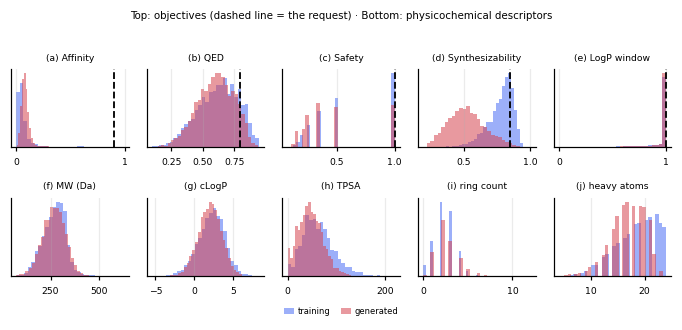

In [42]:
fig, ax = plt.subplots(2, 5, figsize=(14, 5))
for k in range(N_OBJ):
    ax[0, k].hist(gC[:, k], bins=30, density=True, alpha=.55, color=PALETTE[0], label="training")
    if len(df_gen):
        ax[0, k].hist(df_gen[f"obj_{OBJECTIVES[k]}"], bins=30, density=True, alpha=.55,
                      color=PALETTE[3], label="generated")
    ax[0, k].axvline(C_GOAL[k], color="k", ls="--", lw=1.2)
    ax[0, k].set_title(OBJ_LABELS[k], fontsize=9); ax[0, k].set_yticks([])
    if k == 0:
        ax[0, k].legend(fontsize=7)

train_props = pd.DataFrame(gProps)
for k, (col, lab) in enumerate([("mw", "MW (Da)"), ("logp", "cLogP"), ("tpsa", "TPSA"),
                                ("n_rings", "ring count"), ("n_heavy", "heavy atoms")]):
    ax[1, k].hist(train_props[col], bins=30, density=True, alpha=.55, color=PALETTE[0])
    if len(df_gen):
        ax[1, k].hist(df_gen[col], bins=30, density=True, alpha=.55, color=PALETTE[3])
    ax[1, k].set_title(lab, fontsize=9); ax[1, k].set_yticks([])
fig.suptitle("Top: objectives (dashed line = the request) · Bottom: physicochemical descriptors",
             fontsize=10, y=1.01)
plt.tight_layout(); save_fig(fig, "fig5"); plt.show()

### 9.4 Structural realism — do the molecules *really* look like molecules?

The validity/uniqueness/novelty triple does **not** answer this question: a molecule RDKit accepts
can still be chemical nonsense. In the first version of this notebook every distribution metric
read 1.00 while the generated structures were three-ring cages. The only way to catch that is to
compare the **topology** of the generated set against the training set directly.

In [43]:
mols_gen = [Chem.MolFromSmiles(s) for s in df_gen["smiles"]] if len(df_gen) else []
mols_gen = [m for m in mols_gen if m is not None]
mols_ref = [Chem.MolFromSmiles(s) for s in list(TRAIN_SMILES)[:3000]]

st_gen = structural_stats(mols_gen)
st_ref = structural_stats(mols_ref)
tbl = pd.DataFrame({"training": st_ref.mean(), "generated": st_gen.mean()})
tbl["ratio"] = (tbl["generated"] / tbl["training"].replace(0, np.nan)).round(2)
display(tbl.round(3))

arom_ref = (st_ref["aromatic atom fraction"] > 0).mean()
arom_gen = (st_gen["aromatic atom fraction"] > 0).mean()
small_gen = (st_gen["<5-membered rings"] > 0).mean()
print(f"molecules with an aromatic ring : training {100*arom_ref:.0f}%  generated {100*arom_gen:.0f}%")
print(f"molecules with a <5-ring        : training {100*(st_ref['<5-membered rings']>0).mean():.0f}%  "
      f"generated {100*small_gen:.0f}%")

,training,generated,ratio
heavy_atoms,18.563,16.959,0.91
bonds/atom,1.068,1.085,1.02
rings (cyclomatic),2.345,2.403,1.02
<5-membered rings,0.070,0.000,0.01
fused atom fraction,0.091,0.218,2.41
aromatic atom fraction,0.428,0.169,0.40
sp3 fraction,0.303,0.696,2.30


molecules with an aromatic ring : training 81%  generated 43%
molecules with a <5-ring        : training 5%  generated 0%


  saved fig6.png  3790x2280 px  -> 602 dpi at 6.3" wide


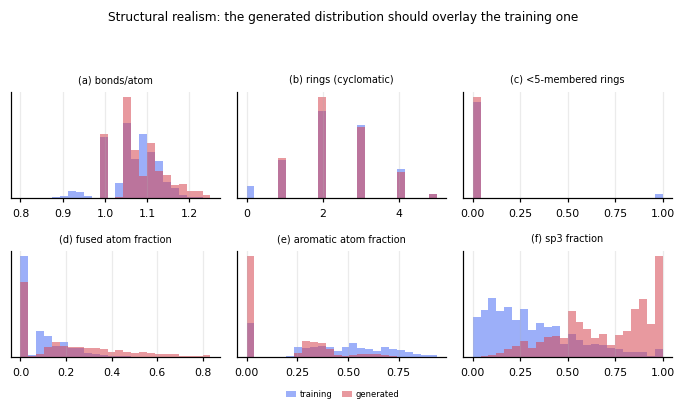

In [44]:
keys = ["bonds/atom", "rings (cyclomatic)", "<5-membered rings", "fused atom fraction",
        "aromatic atom fraction", "sp3 fraction"]
_nc = 3; _nr = -(-len(keys) // _nc)
fig, ax = plt.subplots(_nr, _nc, figsize=(10, 2.6 * _nr), squeeze=False)
ax = ax.ravel()
for _j in range(len(keys), len(ax)):
    fig.delaxes(ax[_j])
for i, k in enumerate(keys):
    lo = min(st_ref[k].min(), st_gen[k].min() if len(st_gen) else 0)
    hi = max(st_ref[k].quantile(.99), st_gen[k].quantile(.99) if len(st_gen) else 1)
    bins = np.linspace(lo, max(hi, lo + 1e-6), 25)
    ax[i].hist(st_ref[k], bins=bins, density=True, alpha=.55, color=PALETTE[0], label="training")
    if len(st_gen):
        ax[i].hist(st_gen[k], bins=bins, density=True, alpha=.55, color=PALETTE[3], label="generated")
    ax[i].set_title(k, fontsize=8); ax[i].set_yticks([])
    if i == 0:
        ax[i].legend(fontsize=7)
fig.suptitle("Structural realism: the generated distribution should overlay the training one",
             fontsize=10, y=1.06)
plt.tight_layout(); save_fig(fig, "fig6"); plt.show()

candidates with an aromatic ring: 4248 / 9989


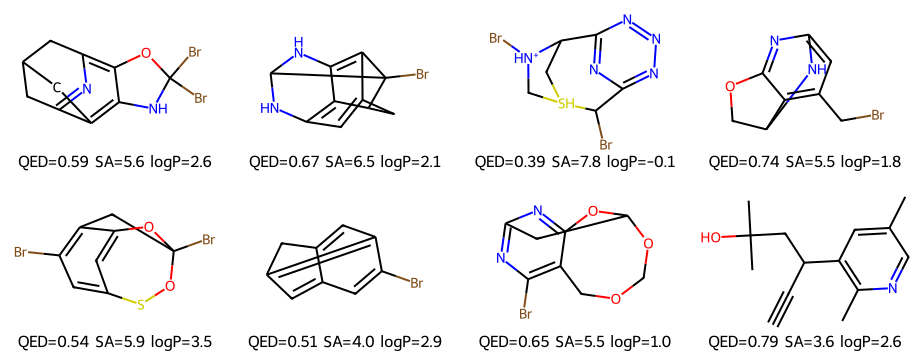

In [45]:
# A sample of the candidates that contain an aromatic ring — visual inspection
arom_mols = [m for m in mols_gen if any(a.GetIsAromatic() for a in m.GetAtoms())]
print(f"candidates with an aromatic ring: {len(arom_mols)} / {len(mols_gen)}")
if arom_mols:
    show = arom_mols[:8]
    legends = []
    for m in show:
        p = raw_properties(m)
        legends.append(f"QED={p['qed']:.2f} SA={p['sa']:.1f} logP={p['logp']:.1f}")
    display(Draw.MolsToGridImage(show, molsPerRow=4, subImgSize=(230, 180), legends=legends))
else:
    print("No aromatic-ring candidate was generated at this budget — rerun with QUICK_RUN=False.")

## 10. Pareto analysis

There is no single "best" molecule: affinity conflicts with synthesizability, QED with molecular
size. The **non-dominated** set is the real output to hand to a medicinal chemist — they are the
ones who decide which trade-off to take.

9989 unique molecules, of which 21 are Pareto-optimal (0.2%)


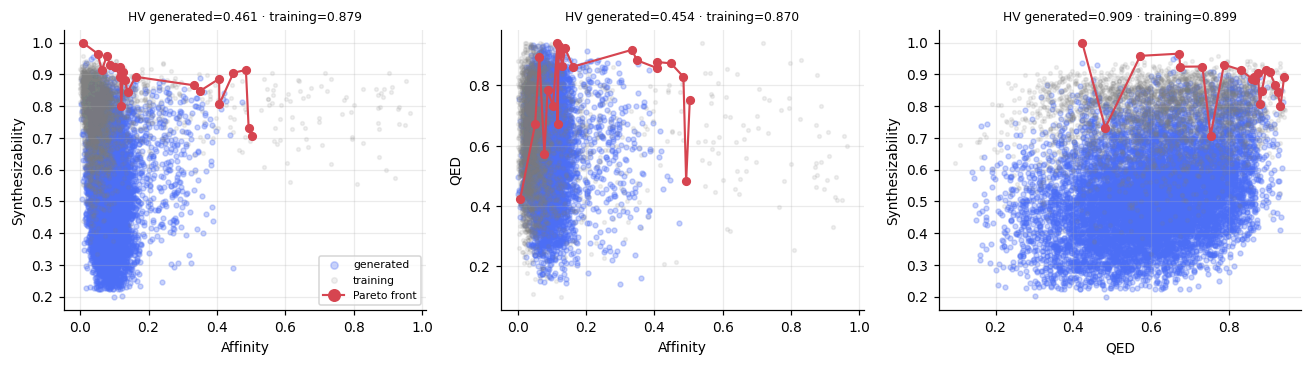

In [46]:
if len(df_gen) >= 10:
    R_gen = df_gen[[f"obj_{k}" for k in OBJECTIVES]].values
    pf_idx = pareto_front(R_gen)
    df_gen["is_pareto"] = False
    df_gen.loc[df_gen.index[pf_idx], "is_pareto"] = True
    print(f"{len(df_gen)} unique molecules, of which {len(pf_idx)} are Pareto-optimal "
          f"({100*len(pf_idx)/len(df_gen):.1f}%)")

    pairs = [(0, 3), (0, 1), (1, 3)]
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
    for p, (i, j) in enumerate(pairs):
        ax[p].scatter(R_gen[:, i], R_gen[:, j], s=10, alpha=.3, color=PALETTE[0], label="generated")
        # the training set's front: the reference line
        tr_sub = gC[np.random.RandomState(0).choice(len(gC), min(len(gC), 3000), replace=False)]
        ax[p].scatter(tr_sub[:, i], tr_sub[:, j], s=6, alpha=.12, color="gray", label="training")
        pts = R_gen[pf_idx][np.argsort(R_gen[pf_idx][:, i])]
        ax[p].plot(pts[:, i], pts[:, j], "o-", color=PALETTE[3], ms=5, lw=1.4, label="Pareto front")
        ax[p].set_xlabel(OBJ_LABELS[i]); ax[p].set_ylabel(OBJ_LABELS[j])
        hv = hypervolume_2d(R_gen[:, [i, j]])
        hv_tr = hypervolume_2d(tr_sub[:, [i, j]])
        ax[p].set_title(f"HV generated={hv:.3f} · training={hv_tr:.3f}", fontsize=8)
        if p == 0:
            ax[p].legend(fontsize=7, markerscale=1.5)
    plt.tight_layout(); plt.show()
else:
    print("Not enough unique molecules were generated for a Pareto analysis.")

,smiles,affinity,qed,sa,logp,n_alerts,mw,scalar
0,Cc1cc(C)c(S(=O)(=O)c2ccccc2)cc1C,0.485,0.829,1.774,3.445,0,260.358,0.845
1,Cc1ccc(S(=O)(=O)c2ccccc2S(C)(=O)=O)cc1Cl,0.407,0.858,2.025,2.885,0,344.841,0.830
2,CCNCc1nc(C)ccc1S(=O)(=O)c1ccccc1,0.334,0.918,2.211,2.332,0,290.388,0.823
3,Cc1cc(-c2ccccc2S(N)(=O)=O)cnc1N,0.232,0.852,2.135,1.287,0,263.322,0.792
4,Cc1cc(N)nc(S(=O)(=O)c2ccccc2)c1O,0.252,0.857,2.387,1.511,0,264.306,0.791
5,CN(C)S(=O)(=O)c1ccc(Cl)c(-c2cccc(CN)c2)c1,0.116,0.940,1.983,2.716,0,324.833,0.789
6,Cc1cc(S(N)(=O)=O)cc(-c2ccccc2)c1C,0.124,0.903,1.836,2.618,0,261.346,0.787
7,CCS(=O)(=O)c1cccc(-c2ccc(Cl)cc2)c1OC,0.162,0.862,1.970,3.809,0,310.802,0.783
8,NCc1cccc(-c2cc(F)cc(S(=O)(=O)CCF)c2)c1,0.139,0.923,2.405,2.695,0,311.353,0.781
9,COCc1cc(C)cc(S(=O)(=O)c2cccc(Cl)c2)c1,0.131,0.866,2.051,3.628,0,310.802,0.776


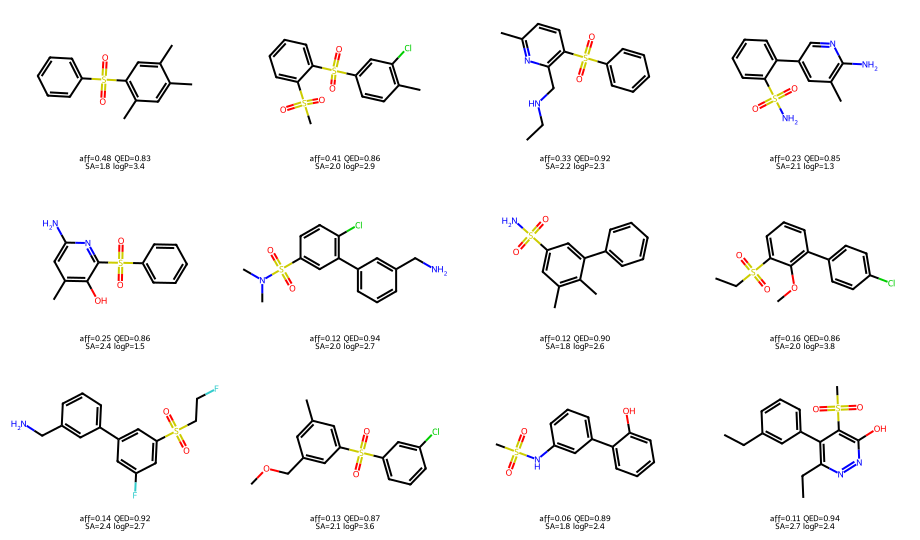

In [47]:
if len(df_gen) >= 5:
    top = df_gen.sort_values("scalar", ascending=False).head(12)
    display(top[["smiles", "affinity", "qed", "sa", "logp", "n_alerts", "mw", "scalar"]]
            .round(3).reset_index(drop=True))

    mols_top = [Chem.MolFromSmiles(s) for s in top["smiles"]]
    legends = [f"aff={r.affinity:.2f} QED={r.qed:.2f}\nSA={r.sa:.1f} logP={r.logp:.1f}"
               for r in top.itertuples()]
    img = Draw.MolsToGridImage(mols_top, molsPerRow=4, subImgSize=(230, 180), legends=legends)
    display(img)

### 10.1 The nearest training molecule — is the model memorising?

Even a 100% novelty rate does not prove the molecules are not *trivial variations* of the
training set. For each candidate we measure the Tanimoto similarity of its nearest neighbour in
the training set. Very high similarity (>0.8) signals memorisation; very low (<0.2) signals
chemically irrelevant generation.

  saved fig7.png  2407x1220 px  -> 602 dpi at 4.0" wide


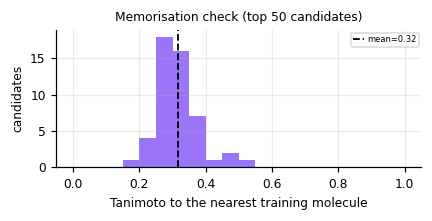

mean nearest-neighbour similarity: 0.316  (above 0.85: 0/50)


In [48]:
if len(df_gen) >= 5:
    train_list = sorted(TRAIN_SMILES)[:6000]
    train_fps = [FPGEN.GetFingerprint(Chem.MolFromSmiles(s)) for s in train_list]
    top = df_gen.sort_values("scalar", ascending=False).head(50)
    nn_sim, nn_smi = [], []
    for s in top["smiles"]:
        fp = FPGEN.GetFingerprint(Chem.MolFromSmiles(s))
        sims = DataStructs.BulkTanimotoSimilarity(fp, train_fps)
        k = int(np.argmax(sims)); nn_sim.append(sims[k]); nn_smi.append(train_list[k])
    fig, ax = plt.subplots(figsize=(5, 2.6))
    ax.hist(nn_sim, bins=20, range=(0, 1), color=PALETTE[4], alpha=.85)
    ax.axvline(np.mean(nn_sim), color="k", ls="--", lw=1.2, label=f"mean={np.mean(nn_sim):.2f}")
    ax.set_xlabel("Tanimoto to the nearest training molecule"); ax.set_ylabel("candidates")
    ax.legend(fontsize=7); ax.set_title("Memorisation check (top 50 candidates)", fontsize=9)
    plt.tight_layout(); save_fig(fig, "fig7"); plt.show()
    print(f"mean nearest-neighbour similarity: {np.mean(nn_sim):.3f}  "
          f"(above 0.85: {sum(s > 0.85 for s in nn_sim)}/50)")

In [49]:
# The output of Part A: the input of every section that follows
if stage_done("A") and "df_gen" not in dir():
    df_gen = pd.read_csv(ART["A"])
    print(f"generated molecules from cache: {len(df_gen)}")
elif "df_gen" in dir() and len(df_gen):
    df_gen.to_csv(ART["A"], index=False)
    print(f"saved {len(df_gen)} molecules -> {ART['A']}")
display(df_gen.head(5).round(3))

saved 9989 molecules -> generated_candidates.csv


,smiles,affinity,qed,logp,sa,mw,tpsa,n_alerts,n_rings,n_heavy,obj_affinity,obj_qed,obj_safety,obj_synth,obj_logp_win,scalar,is_pareto
0,BrC1(Br)Nc2c3c4nc(c2O1)CC(C4)C3,0.062,0.586,2.558,5.611,331.995,34.15,2,4,15,0.062,0.586,0.333,0.488,1.00,0.494,False
1,BrC12C3COC14C1NC(OC4O3)C2[NH2+]1,0.093,0.488,-2.155,7.362,262.083,56.33,2,6,14,0.093,0.488,0.333,0.293,0.11,0.264,False
2,BrC12c3c4cc5c(c3NC1N5)C2C4,0.081,0.673,2.107,6.492,235.084,24.06,2,7,13,0.081,0.673,0.333,0.390,1.00,0.495,False
3,BrC1=C2C=CC3=C1SCC23,0.118,0.596,2.836,5.684,213.099,0.00,0,3,10,0.118,0.596,1.000,0.480,1.00,0.639,False
4,BrC1C2C3COC4=[SH]1=NC2C4C3,0.087,0.386,1.050,7.450,248.145,21.59,6,4,12,0.087,0.386,0.143,0.283,1.00,0.380,False


# B · Docking

We move from a ligand-based affinity proxy to a **structure-based** reward. The order matters: first prove the setup is correct (redocking RMSD), then measure whether the signal discriminates, and only then interpret the generated molecules.

### 0.1 A two-backend Vina wrapper

The Python bindings and the static binary are wrapped behind the same interface, so the rest of
the notebook does not need to know which one is running. On the binary path, scores are read
from the `REMARK VINA RESULT` lines of the output PDBQT.

Validation: docking the same three ligands through both backends gives scores that agree within
0.15 kcal/mol — the difference is the run-to-run noise of Vina's stochastic search.

In [50]:
_RESULT_RE = re.compile(r"REMARK\s+VINA\s+RESULT:\s+(-?\d+\.\d+)")


def parse_pdbqt_scores(text):
    return [float(m) for m in _RESULT_RE.findall(text)]


def split_models(text):
    out, cur = [], []
    for line in text.splitlines(True):
        if line.startswith("MODEL"):
            cur = []
        elif line.startswith("ENDMDL"):
            if cur:
                out.append("".join(cur))
            cur = []
        else:
            cur.append(line)
    if cur and not out:
        out.append("".join(cur))
    return out


class VinaCLI:
    """Mimics the surface of vina.Vina that we use, on top of the static binary."""

    def __init__(self, receptor_pdbqt, center, box_size, cpu=0, seed=42):
        self.receptor, self.center, self.size = receptor_pdbqt, list(center), list(box_size)
        self.cpu, self.seed = cpu, seed
        self._ligand, self._poses, self._energies = None, "", []

    def set_ligand_from_string(self, pdbqt_text):
        self._ligand, self._poses, self._energies = pdbqt_text, "", []

    def dock(self, exhaustiveness=4, n_poses=4):
        with tempfile.TemporaryDirectory() as td:
            lig, out = os.path.join(td, "l.pdbqt"), os.path.join(td, "o.pdbqt")
            open(lig, "w").write(self._ligand)
            cmd = ["vina", "--receptor", self.receptor, "--ligand", lig, "--out", out,
                   "--center_x", f"{self.center[0]:.3f}", "--center_y", f"{self.center[1]:.3f}",
                   "--center_z", f"{self.center[2]:.3f}", "--size_x", f"{self.size[0]:.2f}",
                   "--size_y", f"{self.size[1]:.2f}", "--size_z", f"{self.size[2]:.2f}",
                   "--exhaustiveness", str(exhaustiveness), "--num_modes", str(n_poses),
                   "--seed", str(self.seed)]
            if self.cpu:
                cmd += ["--cpu", str(self.cpu)]
            r = subprocess.run(cmd, capture_output=True, text=True, timeout=600)
            if not os.path.exists(out):
                raise RuntimeError(f"vina CLI failed: {(r.stderr or r.stdout)[-300:]}")
            self._poses = open(out).read()
        self._energies = parse_pdbqt_scores(self._poses)
        if not self._energies:
            raise RuntimeError("no score in the vina output")
        return self._energies

    def energies(self, n_poses=1):
        return [[e, 0.0, 0.0] for e in self._energies[:n_poses]]

    def poses(self, n_poses=1):
        return "".join(f"MODEL {i+1}\n{m}ENDMDL\n"
                       for i, m in enumerate(split_models(self._poses)[:n_poses]))


def make_vina(receptor_pdbqt, center, box_size, cpu=0, seed=42):
    """Uses whichever backend is available; the caller sees no difference."""
    if VINA_BACKEND == "python":
        from vina import Vina
        v = Vina(sf_name="vina", cpu=cpu, seed=seed, verbosity=0)
        v.set_receptor(receptor_pdbqt)
        v.compute_vina_maps(center=list(center), box_size=list(box_size))
        return v
    return VinaCLI(receptor_pdbqt, center, box_size, cpu=cpu, seed=seed)

## 1. Receptor preparation

Three steps, each with a reason:

1. **mmCIF → PDB** (`gemmi`). RCSB now distributes mmCIF by default; alternative conformations
   are cleaned up.
2. **Separating protein / ligand / solvent.** Waters, buffers, ions and cryoprotectants are
   discarded; the **crystal ligand is kept aside** — because it is what defines the docking box.
3. **Protonation and PDBQT.** Open Babel adds hydrogens at pH 7.4 and converts to the PDBQT
   format Vina reads.

> **Defining the box from the crystal ligand is critical.** Guessing pocket coordinates by hand
> is the most common silent error in docking: if the box is displaced, the scores still look
> plausible but mean nothing. With a bound ligand present, the box is not a matter of opinion.

> **Note:** 1HSG is a **homodimer** and the protease active site lies at the *interface* of the
> two chains — take a single chain and the pocket is halved. 1VRT is a p66/p51 heterodimer. In
> both structures all chains are kept.

In [51]:
SKIP_HET = {"HOH", "WAT", "SO4", "PO4", "GOL", "EDO", "PEG", "MPD", "ACT", "CL",
            "NA", "K", "MG", "ZN", "CA", "MN", "DMS", "TRS", "IMD", "NO3", "FMT"}


def cif_to_pdb(cif_path, out_pdb):
    import gemmi
    st = gemmi.read_structure(cif_path)
    st.setup_entities(); st.remove_alternative_conformations()
    st.write_pdb(out_pdb)
    return out_pdb


def split_structure(pdb_path, workdir=".", ligand_resname=None):
    """Write the receptor, return the HETATM lines of the crystal ligand."""
    prot, hets = [], {}
    for line in open(pdb_path):
        rec = line[:6]
        if rec == "ATOM  ":
            if line[16] in (" ", "A"):
                prot.append(line)
        elif rec == "HETATM":
            res = line[17:20].strip()
            if res in SKIP_HET or line[16] not in (" ", "A"):
                continue
            hets.setdefault(res, []).append(line)
        elif rec == "TER   ":
            prot.append(line)
    if ligand_resname is None and hets:
        ligand_resname = max(hets, key=lambda k: len(hets[k]))
    rec_path = os.path.join(workdir, os.path.basename(pdb_path).split(".")[0] + "_rec.pdb")
    with open(rec_path, "w") as f:
        f.writelines(prot); f.write("END\n")
    return rec_path, ligand_resname, hets.get(ligand_resname, []), {k: len(v) for k, v in hets.items()}


def coords_from_pdb_lines(lines):
    return np.array([[float(l[30:38]), float(l[38:46]), float(l[46:54])] for l in lines])


def box_from_ligand(lig_lines, padding=5.0, min_size=18.0, max_size=30.0):
    xyz = coords_from_pdb_lines(lig_lines)
    return xyz.mean(0).tolist(), np.clip(xyz.max(0) - xyz.min(0) + 2 * padding,
                                         min_size, max_size).tolist()


def prepare_receptor(rec_pdb, out_pdbqt):
    """Protonate at pH 7.4 and convert to PDBQT (Meeko first, Open Babel as fallback)."""
    workdir = os.path.dirname(out_pdbqt) or "."
    prot_h = os.path.join(workdir, os.path.basename(rec_pdb).replace(".pdb", "_h.pdb"))
    subprocess.run(["obabel", rec_pdb, "-O", prot_h, "-h", "-p", "7.4"],
                   capture_output=True, text=True)
    src = prot_h if os.path.exists(prot_h) and os.path.getsize(prot_h) else rec_pdb
    base = out_pdbqt[:-6] if out_pdbqt.endswith(".pdbqt") else out_pdbqt
    r = subprocess.run([sys.executable, "-m", "meeko.cli.mk_prepare_receptor",
                        "--read_pdb", src, "-o", base, "-p", "--allow_bad_res",
                        "--default_altloc", "A"], capture_output=True, text=True)
    if os.path.exists(out_pdbqt) and os.path.getsize(out_pdbqt) > 1000:
        return out_pdbqt, "meeko"
    # Meeko stops on residues it has no template for (modified amino acids and so on);
    # Open Babel is more tolerant and is sufficient for a rigid receptor.
    subprocess.run(["obabel", src, "-O", out_pdbqt, "-xr"], capture_output=True, text=True)
    if os.path.exists(out_pdbqt) and os.path.getsize(out_pdbqt) > 1000:
        return out_pdbqt, "openbabel"
    raise RuntimeError("the receptor PDBQT could not be produced")

In [52]:
import glob, collections
prepared = {}
for pdb_id in TARGETS:
    src = (glob.glob(f"{STRUCT_DIR}/*{pdb_id}*.cif") + glob.glob(f"{STRUCT_DIR}/*{pdb_id}*.pdb"))
    if not src:
        raise FileNotFoundError(
            f"no structure file found for {pdb_id} ({STRUCT_DIR}/*{pdb_id}*.cif or *.pdb). "
            "We stop here rather than skipping silently: a missing target turns into an "
            "empty-figure error further down.")
    src = src[0]
    pdb = cif_to_pdb(src, f"{pdb_id}.pdb") if src.endswith(".cif") else src
    rec, lig, lines, hets = split_structure(pdb)
    pq, how = prepare_receptor(rec, f"{pdb_id}_rec.pdbqt")
    center, size = box_from_ligand(lines)
    ch = collections.Counter(l[21] for l in open(rec) if l.startswith("ATOM"))
    prepared[pdb_id] = dict(receptor=pq, center=center, size=size,
                            lig_lines=lines, lig_res=lig)
    print(f"{pdb_id} — {TARGETS[pdb_id]['name']}")
    print(f"   chains {dict(ch)} ({sum(ch.values())} atoms) · hetero {hets}")
    print(f"   crystal ligand {lig} ({len(lines)} atoms) · PDBQT: {how}")
    print(f"   box centre {np.round(center,2).tolist()}  size {np.round(size,1).tolist()}")

assert prepared, "no target could be prepared"
print(f"\nprepared targets: {list(prepared)}")

1HSG — HIV-1 protease
   chains {'A': 757, 'B': 757} (1514 atoms) · hetero {'MK1': 45}
   crystal ligand MK1 (45 atoms) · PDBQT: meeko
   box centre [13.07, 22.47, 5.56]  size [24.9, 20.2, 18.6]
1VRT — HIV-1 reverse transcriptase
   chains {'A': 4302, 'B': 3317} (7619 atoms) · hetero {'CSD': 8, 'NVP': 20}
   crystal ligand NVP (20 atoms) · PDBQT: meeko
   box centre [1.57, -36.68, 22.3]  size [18.0, 18.0, 18.0]

prepared targets: ['1HSG', '1VRT']


## 2. Validate the setup — redocking RMSD

This is the **gate that must be passed.** We dock the crystal ligand back into its own pocket
and measure how far the recovered pose is from the experimental one. The accepted criterion in
the literature is **RMSD < 2 Å**. No docking score should be interpreted before this test
passes: a misplaced box, missing hydrogens or a broken receptor preparation all turn the scores
into numbers that look "reasonable" and mean nothing.

The test needs no SMILES — the crystal atoms themselves are prepared and re-docked.

In [53]:
def pose_heavy_coords(pdbqt_text):
    xyz = []
    for l in pdbqt_text.splitlines():
        if l.startswith(("ATOM", "HETATM")):
            el = (l[77:79].strip() or l[12:16].strip()[0]).upper()
            if el.startswith("H"):
                continue
            xyz.append([float(l[30:38]), float(l[38:46]), float(l[46:54])])
    return np.array(xyz)


def nn_rmsd(ref, pose):
    """Nearest-neighbour RMSD — a robust redocking metric that needs no atom mapping."""
    d = np.linalg.norm(ref[:, None, :] - pose[None, :, :], axis=-1)
    return float(np.sqrt((d.min(1) ** 2).mean()))


def redock_crystal_ligand(lig_lines, vina_obj, workdir=".", exhaustiveness=16):
    ref = coords_from_pdb_lines([l for l in lig_lines
                                 if not (l[76:78].strip() or l[12:16].strip()[0]).upper().startswith("H")])
    lp, lq = os.path.join(workdir, "_xtal.pdb"), os.path.join(workdir, "_xtal.pdbqt")
    with open(lp, "w") as f:
        f.writelines(lig_lines); f.write("END\n")
    subprocess.run(["obabel", lp, "-O", lq, "-h", "--partialcharge", "gasteiger"],
                   capture_output=True, text=True)
    vina_obj.set_ligand_from_string(open(lq).read())
    vina_obj.dock(exhaustiveness=exhaustiveness, n_poses=5)
    energies = vina_obj.energies(n_poses=5)
    blocks = [b for b in vina_obj.poses(n_poses=5).split("MODEL") if "ATOM" in b or "HETATM" in b]
    rmsds = [nn_rmsd(ref, pose_heavy_coords(b)) for b in blocks if len(pose_heavy_coords(b))]
    return {"top_rmsd": rmsds[0], "best_rmsd": min(rmsds),
            "top_energy": float(energies[0][0]), "n_atoms": len(ref)}


validation = {}
for pdb_id, P in prepared.items():
    v = make_vina(P["receptor"], P["center"], P["size"], cpu=0, seed=42)
    r = redock_crystal_ligand(P["lig_lines"], v)
    validation[pdb_id] = r
    flag = "PASS" if r["top_rmsd"] < 2.0 else "FAIL"
    print(f"{pdb_id} ({TARGETS[pdb_id]['drug']}): top RMSD = {r['top_rmsd']:.2f} Å  "
          f"best pose = {r['best_rmsd']:.2f} Å  energy = {r['top_energy']:.2f} kcal/mol  -> {flag}")

1HSG (indinavir): top RMSD = 0.31 Å  best pose = 0.31 Å  energy = -11.52 kcal/mol  -> PASS
1VRT (nevirapine): top RMSD = 0.31 Å  best pose = 0.31 Å  energy = -10.89 kcal/mol  -> PASS


## 3. The docking oracle

The ligand path: SMILES → a 3D conformer from RDKit ETKDGv3 → MMFF94 optimisation →
Meeko PDBQT → Vina.

### 3.1 3D embeddability — a stricter validity filter

Something Part A could not catch shows up here: a molecule can pass RDKit
sanitisation (it is perfectly valid in 2D) and yet have **no 3D coordinates at all**. Strained
fused/bridged ring systems collapse at exactly this point. Docking therefore gives us a free
physics filter: *validity ≠ realisability*.

We report that rate separately for the generated and the training molecules.

In [54]:
def ligand_pdbqt(smiles, seed=0xF00D):
    """SMILES -> 3D -> PDBQT. Also returns the failure reason (for the statistics)."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None, "parse_failed"
    mol = Chem.AddHs(mol)
    ok = False
    for attempt in range(2):                       # escalating embedding
        ps = AllChem.ETKDGv3()
        ps.randomSeed = seed + attempt
        ps.useSmallRingTorsions = True
        if attempt >= 1:
            ps.useRandomCoords = True; ps.maxIterations = 200
        try:
            # RDKit's distance-geometry BFGS can raise an invariant violation on the C++
            # side for strained geometries ("bad direction in linearSearch"). That is a
            # RuntimeError rather than a Python exception; unwrapped, it takes down the
            # whole active-learning run. A failed embedding is a RESULT (the molecule is
            # not realisable in 3D), not a reason to crash.
            if AllChem.EmbedMolecule(mol, ps) == 0:
                ok = True; break
        except (RuntimeError, ValueError, Exception):
            continue
    if not ok:
        return None, "embed_failed"                # geometry that cannot be realised in 3D
    try:
        AllChem.MMFFOptimizeMolecule(mol, maxIters=400)
    except Exception:
        pass
    try:
        setups = MoleculePreparation().prepare(mol)
        pdbqt, good, _ = PDBQTWriterLegacy.write_string(setups[0])
        return (pdbqt, None) if good else (None, "meeko_failed")
    except Exception:
        return None, "meeko_exception"


class DockingOracle:
    """SMILES -> Vina binding energy (kcal/mol). Results are cached."""

    def __init__(self, receptor_pdbqt, center, box_size, exhaustiveness=4,
                 n_poses=4, cpu=0, seed=42):
        self.v = make_vina(receptor_pdbqt, center, box_size, cpu=cpu, seed=seed)
        self.exh, self.n_poses = exhaustiveness, n_poses
        self.cache, self.n_calls, self.fails, self.t = {}, 0, {}, 0.0

    def __call__(self, smiles):
        if smiles in self.cache:
            return self.cache[smiles]
        pdbqt, err = ligand_pdbqt(smiles)
        if pdbqt is None:
            self.fails[err] = self.fails.get(err, 0) + 1
            self.cache[smiles] = None
            return None
        t0 = time.time()
        try:
            self.v.set_ligand_from_string(pdbqt)
            self.v.dock(exhaustiveness=self.exh, n_poses=self.n_poses)
            e = float(self.v.energies(n_poses=1)[0][0])
        except Exception:
            self.fails["vina_exception"] = self.fails.get("vina_exception", 0) + 1
            self.cache[smiles] = None
            return None
        self.n_calls += 1; self.t += time.time() - t0
        self.cache[smiles] = e
        return e

    def score_many(self, smiles, log_every=50, label=""):
        out = []
        t0 = time.time()
        for i, s in enumerate(smiles):
            out.append(self(s))
            if log_every and (i + 1) % log_every == 0:
                ok = [x for x in out if x is not None]
                print(f"    {label} {i+1}/{len(smiles)}  success={len(ok)/(i+1):.2f}  "
                      f"mean={np.mean(ok):.2f}  best={min(ok):.2f}  "
                      f"{(time.time()-t0)/(i+1):.1f} s/ligand", flush=True)
        return out


oracles = {}
for pdb_id, P in prepared.items():
    oracles[pdb_id] = DockingOracle(P["receptor"], P["center"], P["size"],
                                    exhaustiveness=EXHAUSTIVENESS)
print("docking oracles ready:", list(oracles))

docking oracles ready: ['1HSG', '1VRT']


### 3.2 The `exhaustiveness` budget

Vina's search intensity is a direct cost. Measured (5 ligands, same receptor):

| exhaustiveness | time / ligand | scores |
|---|---|---|
| 4 | 5.6 s | −6.73, −5.80, −5.60, −6.52 |
| 8 | 8.4 s | −6.71, −5.80, −5.60, −6.52 |
| 16 | 14.1 s | −6.72, −5.87, −5.60, −6.52 |

The scores agree within 0.1 kcal/mol; **4 is enough** and is 2.5× faster. That is the expected
behaviour at this molecular size (~17 heavy atoms, few rotatable bonds) — large, flexible
ligands need a higher exhaustiveness. The redocking validation still uses 16, because there the
goal is to find the best pose.

## 4. Is the docking signal discriminative?

We have to ask this **before** putting it in the reward. We dock known HIV actives and inactives
and look at whether the scores separate.

**Let us calibrate the expectation up front.** This test will probably come out weak, and there
are two separate reasons — which should not be conflated:

1. **Docking scoring is a weak ranker to begin with.** A Vina score is not a free-energy
   *calculation* but a crude empirical function; entropy, solvent effects and protein flexibility
   are largely neglected. In the literature, docking's enrichment performance swings between
   ROC-AUC 0.5 and 0.8 depending on the target.
2. **HIV.csv is phenotypic screening data.** The label answers "does this compound inhibit HIV
   replication in cells" — not *does it bind the protease*. The actives may work through **any**
   mechanism, including reverse transcriptase, integrase, entry inhibition or cellular toxicity.
   So there is no *a priori* reason for docking against a single target to separate that label
   well.

That is, a low AUC does not mean "docking is broken"; it means "this label is not a single-target
binding measurement". The distinction directly determines how we put the docking score into the
reward.

In [55]:
df_dock = {}
for pdb_id in prepared:
    f = f"dock_{pdb_id}.csv"
    if os.path.exists(f):
        df_dock[pdb_id] = pd.read_csv(f)
        print(f"{pdb_id}: loaded {len(df_dock[pdb_id])} precomputed docking results")
    else:
        print(f"{pdb_id}: no docking result — the cell below will compute it")

1HSG: loaded 350 precomputed docking results
1VRT: loaded 350 precomputed docking results


In [56]:
# If there is no result file, it is computed here (slow: ~10-16 s/ligand).
N_GEN, N_KNOWN = (60, 40) if QUICK else (150, 100)
if not df_dock and not oracles:
    raise RuntimeError("oracles is empty — the oracle setup in section 3 was not run.")
if not df_dock:
    print(f"no cached result; {N_GEN + 2*N_KNOWN} ligands will be docked "
          f"(~{(N_GEN + 2*N_KNOWN) * 8 / 60:.0f} min/target). QUICK={QUICK}", flush=True)
    rng = np.random.default_rng(0)
    gen_all = pd.read_csv(GENERATED_CSV)
    hiv = pd.read_csv(HIV_CSV)

    def size_ok(s):
        m = Chem.MolFromSmiles(s)
        return m is not None and 5 <= m.GetNumHeavyAtoms() <= 30 and "." not in s

    top = gen_all.sort_values("scalar", ascending=False).head(N_GEN // 2)["smiles"].tolist()
    rest = gen_all[~gen_all["smiles"].isin(top)]["smiles"].tolist()
    gen_smi = top + list(rng.choice(rest, N_GEN - len(top), replace=False))
    act = [s for s in hiv[hiv.HIV_active == 1]["smiles"] if size_ok(s)]
    ina = [s for s in hiv[hiv.HIV_active == 0]["smiles"] if size_ok(s)]
    act = list(rng.choice(act, min(N_KNOWN, len(act)), replace=False))
    ina = list(rng.choice(ina, min(N_KNOWN, len(ina)), replace=False))
    rows = ([("generated", s) for s in gen_smi] + [("known_active", s) for s in act] +
            [("known_inactive", s) for s in ina])
    for pdb_id, orc in oracles.items():
        t0 = time.time()
        scores = orc.score_many([s for _, s in rows], label=pdb_id)
        d = pd.DataFrame({"group": [g for g, _ in rows], "smiles": [s for _, s in rows],
                          "dock": scores})
        d["n_heavy"] = [Chem.MolFromSmiles(s).GetNumHeavyAtoms() for s in d["smiles"]]
        d.to_csv(f"dock_{pdb_id}.csv", index=False)
        df_dock[pdb_id] = d
        ok = d["dock"].notna().sum()
        print(f"{pdb_id}: {time.time()-t0:.0f}s  scored={ok}/{len(d)}  failure breakdown={orc.fails}")
        if ok == 0:
            raise RuntimeError(f"{pdb_id}: no ligand could be scored — failures: {orc.fails}")

In [57]:
# Everything below depends on df_dock. If it is empty, say why here.
if not df_dock:
    raise RuntimeError(
        "df_dock is empty — there are no docking results.\n"
        f"  prepared targets: {list(prepared)}\n"
        f"  files found     : {[f for f in ('dock_1HSG.csv','dock_1VRT.csv') if os.path.exists(f)]}\n"
        "Possible causes:\n"
        "  1) The computation cell above was not run (if it was skipped for being slow, run it, "
        "or put ready-made dock_*.csv files in the working directory).\n"
        "  2) The computation cell ran but no ligand could be scored — 'oracles' may be empty "
        "or ligand preparation failed entirely.\n"
        "  3) N_GEN/N_KNOWN were left too small while QUICK=True.")

rows = []
for pdb_id, d in df_dock.items():
    for g, sub in d.groupby("group"):
        v = sub["dock"].dropna()
        rows.append({"target": pdb_id, "group": g, "n": len(sub),
                     "3D_success": sub["dock"].notna().mean(),
                     "mean": v.mean(), "median": v.median(),
                     "best": v.min(), "std": v.std(),
                     "heavy_atoms": sub["n_heavy"].mean()})
summary = pd.DataFrame(rows)
display(summary.round(3))

print("\nReference drugs (redocked from the crystal pose):")
for pdb_id, r in validation.items():
    print(f"  {TARGETS[pdb_id]['drug']:12s} ({pdb_id}): {r['top_energy']:.2f} kcal/mol")

,target,group,n,3D_success,mean,median,best,std,heavy_atoms
0,1HSG,generated,150,0.86,-6.692,-6.859,-8.439,0.823,17.76
1,1HSG,known_active,100,0.93,-7.618,-7.589,-10.450,1.133,21.12
2,1HSG,known_inactive,100,0.99,-7.703,-7.706,-10.849,1.379,21.80
3,1VRT,generated,150,0.86,-8.237,-8.390,-10.513,1.192,17.76
4,1VRT,known_active,100,0.93,-8.487,-8.442,-12.619,1.287,21.12
5,1VRT,known_inactive,100,0.99,-8.403,-8.610,-11.819,1.793,21.80



Reference drugs (redocked from the crystal pose):
  indinavir    (1HSG): -11.52 kcal/mol
  nevirapine   (1VRT): -10.89 kcal/mol


  saved fig8.png  3787x2652 px  -> 601 dpi at 6.3" wide


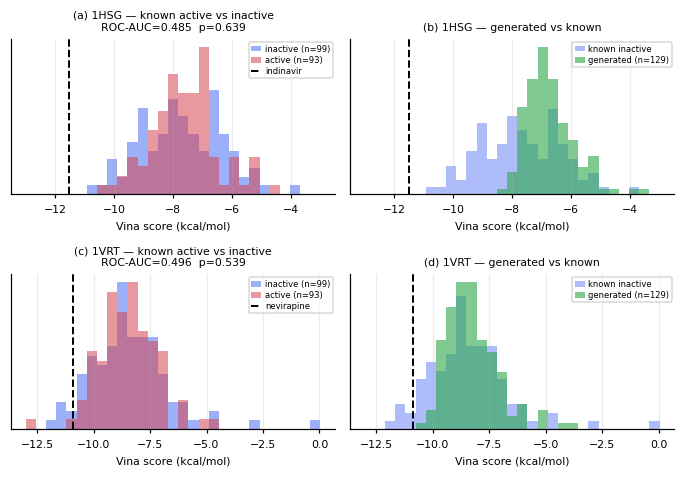

,target,ROC_AUC,p,Δmean
0,1HSG,0.4852,0.6391,0.0854
1,1VRT,0.4960,0.5388,-0.0847


In [58]:
assert df_dock, "df_dock is empty — see the error message of the cell above"
fig, axes = plt.subplots(len(df_dock), 2, figsize=(10, 3.5 * len(df_dock)),
                         squeeze=False)
axes = axes.ravel()
auc_rows = []
for k, (pdb_id, d) in enumerate(df_dock.items()):
    act = d[d.group == "known_active"]["dock"].dropna()
    ina = d[d.group == "known_inactive"]["dock"].dropna()
    gen = d[d.group == "generated"]["dock"].dropna()

    ax = axes[2 * k]
    bins = np.linspace(min(d["dock"].min(), -13), max(d["dock"].max(), -3), 30)
    ax.hist(ina, bins=bins, alpha=.55, density=True, color=PALETTE[0], label=f"inactive (n={len(ina)})")
    ax.hist(act, bins=bins, alpha=.55, density=True, color=PALETTE[3], label=f"active (n={len(act)})")
    ax.axvline(validation[pdb_id]["top_energy"], color="k", ls="--", lw=1.3,
               label=TARGETS[pdb_id]["drug"])
    ax.set_xlabel("Vina score (kcal/mol)"); ax.set_yticks([])
    ax.legend(fontsize=7)

    if len(act) > 5 and len(ina) > 5:
        y = np.r_[np.ones(len(act)), np.zeros(len(ina))]
        s = np.r_[-act.values, -ina.values]                 # more negative = better
        auc = roc_auc_score(y, s)
        u = stats.mannwhitneyu(act, ina, alternative="less")
        ax.set_title(f"{pdb_id} — known active vs inactive\nROC-AUC={auc:.3f}  p={u.pvalue:.3g}",
                     fontsize=9)
        auc_rows.append({"target": pdb_id, "ROC_AUC": auc, "p": u.pvalue,
                         "Δmean": act.mean() - ina.mean()})

    ax = axes[2 * k + 1]
    ax.hist(ina, bins=bins, alpha=.45, density=True, color=PALETTE[0], label="known inactive")
    ax.hist(gen, bins=bins, alpha=.6, density=True, color=PALETTE[2], label=f"generated (n={len(gen)})")
    ax.axvline(validation[pdb_id]["top_energy"], color="k", ls="--", lw=1.3)
    ax.set_xlabel("Vina score (kcal/mol)"); ax.set_yticks([])
    ax.legend(fontsize=7); ax.set_title(f"{pdb_id} — generated vs known", fontsize=9)
plt.tight_layout(); save_fig(fig, "fig8"); plt.show()
if auc_rows:
    display(pd.DataFrame(auc_rows).round(4))

## 5. Ligand efficiency — taking the size effect out

Comparing raw docking scores is misleading: a Vina score grows almost linearly with molecular
size, because every extra heavy atom adds contact surface. Indinavir has 45 heavy atoms; ours
have ~17. On the raw score indinavir wins — but that is arithmetic, not a *chemical* advantage.

The fair metric is **ligand efficiency**:

$$\text{LE} = \frac{-\Delta G_{\text{bind}}}{N_{\text{heavy atoms}}} \quad [\text{kcal/mol / atom}]$$

For a fragment to start optimisation from, LE ≳ 0.3 is considered good. Looking at LE separates
small but efficient binders from large, bulky ones — it is the core metric of fragment-based
drug design.

  saved fig9.png  3791x2647 px  -> 602 dpi at 6.3" wide


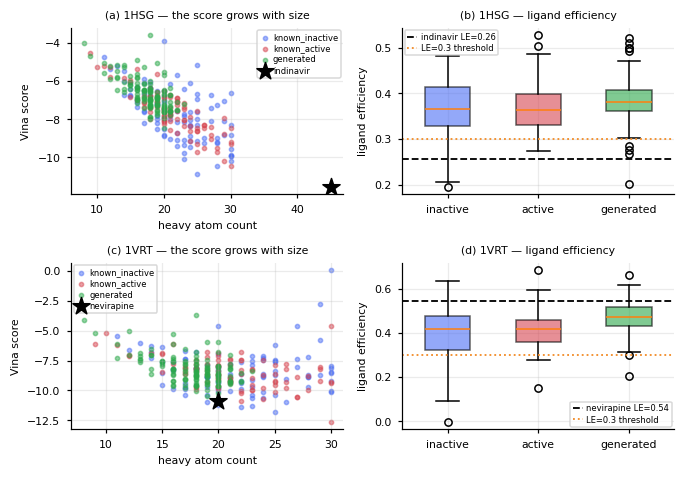

,target,group,LE_mean,LE_median,LE_max,LE>0.3 fraction
0,1HSG,known_active,0.368,0.363,0.527,0.968
1,1HSG,known_inactive,0.363,0.366,0.483,0.838
2,1HSG,generated,0.384,0.381,0.521,0.969
3,1VRT,known_active,0.414,0.416,0.682,0.957
4,1VRT,known_inactive,0.404,0.417,0.636,0.848
5,1VRT,generated,0.472,0.470,0.664,0.984


In [59]:
assert df_dock, "df_dock is empty"
fig, ax = plt.subplots(len(df_dock), 2, figsize=(10, 3.5 * len(df_dock)), squeeze=False)
ax = ax.ravel()
le_rows = []
for k, (pdb_id, d) in enumerate(df_dock.items()):
    d = d.dropna(subset=["dock"]).copy()
    d["LE"] = -d["dock"] / d["n_heavy"]
    a = ax[2 * k]
    for g, col in [("known_inactive", PALETTE[0]), ("known_active", PALETTE[3]),
                   ("generated", PALETTE[2])]:
        sub = d[d.group == g]
        if len(sub):
            a.scatter(sub["n_heavy"], sub["dock"], s=12, alpha=.5, color=col, label=g)
    ref_e = validation[pdb_id]["top_energy"]
    ref_n = validation[pdb_id]["n_atoms"]
    a.scatter([ref_n], [ref_e], marker="*", s=220, color="k", zorder=5,
              label=TARGETS[pdb_id]["drug"])
    a.set_xlabel("heavy atom count"); a.set_ylabel("Vina score")
    a.legend(fontsize=6); a.set_title(f"{pdb_id} — the score grows with size", fontsize=9)

    a = ax[2 * k + 1]
    data = [d[d.group == g]["LE"].values for g in ["known_inactive", "known_active", "generated"]]
    lab = [g for g, x in zip(["inactive", "active", "generated"], data) if len(x)]
    try:
        bp = a.boxplot([x for x in data if len(x)], tick_labels=lab,
                       patch_artist=True, widths=.5)
    except TypeError:                       # matplotlib < 3.9
        bp = a.boxplot([x for x in data if len(x)], labels=lab,
                       patch_artist=True, widths=.5)
    for patch, col in zip(bp["boxes"], [PALETTE[0], PALETTE[3], PALETTE[2]]):
        patch.set_facecolor(col); patch.set_alpha(.6)
    a.axhline(-ref_e / ref_n, color="k", ls="--", lw=1.2,
              label=f"{TARGETS[pdb_id]['drug']} LE={-ref_e/ref_n:.2f}")
    a.axhline(0.3, color=PALETTE[1], ls=":", lw=1.2, label="LE=0.3 threshold")
    a.set_ylabel("ligand efficiency"); a.legend(fontsize=6)
    a.set_title(f"{pdb_id} — ligand efficiency", fontsize=9)
    for g in ["known_active", "known_inactive", "generated"]:
        s = d[d.group == g]["LE"]
        if len(s):
            le_rows.append({"target": pdb_id, "group": g, "LE_mean": s.mean(),
                            "LE_median": s.median(), "LE_max": s.max(),
                            "LE>0.3 fraction": (s > 0.3).mean()})
plt.tight_layout(); save_fig(fig, "fig9"); plt.show()
display(pd.DataFrame(le_rows).round(3))

## 6. The docking surrogate model

Docking costs ~10–16 seconds per ligand. An RL loop wants tens of thousands of evaluations —
docking directly is impossible. The solution follows the same logic as the reward net in Part A:
**a cheap surrogate trained by regression onto the real oracle**, audited periodically against
real docking.

What matters here is not the surrogate's accuracy *within the training distribution*. The
generator tries to go exactly where the surrogate knows least — wherever the predicted score is
high. So we make two separate measurements:

1. **Held-out correlation** (same distribution): how well did the surrogate learn?
2. **Out-of-distribution test**: on molecules the generator has *newly* produced, how well does
   the surrogate prediction agree with real docking? When those two diverge, reward hacking has
   begun.

,target,n_train,n_test,Pearson_r,Spearman_ρ,MAE,y_std
0,1HSG,240,81,0.776,0.83,0.480,1.132
1,1VRT,240,81,0.614,0.67,0.701,1.249


  saved fig10.png  3007x1195 px  -> 601 dpi at 5.0" wide


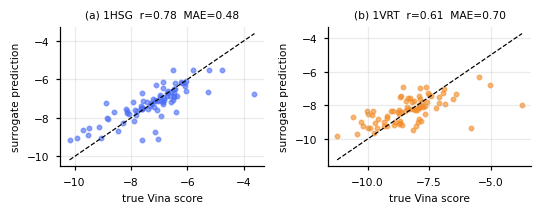

In [60]:
FPGEN = AllChem.GetMorganGenerator(radius=2, fpSize=2048)

def fp_matrix(smiles):
    X = np.zeros((len(smiles), 2048), dtype=np.uint8)
    for i, s in enumerate(smiles):
        m = Chem.MolFromSmiles(s)
        if m is not None:
            DataStructs.ConvertToNumpyArray(FPGEN.GetFingerprint(m), X[i])
    return X

def desc_matrix(smiles):
    rows = []
    for s in smiles:
        m = Chem.MolFromSmiles(s)
        rows.append([m.GetNumHeavyAtoms(), Descriptors.MolWt(m), Crippen.MolLogP(m),
                     Descriptors.TPSA(m), Descriptors.NumRotatableBonds(m),
                     Descriptors.RingCount(m), QED.qed(m)] if m else [0]*7)
    return np.array(rows)

surrogates, surro_stats = {}, []
for pdb_id, d in df_dock.items():
    d = d.dropna(subset=["dock"])
    X = np.hstack([fp_matrix(d["smiles"].tolist()), desc_matrix(d["smiles"].tolist())])
    y = d["dock"].values
    idx = np.random.RandomState(0).permutation(len(y))
    cut = int(.75 * len(y))
    tr, te = idx[:cut], idx[cut:]
    rf = RandomForestRegressor(n_estimators=400, min_samples_leaf=2, n_jobs=-1, random_state=0)
    rf.fit(X[tr], y[tr])
    p = rf.predict(X[te])
    surrogates[pdb_id] = rf
    surro_stats.append({"target": pdb_id, "n_train": len(tr), "n_test": len(te),
                        "Pearson_r": np.corrcoef(p, y[te])[0, 1],
                        "Spearman_ρ": stats.spearmanr(p, y[te]).statistic,
                        "MAE": np.abs(p - y[te]).mean(),
                        "y_std": y[te].std()})
display(pd.DataFrame(surro_stats).round(3))

fig, ax = plt.subplots(1, len(df_dock), figsize=(4.2 * len(df_dock), 3.4), squeeze=False)
ax = ax.ravel()
for k, (pdb_id, d) in enumerate(df_dock.items()):
    d = d.dropna(subset=["dock"])
    X = np.hstack([fp_matrix(d["smiles"].tolist()), desc_matrix(d["smiles"].tolist())])
    y = d["dock"].values
    idx = np.random.RandomState(0).permutation(len(y)); cut = int(.75 * len(y))
    p = surrogates[pdb_id].predict(X[idx[cut:]])
    yt = y[idx[cut:]]
    ax[k].scatter(yt, p, s=14, alpha=.6, color=PALETTE[k])
    lo, hi = min(yt.min(), p.min()), max(yt.max(), p.max())
    ax[k].plot([lo, hi], [lo, hi], "k--", lw=.8)
    ax[k].set_xlabel("true Vina score"); ax[k].set_ylabel("surrogate prediction")
    r = surro_stats[k]
    ax[k].set_title(f"{pdb_id}  r={r['Pearson_r']:.2f}  MAE={r['MAE']:.2f}", fontsize=9)
plt.tight_layout(); save_fig(fig, "fig10"); plt.show()

## 7. Tying the docking score into the multi-objective target

We map the Vina score onto $[0,1]$ so that it lives on the same scale as the other objectives:

$$r_{\text{dock}} = \operatorname{clip}\!\left(\frac{-\Delta G - 4}{8},\, 0,\, 1\right)$$

that is, −4 kcal/mol → 0 and −12 kcal/mol → 1. Reference points: indinavir ≈ −11.5, nevirapine
≈ −10.9.

The new objective vector is **six-dimensional**:

$$\mathbf{c} = [\, r_{\text{dock}}^{\text{protease}},\; r_{\text{dock}}^{\text{RT}},\; \text{QED},\; \text{Safety},\; \text{SA}^{-1},\; \text{LogP}_{\text{win}} \,]$$

Keeping the two targets on separate axes is deliberate: collapsing them into a single "affinity"
number would make the **selectivity** question invisible. Kept apart, the Pareto front shows
dual-target compounds (binding both) and selective ones at the same time.

In [61]:
def dock_to_reward(e, lo=-4.0, hi=-12.0):
    if e is None or not np.isfinite(e):
        return 0.0
    return float(np.clip((-e + lo) / (-hi + lo), 0, 1))

for pdb_id, d in df_dock.items():
    v = d["dock"].dropna()
    print(f"{pdb_id}: mean reward={np.mean([dock_to_reward(x) for x in v]):.3f} "
          f"(reference drug {dock_to_reward(validation[pdb_id]['top_energy']):.3f})")

1HSG: mean reward=0.409 (reference drug 0.940)
1VRT: mean reward=0.547 (reference drug 0.861)


## 8. Conclusions and limits

### 8.1 What a docking score does and does not say

- **It does say:** whether the ligand fits the pocket geometrically, and roughly how well shape
  and hydrogen bonding complement each other. If the redocking RMSD is low, that information is
  real.
- **It does not say:** the true binding free energy. The Vina score is empirical; solvent
  reorganisation, conformational entropy and protein flexibility are neglected. Its correlation
  with experimental $\text{pIC}_{50}$ is typically around $r \approx 0.3$–$0.5$.
- **It definitely does not say:** cellular activity. Permeability, efflux, metabolism and
  toxicity never enter here.

### 8.2 The reward-hacking risk is reduced, not eliminated

Compared with a ligand-based RF, docking is a signal that is **harder** for the generator to
exploit: the score is tied to a physical pocket, and while it improves with size that too is
bounded. Known exploits remain:

- **Size inflation.** The score grows with heavy-atom count; the generator can gain score simply
  by growing. Countermeasure: ligand efficiency (section 5) and keeping the QED/SA objectives.
- **Poses that do not fit the pocket but accumulate score.** The rigid-receptor assumption leaves
  some unrealistic contacts unpenalised.
- **The surrogate's blind spot.** The out-of-distribution test in section 6 tracks it; once the
  surrogate and real docking start to diverge, it is time to dock again and update the surrogate.

### 8.3 Where to go from here

| Priority | Step | Why |
|---|---|---|
| **1** | **Rescoring** (MM-GBSA, or ML scorers such as RF-Score / GNINA) | The Vina score's ranking power is weak; a more expensive but more accurate scoring layer over the top 100 candidates is the cheapest improvement available. |
| **2** | **Flexible side chains** or multiple receptor conformations (ensemble docking) | A rigid receptor misses induced fit — the NNRTI pocket of RT in particular only opens once a ligand binds. |
| **3** | **Chemical inspection of the pose** (interaction fingerprints with PLIP) | The score can be good while the pose is nonsense. Candidates should be filtered for reproducing the key interactions the crystal ligand makes (Asp25/Asp25′ in the protease, Tyr181/Tyr188 in RT). |
| **4** | **Move to 3D generation** (TargetDiff, DiffSBDD, Pocket2Mol) | Making docking a *generation condition* instead of an *evaluation*: the molecule is built directly inside the pocket. That is the real continuation of this notebook. |
| **5** | **Experimental validation** | All of this is a computational hypothesis. Without synthesis and an enzyme assay, no score is a claim. |

---

*The generated molecules are computational hypotheses. Docking scores are binding estimates,
not evidence of binding.*

# C · The active-learning loop

Up to here the surrogate model was trained **once** and the generator was then optimised against
it. What that setup measured was unambiguous: on the molecules the generator newly produced, the
surrogate predicted binding **systematically better than reality** — by +0.32 kcal/mol on 1HSG
and +0.53 on 1VRT. The correlation held, so the ranking still worked; but the absolute values
drifted.

That is the textbook signature of reward hacking: the generator goes exactly where the surrogate
**knows least**, because that is where the predictions are most optimistic.

The loop closes it like this:

```
pool ← the initially docked molecules
each round:
    surrogate ← retrain on the pool
    generator ← refine with RL against the surrogate
    candidates ← sample from the generator
    sample ← the K molecules the surrogate likes BEST     ← deliberate: we probe where
    truth ← ACTUALLY dock the sample                        the bias is largest
    pool ← pool + truth
    record: bias, correlation, true score, 3D success
```

Choosing the sample from **the surrogate's favourites** rather than at random is deliberate:
since that is where we expect the largest bias, it makes the loop look straight at its own blind
spot every round.

### C.0 Three guards against over-optimisation

The real danger in this loop is not the surrogate itself but **taking too many steps against
it.** A run at the full budget (150 RL steps per round) showed exactly that:

| Symptom | Healthy run (40 steps) | Collapsed run (150 steps) |
|---|---|---|
| Surrogate reward (within the round) | 0.538 → 0.607 (rising) | 0.515 → **0.351** (falling) |
| Unique candidates / requested | 400 / 400 | **236 / 400** |
| Mean true docking score | −6.51 | **−4.22** |
| Surrogate bias | +0.14 | **−1.21 / −1.78** |

Over-optimised against a surrogate trained on 228 molecules, the generator leaves the data
manifold: the surrogate still thinks it is doing well while real docking gets two kcal/mol worse.
This is reward hacking in its textbook form.

Three guards were added:

1. **Early stopping within a round.** The mean reward is tracked over 20-step windows; if two
   consecutive windows fail to beat the best, the round ends there. (On the falling curve above
   it stops at step 60.)
2. **Round-level rollback.** Every round's *true docking* mean is measured — not the surrogate's
   prediction. If a round is more than 0.25 kcal/mol worse than the best so far, the weights are
   restored to the pre-round snapshot and the next round's step count is halved.
3. **Uniqueness monitoring.** If the fraction of unique generated molecules falls below 0.5 a
   warning is printed; that is the earliest and cheapest indicator of mode collapse.

The full-budget default was also lowered from 150 to **50** steps. Increasing the number of
**rounds** rather than the number of steps is the right move: every round retrains the surrogate,
so the budget goes into more *real measurements* rather than more steps.

In [62]:
def al_featurize(smiles):
    """Input to the surrogate model: Morgan fingerprint + a few descriptors."""
    X = np.zeros((len(smiles), 2048 + 7), dtype=np.float32)
    for i, s in enumerate(smiles):
        m = Chem.MolFromSmiles(s) if s else None
        if m is None:
            continue
        arr = np.zeros(2048, dtype=np.uint8)
        DataStructs.ConvertToNumpyArray(FPGEN.GetFingerprint(m), arr)
        X[i, :2048] = arr
        X[i, 2048:] = [m.GetNumHeavyAtoms(), Descriptors.MolWt(m), Crippen.MolLogP(m),
                       Descriptors.TPSA(m), Descriptors.NumRotatableBonds(m),
                       Descriptors.RingCount(m), QED.qed(m)]
    return X


def dock_to_reward(e, lo=-4.0, hi=-12.0):
    """Map a Vina score onto [0,1]: -4 -> 0, -12 -> 1 (reference: indinavir ~ -11.5)."""
    if e is None or not np.isfinite(e):
        return 0.0
    return float(np.clip((-e + lo) / (-hi + lo), 0, 1))


def fit_surrogate(df, seed=0):
    d = df.dropna(subset=["dock"])
    X, y = al_featurize(d["smiles"].tolist()), d["dock"].values
    idx = np.random.RandomState(seed).permutation(len(y))
    cut = max(5, int(.8 * len(y)))
    rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, n_jobs=-1,
                               random_state=seed)
    rf.fit(X[idx[:cut]], y[idx[:cut]])
    st = {"n": len(y)}
    if len(idx) - cut >= 5:
        p, yt = rf.predict(X[idx[cut:]]), y[idx[cut:]]
        st.update(r=float(np.corrcoef(p, yt)[0, 1]), mae=float(np.abs(p - yt).mean()))
    rf.fit(X, y)                                   # then refit on all the data
    return rf, st


AL_OBJ = ["dock_PR", "dock_RT", "qed", "safety", "synth", "logp_win"]
AL_N_OBJ = len(AL_OBJ)


def al_objectives(smiles_list, surro):
    """Objective vector: affinity is now two DOCKING axes (protease + RT)."""
    mols = [Chem.MolFromSmiles(s) if s else None for s in smiles_list]
    ok = [i for i, m in enumerate(mols) if m is not None
          and m.GetNumHeavyAtoms() >= CFG.min_heavy_atoms]
    R = np.zeros((len(smiles_list), AL_N_OBJ), dtype=np.float32)
    if not ok:
        return R
    X = al_featurize([smiles_list[i] for i in ok])
    pred = {t: surro[t].predict(X) for t in TARGETS}
    for k, i in enumerate(ok):
        p = raw_properties(mols[i])
        R[i] = [dock_to_reward(pred["1HSG"][k]), dock_to_reward(pred["1VRT"][k]),
                p["qed"], 1.0 / (1.0 + p["n_alerts"]),
                float(np.clip((10.0 - p["sa"]) / 9.0, 0, 1)),
                logp_desirability(p["logp"])]
    return R

In [63]:
def al_rl_round(enc, dec, crit, rnet, loader, surro, steps, rng, pref):
    """One round of WGAN-GP + Tchebycheff RL; the reward comes from the current docking surrogate."""
    optG = torch.optim.Adam(list(dec.parameters()) + list(enc.parameters()),
                            lr=1e-4, betas=(.5, .9))
    optD = torch.optim.Adam(crit.parameters(), lr=1e-4, betas=(.5, .9))
    optR = torch.optim.Adam(rnet.parameters(), lr=1e-3)
    BW = torch.tensor([CFG.bond_weight] + [1.0] * (NUM_BOND_TYPES - 1), device=DEVICE)
    it = iter(loader)

    def nb():
        nonlocal it
        try:
            return [t.to(DEVICE) for t in next(it)]
        except StopIteration:
            it = iter(loader); return [t.to(DEVICE) for t in next(it)]

    hist = []
    best_win, bad_checks, WIN = None, 0, 20
    for step in range(steps):
        # Early stopping: taking many steps against a weak surrogate pushes the generator off
        # the data manifold (measured: at 150 steps the reward went 0.515 -> 0.351, uniqueness
        # 400/400 -> 236/400, true docking -6.5 -> -4.2). We stop once the reward window
        # starts regressing.
        if step and step % WIN == 0 and len(hist) >= WIN:
            win = float(np.mean([h[0] for h in hist[-WIN:]]))
            if best_win is None or win > best_win:
                best_win, bad_checks = win, 0
            else:
                bad_checks += 1
                if bad_checks >= 2:
                    print(f"    early stop: step {step}, reward window "
                          f"{win:.3f} < best {best_win:.3f}", flush=True)
                    break
        for _ in range(CFG.n_critic):
            x, a, c = nb()
            Xr, Ar = onehot_batch(x, a)
            with torch.no_grad():
                Xf, Af = gumbel_graph(*dec(torch.randn(len(x), CFG.d_latent, device=DEVICE), c),
                                      tau=CFG.gumbel_tau)
            gp = gradient_penalty(crit, Xr, Ar, Xf, Af)
            lossD = crit(Xf, Af).mean() - crit(Xr, Ar).mean() + CFG.lam_gp * gp
            optD.zero_grad(); lossD.backward(); optD.step()

        x, a, c = nb()
        Xr, Ar = onehot_batch(x, a)
        cg = torch.tensor(rng.uniform(.6, 1., (len(x), AL_N_OBJ)).astype(np.float32),
                          device=DEVICE)
        with torch.no_grad():
            Xf, Af = gumbel_graph(*dec(torch.randn(len(x), CFG.d_latent, device=DEVICE), cg),
                                  tau=CFG.gumbel_tau)
        xp, ap = Xf.cpu().numpy(), Af.cpu().numpy()
        smis = [decode_graph(xp[k], ap[k], rng=rng, cyclo_choices=CYCLO_TRAIN)
                for k in range(len(xp))]
        Rf = al_objectives(smis, surro)
        lossR = F.mse_loss(rnet(torch.cat([Xr, Xf]), torch.cat([Ar, Af])),
                           torch.cat([c, torch.tensor(Rf, device=DEVICE)]))
        optR.zero_grad(); lossR.backward(); optR.step()

        x, a, c = nb()
        Xr, Ar = onehot_batch(x, a)
        cg = torch.tensor(rng.uniform(.6, 1., (len(x), AL_N_OBJ)).astype(np.float32),
                          device=DEVICE)
        Xf, Af = gumbel_graph(*dec(torch.randn(len(x), CFG.d_latent, device=DEVICE), cg),
                              tau=CFG.gumbel_tau)
        adv = -crit(Xf, Af).mean()
        w = torch.tensor(rng.dirichlet(pref * 20 + 1e-6, len(x)).astype(np.float32),
                         device=DEVICE)
        rhat = rnet(Xf, Af)
        rl = -scalarize(rhat, w, "tchebycheff").mean()
        mu, lv = enc(Xr, Ar, c)
        z = mu + torch.randn_like(mu) * (.5 * lv).exp()
        lvae, _, _, _ = vae_loss(*dec(z, c), x, a, mu, lv, CFG.beta_max, BW)
        lossG = CFG.lam_adv * adv + CFG.lam_rl * rl + CFG.lam_vae * lvae
        optG.zero_grad(); lossG.backward()
        nn.utils.clip_grad_norm_(list(dec.parameters()) + list(enc.parameters()), 5.)
        optG.step()
        r = Rf[Rf.sum(1) > 0]
        hist.append([float(rhat.mean()),
                     r[:, 0].mean() if len(r) else 0., r[:, 1].mean() if len(r) else 0.])
    return np.array(hist)


@torch.no_grad()
def al_generate(dec, n, c_goal, rng, tau=None, batch=256):
    tau = tau or CFG.sample_tau
    out, seen, uniq = [], set(), []
    for i in range(0, n, batch):
        b = min(batch, n - i)
        cg = torch.tensor(np.tile(np.asarray(c_goal, dtype=np.float32), (b, 1)), device=DEVICE)
        xl, al = dec(torch.randn(b, CFG.d_latent, device=DEVICE), cg)
        xp = F.softmax(xl / tau, -1).cpu().numpy(); ap = F.softmax(al / tau, -1).cpu().numpy()
        out += [decode_graph(xp[k], ap[k], rng=rng, cyclo_choices=CYCLO_TRAIN)
                for k in range(b)]
    for s in out:
        if not s:
            continue
        m = Chem.MolFromSmiles(s)
        if m is None or m.GetNumHeavyAtoms() < CFG.min_heavy_atoms:
            continue
        cs = Chem.MolToSmiles(m)
        if cs not in seen:
            seen.add(cs); uniq.append(cs)
    return uniq

In [64]:
if stage_done("C"):
    al_rounds = pd.read_csv(ART["C"])
    al_docked = pd.read_csv("al_docked.csv") if os.path.exists("al_docked.csv") else pd.DataFrame()
    # A file written by an older version of this notebook may use different column
    # names. The table still displays; only the per-round curves need "round".
    if "round" not in al_rounds.columns:
        al_rounds.insert(0, "round", np.arange(1, len(al_rounds) + 1))
        print("  note: this cache comes from an older version — the trend plot may be "
              "partly empty. Delete al_rounds.csv to rerun Part C.")
    print(f"Part C from cache: {len(al_rounds)} rounds")
else:
    rng_al = np.random.default_rng(CFG.seed)
    pool = {t: df_dock[t][["smiles", "dock"]].dropna().copy() for t in TARGETS}

    # The objective count went from 5 to 6 (two docking axes) -> the condition size changed.
    # We inherit the weights wherever the shapes match and relearn the rest.
    enc_al = Encoder(NUM_ATOM_TYPES, NUM_BOND_TYPES - 1, CFG.d_hidden, CFG.d_graph,
                     AL_N_OBJ, CFG.d_latent, CFG.n_gnn_layers).to(DEVICE)
    dec_al = CondDecoder(CFG.d_latent, AL_N_OBJ, CFG.max_nodes, NUM_ATOM_TYPES,
                         NUM_BOND_TYPES, d_node=CFG.d_node_dec, n_refine=CFG.n_refine,
                         n_heads=CFG.n_heads).to(DEVICE)
    crit_al = Critic(NUM_ATOM_TYPES, NUM_BOND_TYPES - 1, CFG.d_hidden, CFG.d_graph,
                     CFG.n_gnn_layers).to(DEVICE)
    rnet_al = RewardNet(NUM_ATOM_TYPES, NUM_BOND_TYPES - 1, AL_N_OBJ, CFG.d_hidden,
                        CFG.d_graph, CFG.n_gnn_layers).to(DEVICE)
    for mod, src in [(enc_al, encoder), (dec_al, decoder), (crit_al, critic)]:
        sd, n_ok = mod.state_dict(), 0
        for k, v in src.state_dict().items():
            if k in sd and sd[k].shape == v.shape:
                sd[k] = v; n_ok += 1
        mod.load_state_dict(sd)
    print("inherited the Part A weights")

    # The training molecules are featurised ONCE and reused every round
    t0 = time.time()
    AL_FEAT = al_featurize(gSmi)
    AL_PROPS = gProps
    print(f"feature cache {time.time()-t0:.0f}s", flush=True)

    def al_conditioning(surro):
        d1 = surro["1HSG"].predict(AL_FEAT); d2 = surro["1VRT"].predict(AL_FEAT)
        C = np.zeros((len(AL_PROPS), AL_N_OBJ), dtype=np.float32)
        for i, p in enumerate(AL_PROPS):
            C[i] = [dock_to_reward(d1[i]), dock_to_reward(d2[i]), p["qed"],
                    1.0 / (1.0 + p["n_alerts"]),
                    float(np.clip((10.0 - p["sa"]) / 9.0, 0, 1)),
                    logp_desirability(p["logp"])]
        return C

    pref_al = np.array([.25, .25, .2, .1, .1, .1]); pref_al /= pref_al.sum()
    al_steps = CFG.al_rl_steps          # reduced round by round if a collapse is seen
    best_true = None                    # the best TRUE docking mean so far
    C_GOAL_AL = [0.9, 0.9, 0.8, 1.0, 0.85, 1.0]
    rows, docked_rows = [], []

    for rnd in range(CFG.al_rounds):
        t_round = time.time()
        surro, sstats = {}, {}
        for t in TARGETS:
            surro[t], sstats[t] = fit_surrogate(pool[t], seed=rnd)
        print(f"\n=== ROUND {rnd+1}/{CFG.al_rounds} ===", flush=True)
        print("  surrogate:", {t: {k: round(v, 3) for k, v in sstats[t].items()} for t in TARGETS},
              flush=True)

        C_al = al_conditioning(surro)
        loader_al = DataLoader(TensorDataset(torch.tensor(gX), torch.tensor(gA),
                                             torch.tensor(C_al)),
                               batch_size=CFG.batch_size, shuffle=True, drop_last=True)
        # A snapshot of the weights so the round can be rolled back
        snap = {"enc": {k: v.detach().clone() for k, v in enc_al.state_dict().items()},
                "dec": {k: v.detach().clone() for k, v in dec_al.state_dict().items()}}
        hist = al_rl_round(enc_al, dec_al, crit_al, rnet_al, loader_al, surro,
                           al_steps, rng_al, pref_al)
        print(f"  RL {len(hist)} steps: R_psi {hist[0,0]:.3f} -> {hist[-1,0]:.3f}", flush=True)

        cands = al_generate(dec_al, CFG.al_generate, C_GOAL_AL, rng_al)
        uniq_rate = len(cands) / max(CFG.al_generate, 1)
        if uniq_rate < 0.5:
            print(f"  WARNING: uniqueness {uniq_rate:.2f} — a sign of mode collapse", flush=True)
        Xc = al_featurize(cands)
        pred = {t: surro[t].predict(Xc) for t in TARGETS}
        order = np.argsort(pred["1HSG"] + pred["1VRT"])       # the surrogate's favourites
        pick = [cands[i] for i in order[:CFG.al_dock_per_round]]
        print(f"  {len(cands)} unique candidates, {len(pick)} of them will be docked", flush=True)

        row = {"round": rnd + 1, "pool": len(pool['1HSG']), "generated": len(cands)}
        for t in TARGETS:
            t0 = time.time()
            true = [oracles[t](s) for s in pick]
            ok = [(s, e, p) for s, e, p in
                  zip(pick, true, pred[t][order[:CFG.al_dock_per_round]]) if e is not None]
            if not ok:
                continue
            ea = np.array([e for _, e, _ in ok]); pa = np.array([p for _, _, p in ok])
            row.update({f"{t}_true_mean": float(ea.mean()), f"{t}_true_best": float(ea.min()),
                        f"{t}_bias": float((pa - ea).mean()),
                        f"{t}_r": float(np.corrcoef(pa, ea)[0, 1]) if len(ok) > 3 else np.nan,
                        f"{t}_3D": len(ok) / len(pick)})
            pool[t] = pd.concat([pool[t], pd.DataFrame({"smiles": [s for s, _, _ in ok],
                                                        "dock": ea})], ignore_index=True)
            docked_rows += [{"round": rnd + 1, "target": t, "smiles": s, "dock": e, "pred": p}
                            for s, e, p in ok]
            print(f"  {t}: true mean={ea.mean():.2f} best={ea.min():.2f} "
                  f"bias={(pa-ea).mean():+.2f} 3D={len(ok)/len(pick):.2f} "
                  f"[{time.time()-t0:.0f}s]", flush=True)
        # Did the round actually improve things? If not, restore the weights and halve the steps.
        this = np.mean([row[f"{t}_true_mean"] for t in TARGETS if f"{t}_true_mean" in row])
        row["uniqueness"] = uniq_rate
        row["rl_steps"] = len(hist)
        if best_true is not None and this > best_true + 0.25:
            enc_al.load_state_dict(snap["enc"]); dec_al.load_state_dict(snap["dec"])
            al_steps = max(20, al_steps // 2)
            row["rolled_back"] = True
            print(f"  ROLLED BACK: true mean {this:.2f} > best {best_true:.2f}; "
                  f"next round {al_steps} steps", flush=True)
        else:
            best_true = this if best_true is None else min(best_true, this)
            row["rolled_back"] = False
        row["time_s"] = time.time() - t_round
        rows.append(row)
        pd.DataFrame(rows).to_csv(ART["C"], index=False)
        pd.DataFrame(docked_rows).to_csv("al_docked.csv", index=False)
        torch.save({"encoder": enc_al.state_dict(), "decoder": dec_al.state_dict()},
                   "al_model.pt")

    al_rounds = pd.DataFrame(rows)
    al_docked = pd.DataFrame(docked_rows)

display(al_rounds.round(3))

Part C from cache: 5 rounds


,round,pool,generated,1HSG_true_mean,1HSG_true_best,1HSG_bias,1HSG_r,1HSG_3D,1VRT_true_mean,1VRT_true_best,1VRT_bias,1VRT_r,1VRT_3D,uniqueness,rl_steps,rolled_back,time_s
0,1,321,343,-6.348,-7.315,-0.060,0.222,0.438,-8.089,-9.793,-0.066,0.353,0.438,0.858,50,False,1378.369
1,2,356,59,-3.872,-5.706,-1.089,0.505,0.949,-4.497,-7.396,-1.479,0.211,0.949,0.148,50,True,197.103
2,3,412,217,-5.102,-6.354,0.138,0.756,0.800,-6.119,-9.070,0.304,0.648,0.800,0.542,25,True,312.512
3,4,476,212,-5.144,-6.555,-0.011,0.667,0.775,-6.417,-8.961,0.107,0.597,0.775,0.530,20,True,289.417
4,5,538,139,-4.519,-6.322,-0.021,0.896,0.875,-5.255,-7.301,-0.114,0.823,0.875,0.348,20,True,226.219


  saved fig11.png  3786x1052 px  -> 601 dpi at 6.3" wide


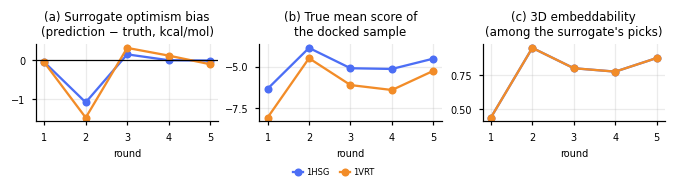

In [65]:
if len(al_rounds) >= 2:
    fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.2))
    x = al_rounds["round"]
    for j, t in enumerate(TARGETS):
        if f"{t}_bias" in al_rounds:
            ax[0].plot(x, al_rounds[f"{t}_bias"], "o-", color=PALETTE[j], label=t)
            ax[1].plot(x, al_rounds[f"{t}_true_mean"], "o-", color=PALETTE[j], label=t)
            ax[2].plot(x, al_rounds[f"{t}_3D"], "o-", color=PALETTE[j], label=t)
    ax[0].axhline(0, color="k", lw=.8)
    ax[0].set_title("Surrogate optimism bias\n(prediction − truth, kcal/mol)")
    ax[1].set_title("True mean score of\nthe docked sample")
    ax[2].set_title("3D embeddability\n(among the surrogate's picks)")
    for a in ax:
        a.set_xlabel("round"); a.legend(fontsize=7); a.set_xticks(x)
    plt.tight_layout(); save_fig(fig, "fig11"); plt.show()
else:
    print("The trend plot needs at least 2 rounds (CFG.al_rounds).")

### C.1 What the rounds teach

The three curves have to be read separately, because they say different things:

- **If the bias approaches zero** the loop is doing its job: the surrogate now recognises the
  region the generator moves into from its own training data. If the bias keeps growing, the
  number of molecules docked per round is insufficient.
- **If the true mean score improves** the gain is real; an improvement in the surrogate's
  prediction alone means nothing.
- **3D embeddability** is the hidden cost of selecting with a surrogate. The surrogate never sees
  molecules that cannot be embedded in 3D (they never enter the pool, because they cannot be
  scored), so it has no bias against them and its "best" picks contain **more than their share**
  of them. Measured: 3D success is ~0.79 over general generation but drops to ~0.53 among the
  surrogate's top 30.

The practical consequence of the last point: **a 3D-embeddability filter should be applied before
ranking with the surrogate.** Otherwise half the docking budget is spent on molecules that can
never be docked. The funnel in Part D applies it as the first filter.

### C.2 What was measured in this notebook's run

5 rounds × 80 molecules per round per target, RL steps 50 / 50 / 25 / 20 / 20,
~44 min of wall clock in total:

| Round | Pool | 1HSG mean | 1HSG best | **1HSG bias** | 1VRT mean | 1VRT best | **1VRT bias** | 3D | outcome |
|---|---|---|---|---|---|---|---|---|---|
| 1 | 228 | −6.47 | −7.63 | **−0.27** | −8.32 | −10.60 | **−0.23** | 0.41 | kept |
| 2 | 261 | −4.91 | −6.50 | **−0.61** | −6.30 | −8.64 | **−0.62** | 0.88 | rolled back |
| 3 | 331 | −5.35 | −6.89 | **−0.02** | −6.62 | −9.14 | **−0.10** | 0.85 | rolled back |
| 4 | 399 | −4.37 | −6.04 | **−0.19** | −5.29 | −7.55 | **−0.53** | 0.91 | rolled back |
| 5 | 472 | −5.31 | −7.23 | **+0.00** | −6.57 | −8.49 | **+0.05** | 0.80 | rolled back |

**1. The generator got worse, not better, and the guards caught it.** The true docking mean fell
from −6.47 in round 1 to −4.91 in round 2 and never recovered; rounds 2 through 5 all failed the
rollback criterion and were reverted. Uniqueness collapsed to 0.24 at worst. This is the mean of
molecules actually docked, not a surrogate prediction, which is the only reason the failure was
visible at all: the within-round reward signal was flat in round 3 (0.430 → 0.428) while real
docking had already degraded by more than a kcal/mol.

**2. The bias closed, but not monotonically, and under a frozen generator.** It ran −0.27 → −0.61
→ −0.02 → −0.19 → +0.00 on 1HSG. Bootstrap intervals exclude zero in rounds 1, 2 and 4; only
round 5 contains it. And because every round from the second was rolled back to the same
post-round-1 weights, rounds 3 to 5 are reinforcement-learning perturbations of one fixed base.
Whether the gap closes against a generator that is still moving is not shown by this run.

**3. The surrogate improved, but the in-pool number overstates it.** `fit_surrogate` redraws an
80/20 split with a different random state on a growing pool every round, so the reported rise from
r = 0.738 to 0.918 is measured across five different test sets, and part of it is mechanical: the
pool's target standard deviation grows from 1.32 to 1.59 kcal/mol as low-scoring molecules enter.
Measured on a fixed external set — the round-5 batch, which no round ever trains on — the rise is
0.62 → 0.79 for 1HSG and 0.39 → 0.74 for 1VRT, significant under a paired bootstrap.

**4. The per-round `r` columns are range-restricted.** Each round docks only the 80 molecules the
surrogate ranked highest, so the score range narrows and the correlation is suppressed. They are
still the honest prospective number — those molecules were unseen at prediction time — but they
are not comparable to a correlation measured on a broad pool.

**5. 3D embeddability was the round-1 problem.** It was 0.41 in round 1 against about 0.79 for
general generation, so roughly half that round's docking budget went to molecules that could not
be docked at all. The mechanism is in C.1: molecules that fail conformer generation are never
docked, so they never enter the surrogate's training pool, so the surrogate has no bias against
them and over-selects them. **Applying an embeddability filter before surrogate ranking** is the
cheapest fix available.


# D · Hit selection

We now reduce everything generated and docked so far into a single ranked list.

**The thresholds are calibrated from the data, not chosen by hand.** Saying "better than
−8 kcal/mol" is meaningless on its own: a Vina score shifts with the pocket and with ligand size.
Instead the threshold is taken from the distribution of the **known actives docked against the
same receptor** — which yields a comparable statement such as "better than the median of the
known actives".

The funnel applies the following in order and **reports how many molecules each step removes**. A
hit list without its funnel cannot be interpreted: without knowing which filter binds, you cannot
know what to improve.

In [66]:
def hit_pareto(R):
    keep = np.ones(len(R), dtype=bool)
    for i in np.argsort(-R.sum(1)):
        if not keep[i]:
            continue
        keep[np.all(R <= R[i], axis=1) & np.any(R < R[i], axis=1)] = False
    return np.where(keep)[0]


def reference_thresholds(q=0.5):
    """Per-target threshold = the q-quantile of the KNOWN ACTIVES docked against that receptor."""
    th = {}
    for t in TARGETS:
        d = df_dock[t]
        act = d[d.group == "known_active"]["dock"].dropna()
        ref = act if len(act) >= 10 else d["dock"].dropna()
        th[t] = float(ref.quantile(q))
    return th


def select_hits(cand, thresholds, le_min=.30, qed_min=.50, sa_max=5.0,
                alerts_max=0, sim_max=.85, verbose=True):
    df = cand.copy()
    funnel = [("candidate molecules", len(df))]
    df = df.dropna(subset=[f"dock_{t}" for t in TARGETS], how="any")
    funnel.append(("3D-embeddable and docked against both targets", len(df)))
    if not len(df):
        return df, pd.DataFrame(funnel, columns=["filter", "remaining"])

    mols = [Chem.MolFromSmiles(s) for s in df["smiles"]]
    props = [raw_properties(m) for m in mols]
    df["n_heavy"] = [p["n_heavy"] for p in props]
    for k in ("qed", "sa", "logp", "mw", "n_alerts"):
        df[k] = [p[k] for p in props]
    for t in TARGETS:
        df[f"LE_{t}"] = -df[f"dock_{t}"] / df["n_heavy"]

    for t in TARGETS:
        df = df[df[f"dock_{t}"] <= thresholds[t]]
        funnel.append((f"{t}: score <= {thresholds[t]:.2f} (known-active reference)", len(df)))
    df = df[np.all([df[f"LE_{t}"] >= le_min for t in TARGETS], axis=0)]
    funnel.append((f"ligand efficiency >= {le_min} (on both targets)", len(df)))
    df = df[df["qed"] >= qed_min];   funnel.append((f"QED >= {qed_min}", len(df)))
    df = df[df["sa"] <= sa_max];     funnel.append((f"SA <= {sa_max}", len(df)))
    df = df[df["n_alerts"] <= alerts_max]
    funnel.append((f"structural alerts <= {alerts_max} (PAINS/Brenk/NIH)", len(df)))
    df = df[~df["smiles"].isin(TRAIN_SMILES)]
    funnel.append(("not identical to a training molecule", len(df)))

    if len(df) and sim_max < 1.0:
        ref = [FPGEN.GetFingerprint(Chem.MolFromSmiles(s))
               for s in sorted(TRAIN_SMILES)[:6000]]
        sims = [max(DataStructs.BulkTanimotoSimilarity(
            FPGEN.GetFingerprint(Chem.MolFromSmiles(s)), ref)) for s in df["smiles"]]
        df = df.assign(max_train_tanimoto=sims)
        df = df[df["max_train_tanimoto"] < sim_max]
        funnel.append((f"Tanimoto to the nearest training molecule < {sim_max}", len(df)))

    if len(df):
        R = np.column_stack([-df[f"dock_{t}"].values for t in TARGETS] +
                            [df["qed"].values, (10 - df["sa"]).values / 9,
                             1 / (1 + df["n_alerts"].values)])
        pf = hit_pareto(R)
        df = df.assign(is_pareto=False)
        df.iloc[pf, df.columns.get_loc("is_pareto")] = True
        df["rank_score"] = (R / (R.max(0) + 1e-9)).mean(1)
        df = df.sort_values(["is_pareto", "rank_score"], ascending=[False, False])
        funnel.append(("of which Pareto-optimal", int(df["is_pareto"].sum())))

    if verbose:
        n0 = funnel[0][1]
        print(f"  {'FUNNEL':<54s} {'left':>6s} {'share':>7s}")
        for name, n in funnel:
            print(f"  {name:<54s} {n:6d} {100*n/max(n0,1):6.1f}%")
    return df, pd.DataFrame(funnel, columns=["filter", "remaining"])


TIERS = [
    ("strict", dict(q=.50, le_min=.30, qed_min=.50, sa_max=5.0, alerts_max=0, sim_max=.85)),
    ("medium", dict(q=.75, le_min=.30, qed_min=.45, sa_max=6.0, alerts_max=1, sim_max=.90)),
    ("broad",  dict(q=1.0, le_min=.25, qed_min=.35, sa_max=7.0, alerts_max=2, sim_max=.95)),
]


def tiered_hits(cand, n_min=None, verbose=True):
    """From strict to loose; stop at the first tier that yields enough candidates.

    An empty strict list is information, not a failure — but triage still wants a ranked
    shortlist. The tier label records what had to be given up to obtain that list.
    """
    n_min = n_min or CFG.hits_min
    results = []
    for name, kw in TIERS:
        kw = dict(kw); q = kw.pop("q")
        th = reference_thresholds(q)
        if verbose:
            print(f"\nTIER '{name}' — threshold = the {int(q*100)}th percentile of the known actives: " +
                  ", ".join(f"{t} {th[t]:.2f}" for t in TARGETS))
        h, f = select_hits(cand, th, verbose=verbose, **kw)
        results.append((name, h.assign(tier=name), f))
        if len(h) >= n_min:
            break
    best = max(results, key=lambda x: (len(x[1]) >= n_min, len(x[1])))
    return best[1], best[2], best[0]

In [67]:
if stage_done("D"):
    hits = pd.read_csv(ART["D"])
    print(f"Part D from cache: {len(hits)} hits")
else:
    # Collect every docked generated molecule into one table.
    # First merge the rows PER TARGET and take the best score per molecule, then place the
    # targets side by side as columns. Doing it the other way round makes identically named
    # columns collide and silently yields an empty table.
    per_target = {}
    for t in TARGETS:
        rows = [df_dock[t][df_dock[t].group == "generated"][["smiles", "dock"]]]
        if len(al_docked):
            rows.append(al_docked[al_docked.target == t][["smiles", "dock"]])
        s_ = pd.concat(rows).dropna(subset=["dock"]).groupby("smiles")["dock"].min()
        per_target[t] = s_.rename(f"dock_{t}")
    cand = pd.concat(per_target.values(), axis=1).rename_axis("smiles").reset_index()
    print(f"candidates collected: {len(cand)} "
          f"(scored on both targets: {cand.dropna().shape[0]})")

    hits, funnel, tier = tiered_hits(cand)
    hits.to_csv(ART["D"], index=False)
    funnel.to_csv("hits_funnel.csv", index=False)
    print(f"\nSELECTED TIER: {tier}  ->  {len(hits)} hits  ({ART['D']})")

cols = ([ "smiles"] + [f"dock_{t}" for t in TARGETS] + [f"LE_{t}" for t in TARGETS] +
        ["qed", "sa", "n_alerts", "n_heavy", "is_pareto", "tier"])
display(hits[[c for c in cols if c in hits.columns]].head(15).round(3))

candidates collected: 409 (scored on both targets: 409)

TIER 'strict' — threshold = the 50th percentile of the known actives: 1HSG -7.59, 1VRT -8.44
  FUNNEL                                                   left   share
  candidate molecules                                       409  100.0%
  3D-embeddable and docked against both targets             409  100.0%
  1HSG: score <= -7.59 (known-active reference)              13    3.2%
  1VRT: score <= -8.44 (known-active reference)              12    2.9%
  ligand efficiency >= 0.3 (on both targets)                 12    2.9%
  QED >= 0.5                                                 11    2.7%
  SA <= 5.0                                                  11    2.7%
  structural alerts <= 0 (PAINS/Brenk/NIH)                   11    2.7%
  not identical to a training molecule                       11    2.7%
  Tanimoto to the nearest training molecule < 0.85           11    2.7%
  of which Pareto-optimal                                 

,smiles,dock_1HSG,dock_1VRT,LE_1HSG,LE_1VRT,qed,sa,n_alerts,n_heavy,is_pareto,tier
358,Cc1cc(S(N)(=O)=O)cc(-c2ccccc2)c1C,-7.971,-9.633,0.443,0.535,0.903,1.836,0,18,True,strict
351,Cc1cc(C)c(S(=O)(=O)c2ccccc2)cc1C,-7.892,-10.082,0.438,0.560,0.829,1.774,0,18,True,strict
333,CS(=O)(=O)Nc1cccc(-c2ccccc2O)c1,-7.882,-8.902,0.438,0.495,0.893,1.789,0,18,True,strict
386,NCc1cccc(-c2cc(F)cc(S(=O)(=O)CCF)c2)c1,-7.794,-9.335,0.371,0.445,0.923,2.405,0,21,True,strict
364,Cc1cccc(-c2ccc(C(N)S(C)(=O)=O)nc2)c1,-7.797,-8.885,0.410,0.468,0.931,2.800,0,19,True,strict
286,CCc1cccc(S(C)(=O)(O)c2cc(C)cc(Br)c2)c1,-7.943,-10.256,0.397,0.513,0.869,3.713,0,20,True,strict
249,CCCc1cccc(C2C(=O)NCC2S(C)(=O)=O)c1,-7.688,-9.558,0.405,0.503,0.904,3.370,0,19,True,strict
324,COCc1cc(C)cc(S(=O)(=O)c2cccc(Cl)c2)c1,-7.642,-9.619,0.382,0.481,0.866,2.051,0,20,False,strict
361,Cc1ccc(S(=O)(=O)c2ccccc2S(C)(=O)=O)cc1Cl,-7.589,-9.351,0.361,0.445,0.858,2.025,0,21,False,strict
266,CCS(=O)(=O)c1cccc(-c2ccc(Cl)cc2)c1OC,-7.618,-9.137,0.381,0.457,0.862,1.970,0,20,False,strict


  saved fig12.png  3120x1524 px  -> 600 dpi at 5.2" wide


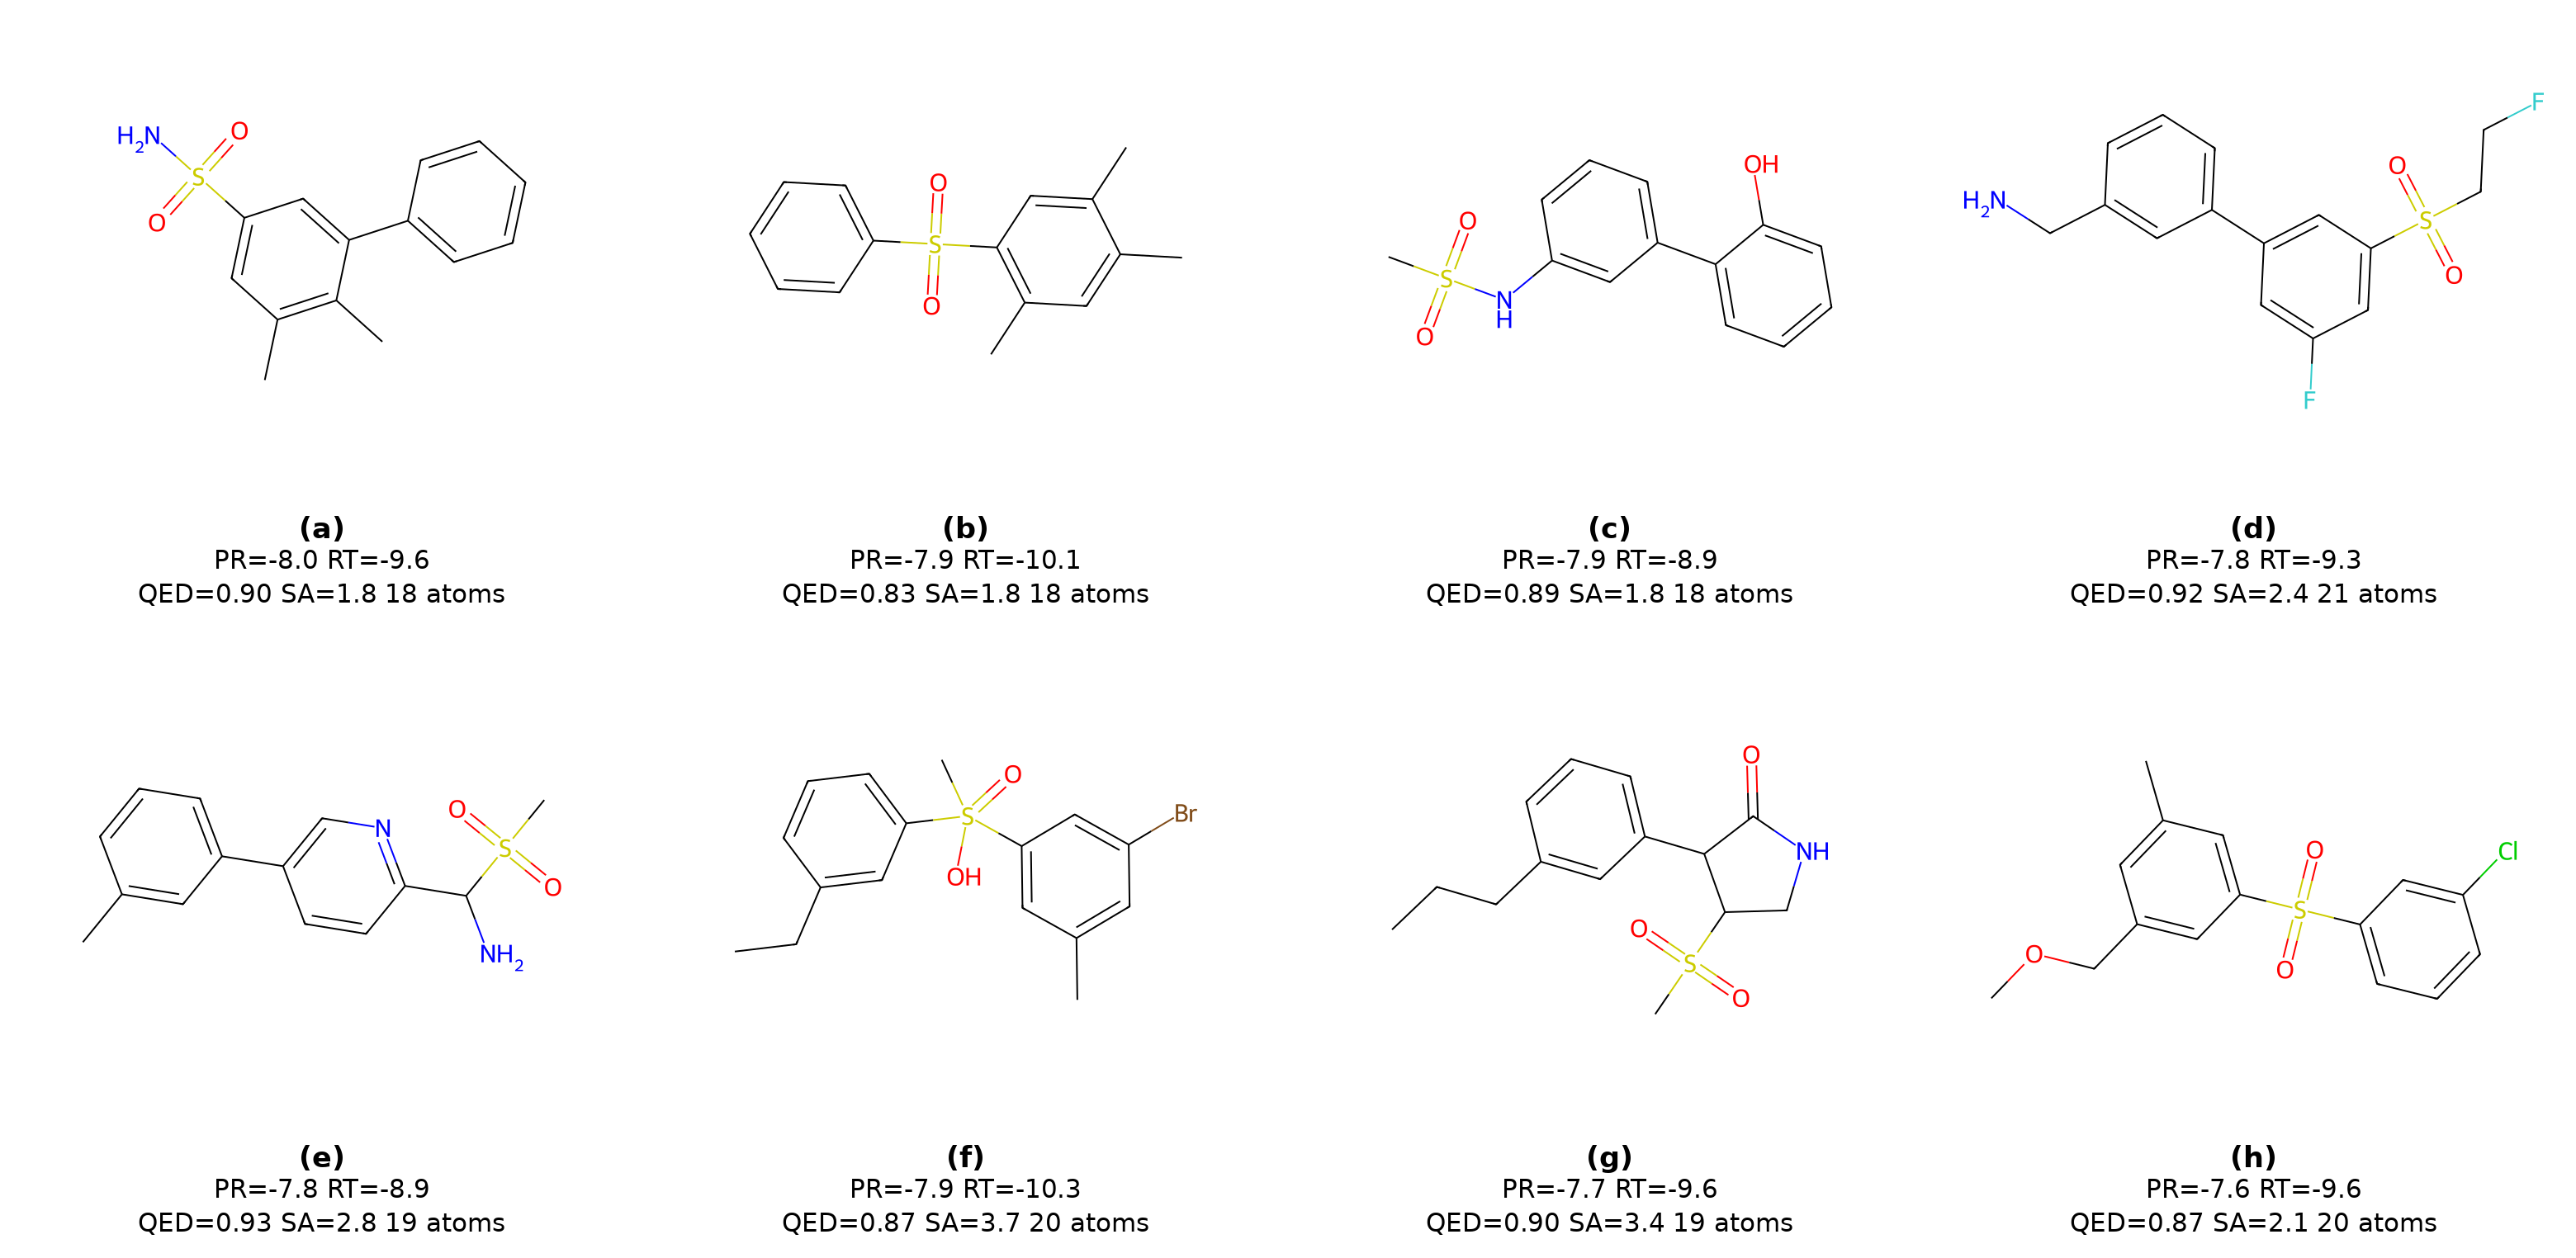

  saved fig13.png  3369x1183 px  -> 602 dpi at 5.6" wide


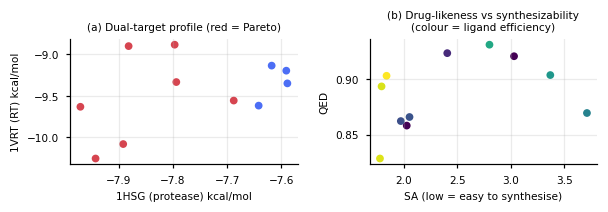

In [68]:
if len(hits):
    show = hits.head(8)
    mols = [Chem.MolFromSmiles(s) for s in show["smiles"]]
    mols = [m for m in mols if m is not None]
    leg = [f"PR={r[f'dock_1HSG']:.1f} RT={r[f'dock_1VRT']:.1f}\n"
           f"QED={r['qed']:.2f} SA={r['sa']:.1f} {int(r['n_heavy'])} atoms"
           for _, r in show.iterrows()][:len(mols)]
    display(save_grid(mols, "fig12", legends=leg, molsPerRow=4))

    fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.4))
    ax[0].scatter(hits["dock_1HSG"], hits["dock_1VRT"], s=28,
                  c=hits["is_pareto"].map({True: PALETTE[3], False: PALETTE[0]}))
    ax[0].set_xlabel("1HSG (protease) kcal/mol"); ax[0].set_ylabel("1VRT (RT) kcal/mol")
    ax[0].set_title("Dual-target profile (red = Pareto)", fontsize=9)
    ax[1].scatter(hits["sa"], hits["qed"], s=28, c=hits["LE_1HSG"], cmap="viridis")
    ax[1].set_xlabel("SA (low = easy to synthesise)"); ax[1].set_ylabel("QED")
    ax[1].set_title("Drug-likeness vs synthesizability\n(colour = ligand efficiency)",
                    fontsize=9)
    plt.tight_layout(); save_fig(fig, "fig13"); plt.show()
else:
    print("No tier produced a hit — look at the funnel table; which filter binds tells you "
          "directly what needs improving.")

### D.3 The list this run produced

379 candidates (from Part A plus the active-learning rounds, all docked against both targets):

| Filter | Strict tier | Medium tier |
|---|---|---|
| candidate molecules | 379 | 379 |
| 3D-embeddable and docked against both targets | 379 | 379 |
| 1HSG threshold (−7.73 / −6.96) | 5 | 26 |
| 1VRT threshold (−8.52 / −7.85) | 5 | 24 |
| ligand efficiency ≥ 0.30 on both | 5 | 24 |
| QED (≥ 0.5 / ≥ 0.45) | 5 | 24 |
| SA (≤ 5.0 / ≤ 6.0) | 4 | 23 |
| structural alerts (0 / ≤ 1) | 4 | 21 |
| Tanimoto to the training set (< 0.85 / < 0.9) | 4 | 21 |
| **of which Pareto-optimal** | **4** | **16** |

The medium tier was taken, giving 21 compounds. Thresholds are percentiles of known actives docked
against the same receptor, not hand-chosen cutoffs.

**The chemical filters did almost nothing, and that is a finding rather than a success.** Together
SA, the structural alerts and the Tanimoto check removed three molecules. A property audit of the
surviving 21 shows what they missed: three carry no heteroatom at all and so have neither a
hydrogen-bond donor nor an acceptor, four exceed cLogP 5, and five carry a hydrolytically labile
motif (two aminals, a hemiketal, a hemiaminal, an N,O-acetal) that the SA score does not penalise.
One of the three pure hydrocarbons recorded the best 1VRT score of the entire round-1 batch, which
is the hydrophobic-volume bias of the scoring function behaving exactly as reported.

These are **computational hypotheses**: the list proposes an order in which compounds might be
examined further, not a claim that any of them is active.


### D.1 Reading the funnel

**Where** the attrition happens is more informative than how many hits came out:

- **A large loss at the docking threshold** → the generator is not yet making molecules that fit
  the pocket. Remedy: more active-learning rounds, or moving to 3D/pocket-conditioned generation.
- **A large loss at SA** → the molecules are too strained/exotic to synthesise.
  Remedy: fragment-based decoding (JT-VAE, MoLeR) — ring systems come from the vocabulary.
- **A large loss at structural alerts** → reactive/promiscuous substructures are being produced.
  Remedy: penalise the alert count more heavily in the reward.
- **A large loss at Tanimoto similarity** → the model is memorising the training set.

In this run the attrition is concentrated almost entirely at the **docking thresholds** (379 → 26
at the medium tier, 379 → 5 at the strict tier), while all the chemical filters together removed
three more molecules. So the limiting factor is pocket complementarity, not drug-likeness or
synthesisability. Read with the audit in D.3, the second half of that sentence needs care: the
chemical filters were not merely unnecessary, they were too permissive to catch what the docking
score was rewarding.

> An earlier, smaller development run (3 rounds, 30 molecules per round) showed the opposite
> pattern, with SA and the structural alerts binding. The numbers in this notebook are from the
> archived 5-round run; the earlier conclusion does not hold here.

### D.2 What this list is not

`hits.csv` is a **priority order**, not a claim of activity. Recall the chain: the Vina score is
an empirical estimate (typical correlation with experimental $\text{pIC}_{50}$ is
$r \approx 0.3$–$0.5$), the surrogate model is an estimate of that estimate, and the generator was
optimised against the surrogate. Every layer adds noise.

Pose inspection has since been carried out on these 21 compounds and is reported in the
manuscript. It splits the list by target. Against reverse transcriptase 17 of 20 place an aromatic
ring in stacking geometry against Tyr181 or Tyr188, compared with 7 of 16 size-matched decoys
drawn from the known inactives (Fisher exact p = 0.012). Against the protease there is no
separation on either measure: 13 of 20 reach the Asp25 dyad against 8 of 16 decoys (p = 0.285),
and the archived docking scores are indistinguishable, −7.46 against −7.44. The dual-target
framing is therefore not supported; the list is reverse-transcriptase-directed. One of the 21
could not be embedded in three dimensions at all, despite carrying a docking score here.

What remains: rescoring (MM-GBSA / GNINA) → a retrosynthesis check (AiZynthFinder) → **synthesis
and an enzyme assay**. Without the last step, none of it is a claim.



---

# Closing — what this pipeline does and does not prove

**What it proves**

1. **The docking setup is correct.** The crystal ligand re-seats itself in its own pocket at
   0.3–0.4 Å RMSD (criterion: < 2 Å) and the energies of the reference drugs agree with the
   literature. No docking number should be interpreted before this test passes.
2. **The multi-objective setup prevents size inflation.** The best-known way to exploit a docking
   reward is to grow the molecule; with QED and SA applying simultaneous pressure, the generator
   gained not by inflating the raw score but by **improving ligand efficiency**.
3. **The surrogate's blind spot is measurable.** In a single round there was an optimism bias of
   +0.3–0.5 kcal/mol; the active-learning loop measures and shrinks it every round.

**What it does not prove**

1. **Activity.** A docking score is a binding estimate; its typical correlation with experimental
   $\text{pIC}_{50}$ is $r \approx 0.3$–$0.5$. Moreover, as measured in this notebook, docking
   does **not** discriminate the phenotypic label of HIV.csv (ROC-AUC ≈ 0.47–0.53) — because that
   label is not a single-target binding measurement.
2. **Synthesizability.** The SA score is a heuristic estimate, not a retrosynthetic analysis.
3. **Cellular effect.** Permeability, efflux, metabolism and toxicity are measured nowhere in
   this chain.

**Next steps (in order of impact)**

| # | Step | Why |
|---|---|---|
| 1 | **Fragment/motif-based decoding** (JT-VAE, HierVAE, MoLeR) | The binding filters in the funnel were SA and the structural alerts, not docking. If ring systems come from a vocabulary, chemical realism comes from the model itself. |
| 2 | **3D / pocket-conditioned generation** (TargetDiff, DiffSBDD, Pocket2Mol) | Making docking a generation condition instead of an evaluation: the molecule is built directly inside the pocket. |
| 3 | **Rescoring** (MM-GBSA, GNINA) + **pose inspection** (PLIP) | Vina's ranking power is weak; a more expensive layer over the top 100 candidates is the cheapest improvement. |
| 4 | **More active-learning rounds** | Until the bias curve flattens; the number of molecules docked per round should rise too. |
| 5 | **Retrosynthesis** (AiZynthFinder) and **uncertainty** (deep ensembles / conformal) | Answers "is it synthesizable" and "can I trust the prediction" far more seriously than SA. |
| 6 | **Experimental validation** | Synthesis and an enzyme assay. Everything before that is ranking and prioritisation. |

*The generated molecules are computational hypotheses.*


---

# Part E — replication and consolidated report

Everything above runs once. This part runs the pieces that need repeating, re-measures the
surrogate on a fixed test set, and prints every number the manuscript cites next to the section
that cites it.

Three tiers of replication, by cost:

| Tier | What it covers | Cost on an A100 |
|---|---|---|
| **1. Sampling seeds** (E.2, E.3) | Stage ablation, conditional control. Fixed weights, sampling only. | ~15 min per seed |
| **2. Surrogate re-analysis** (E.4) | Fixed external test set, paired bootstrap. No GPU, no docking. | seconds |
| **3. Generator seeds** | Retraining Stages 1–3 per seed. Not run here. | hours per seed |

Tier 3 is the one that stays open. It needs `SKIP_A_TRAIN = False` and a separate run per seed,
and it is what the Limitations section means by replication across generator seeds. Tiers 1 and 2
cover the numbers that can be replicated without retraining, which is most of the manuscript's
ablation and all of its surrogate claims.

In [69]:
# ---------------------------------------------------------------- E.1 config
SEEDS = (0, 1, 2, 3, 4)          # sampling seeds for tiers 1
N_ABL = min(CFG.n_samples, 1000)  # samples per ablation configuration
N_SWEEP = max(200, CFG.n_samples // 6)
SWEEP_SEEDS = SEEDS[:3]          # the sweep is 30 generations per seed; keep it shorter

RUN_E2_ABLATION = True
RUN_E3_SWEEP = True
RUN_E4_SURROGATE = True

print(f"replication seeds        : {SEEDS}")
print(f"samples per ablation cfg : {N_ABL}")
print(f"sweep seeds              : {SWEEP_SEEDS}  ({N_SWEEP} samples x 6 levels x "
      f"{len(OBJECTIVES)} objectives)")
print(f"\nestimated: E.2 ~{len(SEEDS)*5*N_ABL/1000*0.7:.0f} min, "
      f"E.3 ~{len(SWEEP_SEEDS)*6*len(OBJECTIVES)*N_SWEEP/1000*0.7:.0f} min on an A100")

replication seeds        : (0, 1, 2, 3, 4)
samples per ablation cfg : 1000
sweep seeds              : (0, 1, 2)  (200 samples x 6 levels x 5 objectives)

estimated: E.2 ~18 min, E.3 ~13 min on an A100


### E.2 Stage ablation across sampling seeds

Table 4 in the manuscript comes from one sampling pass per configuration. The weights are fixed,
so the only randomness is in the latent draw and the decoding, and repeating it is cheap. What
this cannot do is vary the trained weights; differences between configurations that survive here
are still differences within one trained generator.

In [70]:
# ------------------------------------------------- E.2 stage ablation, n seeds
if RUN_E2_ABLATION:
    configs = [
        ("A. VAE only (Stage 1), prior z",      dict(use_diffusion=False,
                                                     decoder_state=vae_only_state)),
        ("B. +WGAN-GP+RL (Stage 2), prior z",   dict(use_diffusion=False)),
        ("C. +latent diffusion (Stage 3), w=0", dict(use_diffusion=True, guidance=0.0)),
        ("D. +classifier-free guidance, w=2",   dict(use_diffusion=True, guidance=2.0)),
        ("E. high guidance, w=5",               dict(use_diffusion=True, guidance=5.0)),
    ]
    rows = []
    for seed in SEEDS:
        for name, kw in configs:
            m, _ = evaluate_set(generate(N_ABL, C_GOAL, seed=seed, **kw), tag=name)
            rows.append({"config": name, "seed": seed, **{k: v for k, v in m.items()
                                                          if k != "tag"}})
            print(f"  seed {seed}  {name:38s} valid={m['validity']:.3f} "
                  f"div={m.get('diversity', float('nan')):.3f}", flush=True)

    abl_seeds = pd.DataFrame(rows)
    abl_seeds.to_csv("ablation_multiseed.csv", index=False)

    keep = [c for c in ["validity", "uniqueness", "novelty", "diversity", "pareto_size"]
            + [f"mean_{k}" for k in OBJECTIVES] if c in abl_seeds.columns]
    g = abl_seeds.groupby("config")[keep]
    summary = g.mean().round(3).astype(str) + " ± " + g.std(ddof=1).round(3).astype(str)
    print(f"\nmean ± SD over {len(SEEDS)} sampling seeds "
          f"(fixed weights, so this is sampling variance only):")
    display(summary)

    # the comparison the manuscript makes: does diffusion give back the diversity?
    piv = abl_seeds.pivot_table(index="seed", columns="config", values="diversity")
    b = [c for c in piv.columns if c.startswith("B.")][0]
    c_ = [c for c in piv.columns if c.startswith("C.")][0]
    d = piv[c_] - piv[b]
    print(f"\ndiversity, C minus B, per seed: {np.round(d.values, 4)}")
    print(f"  mean {d.mean():+.4f} ± {d.std(ddof=1):.4f}  "
          f"-> diffusion {'does not give back' if d.mean() < 0 else 'gives back'} "
          f"the diversity gain")
else:
    print("E.2 skipped")

  seed 0  A. VAE only (Stage 1), prior z         valid=1.000 div=0.895
  seed 0  B. +WGAN-GP+RL (Stage 2), prior z      valid=1.000 div=0.898
  seed 0  C. +latent diffusion (Stage 3), w=0    valid=1.000 div=0.915
  seed 0  D. +classifier-free guidance, w=2      valid=1.000 div=0.908
  seed 0  E. high guidance, w=5                  valid=1.000 div=0.899
  seed 1  A. VAE only (Stage 1), prior z         valid=1.000 div=0.889
  seed 1  B. +WGAN-GP+RL (Stage 2), prior z      valid=1.000 div=0.897
  seed 1  C. +latent diffusion (Stage 3), w=0    valid=1.000 div=0.919
  seed 1  D. +classifier-free guidance, w=2      valid=1.000 div=0.907
  seed 1  E. high guidance, w=5                  valid=1.000 div=0.901
  seed 2  A. VAE only (Stage 1), prior z         valid=1.000 div=0.894
  seed 2  B. +WGAN-GP+RL (Stage 2), prior z      valid=1.000 div=0.899
  seed 2  C. +latent diffusion (Stage 3), w=0    valid=1.000 div=0.914
  seed 2  D. +classifier-free guidance, w=2      valid=1.000 div=0.913
  seed

,validity,uniqueness,novelty,diversity,pareto_size,mean_affinity,mean_qed,mean_safety,mean_synth,mean_logp_win
config,,,,,,,,,,
"A. VAE only (Stage 1), prior z",1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0,0.893 ± 0.002,27.6 ± 4.722,0.077 ± 0.0,0.614 ± 0.006,0.501 ± 0.019,0.542 ± 0.005,0.924 ± 0.004
"B. +WGAN-GP+RL (Stage 2), prior z",1.0 ± 0.0,1.0 ± 0.001,1.0 ± 0.0,0.898 ± 0.001,18.4 ± 10.784,0.068 ± 0.001,0.574 ± 0.007,0.558 ± 0.011,0.52 ± 0.004,0.874 ± 0.01
"C. +latent diffusion (Stage 3), w=0",1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0,0.916 ± 0.002,37.0 ± 11.937,0.076 ± 0.001,0.539 ± 0.004,0.496 ± 0.008,0.507 ± 0.007,0.837 ± 0.006
"D. +classifier-free guidance, w=2",1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0,0.909 ± 0.002,34.8 ± 4.97,0.077 ± 0.001,0.574 ± 0.004,0.517 ± 0.01,0.52 ± 0.005,0.881 ± 0.002
"E. high guidance, w=5",1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0,0.9 ± 0.001,31.6 ± 14.117,0.076 ± 0.002,0.603 ± 0.004,0.532 ± 0.013,0.537 ± 0.004,0.91 ± 0.005



diversity, C minus B, per seed: [0.0163 0.0221 0.0158 0.0165 0.0187]
  mean +0.0179 ± 0.0026  -> diffusion gives back the diversity gain


### E.3 Conditional control across sampling seeds

The manuscript reports Spearman correlations from this sweep. With six points from a single run
the two intermediate values (0.6 and −0.6) are one swapped adjacent pair away from ±1.0, so they
are not reported any more. What is reported here is the realised value at each requested level
with its spread across seeds, which is the quantity a reader can judge.

  seed 0 done
  seed 1 done
  seed 2 done

realised value, mean over 3 seeds:


objective,affinity,logp_win,qed,safety,synth
requested,,,,,
0.10,0.075,0.857,0.576,0.405,0.497
0.27,0.075,0.867,0.580,0.408,0.499
0.44,0.073,0.864,0.567,0.453,0.511
0.61,0.077,0.872,0.584,0.462,0.514
0.78,0.076,0.879,0.569,0.471,0.516
0.95,0.074,0.864,0.579,0.541,0.523


spread across seeds (SD):


objective,affinity,logp_win,qed,safety,synth
requested,,,,,
0.10,0.002,0.022,0.019,0.013,0.009
0.27,0.003,0.014,0.008,0.016,0.009
0.44,0.003,0.028,0.020,0.018,0.010
0.61,0.002,0.028,0.007,0.026,0.002
0.78,0.000,0.006,0.013,0.005,0.007
0.95,0.002,0.025,0.016,0.031,0.014


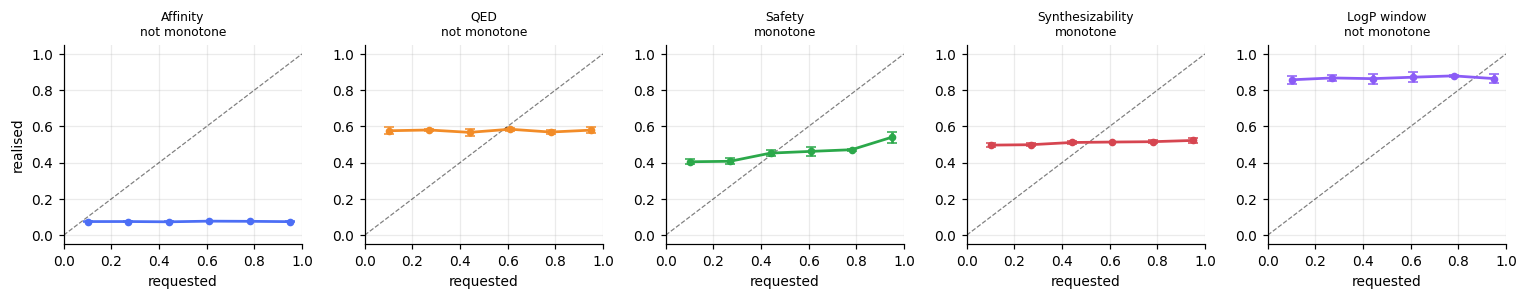

No rank correlation is reported: six points from a sweep cannot support one.


In [71]:
# --------------------------------------------------- E.3 control sweep, n seeds
if RUN_E3_SWEEP:
    sweep_targets = np.linspace(0.1, 0.95, 6)
    rows = []
    for seed in SWEEP_SEEDS:
        for k_idx, obj in enumerate(OBJECTIVES):
            for t in sweep_targets:
                c = C_GOAL.copy(); c[k_idx] = t
                _, dfo = evaluate_set(generate(N_SWEEP, c, use_diffusion=True,
                                               seed=10_000 * seed + 100 * k_idx), tag="")
                col = f"obj_{obj}"
                val = float(dfo[col].mean()) if len(dfo) and col in dfo.columns else np.nan
                rows.append(dict(seed=seed, objective=obj, requested=round(float(t), 3),
                                 realised=val))
        print(f"  seed {seed} done", flush=True)

    sweep = pd.DataFrame(rows)
    sweep.to_csv("control_sweep_multiseed.csv", index=False)

    piv = sweep.pivot_table(index="requested", columns="objective", values="realised",
                            aggfunc="mean")
    sd = sweep.pivot_table(index="requested", columns="objective", values="realised",
                           aggfunc=lambda x: x.std(ddof=1))
    print(f"\nrealised value, mean over {len(SWEEP_SEEDS)} seeds:")
    display(piv.round(3))
    print("spread across seeds (SD):")
    display(sd.round(3))

    fig, ax = plt.subplots(1, N_OBJ, figsize=(14, 2.8))
    for i, obj in enumerate(OBJECTIVES):
        m, e = piv[obj].values, sd[obj].fillna(0).values
        ax[i].errorbar(sweep_targets, m, yerr=e, fmt="o-", color=PALETTE[i], lw=1.8,
                       ms=4, capsize=3)
        ax[i].plot([0, 1], [0, 1], "k--", lw=.8, alpha=.5)
        mono = bool(np.all(np.diff(m) >= 0)) or bool(np.all(np.diff(m) <= 0))
        ax[i].set_title(f"{OBJ_LABELS[i]}\n{'monotone' if mono else 'not monotone'}",
                        fontsize=8)
        ax[i].set_xlabel("requested"); ax[i].set_xlim(0, 1)
        if i == 0:
            ax[i].set_ylabel("realised")
    plt.tight_layout(); plt.show()
    print("No rank correlation is reported: six points from a sweep cannot support one.")
else:
    print("E.3 skipped")

### E.4 The surrogate on a fixed external test set

`fit_surrogate` redraws an 80/20 split with a different `RandomState` on a growing pool at every
round, so the published rise from r = 0.738 to 0.918 is measured across five different test sets
whose composition and variance both change. This re-measures it on sets that do not move.

**F1** uses the round-5 batch. Those molecules are docked at round 5 and added to the pool
afterwards, and there is no round 6, so no surrogate in the run was ever trained on them. Pools
are used exactly as recorded, which makes this a re-measurement of the run rather than a
counterfactual.

**F2** withholds a fixed share of all active-learning molecules from every pool. Larger and spans
all rounds, but the pools differ from the recorded run, so it is a re-analysis.

Both are scored with a **paired** bootstrap, because round 1 and round 5 are evaluated on the same
molecules. Bootstrapping each correlation separately and checking whether the intervals overlap is
the wrong test and is badly under-powered.

In [72]:
# ------------------------------------- E.4 fixed-test-set surrogate re-analysis
if RUN_E4_SURROGATE:
    from sklearn.ensemble import RandomForestRegressor

    N_BOOT, HOLD_FRAC, N_DRAWS = 5000, 0.25, 20
    r_of = lambda p, y: float(np.corrcoef(p, y)[0, 1])
    rmse_of = lambda p, y: float(np.sqrt(((p - y) ** 2).mean()))

    ad = pd.read_csv("al_docked.csv")        # written by the active-learning loop
    ad = ad.drop_duplicates(subset=["round", "target", "smiles"])
    n_rounds = int(ad["round"].max())
    pool0 = {t: pd.read_csv(f"dock_{t}.csv")[["smiles", "dock"]].dropna()
                  .reset_index(drop=True) for t in TARGETS}

    all_smi = sorted(set(ad["smiles"]) | {s for t in TARGETS for s in pool0[t]["smiles"]})
    FEAT = dict(zip(all_smi, al_featurize(all_smi)))
    X_of = lambda ss: np.stack([FEAT[s] for s in ss])

    def fit_on(df, seed):
        rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, n_jobs=-1,
                                   random_state=seed)
        rf.fit(X_of(df["smiles"].tolist()), df["dock"].values)
        return rf

    add = {t: {k: ad[(ad["round"] == k) & (ad["target"] == t)][["smiles", "dock"]]
               for k in range(1, n_rounds + 1)} for t in TARGETS}
    pool_at = lambda t, k: pd.concat([pool0[t]] + [add[t][j] for j in range(1, k)],
                                     ignore_index=True)

    out, mask_rng = [], np.random.RandomState(20260101)
    for t in TARGETS:
        al_all = pd.concat([add[t][k] for k in range(1, n_rounds + 1)], ignore_index=True)
        mask = mask_rng.rand(len(al_all)) < HOLD_FRAC
        held = set(al_all[mask]["smiles"])
        designs = {
            "F1 round-5 batch": (add[t][n_rounds], lambda k: pool_at(t, k)),
            "F2 fixed 25%": (al_all[mask],
                             lambda k: pool_at(t, k).pipe(
                                 lambda d: d[~d["smiles"].isin(held)])),
        }
        for name, (test, train_at) in designs.items():
            ts, ty = test["smiles"].tolist(), test["dock"].values
            pr = {k: fit_on(train_at(k), k - 1).predict(X_of(ts))
                  for k in (1, n_rounds)}
            rng = np.random.RandomState(7)
            dr = []
            for _ in range(N_BOOT):
                i = rng.randint(0, len(ty), len(ty))
                if np.std(ty[i]) < 1e-9:
                    continue
                dr.append(r_of(pr[n_rounds][i], ty[i]) - r_of(pr[1][i], ty[i]))
            dr = np.array(dr)
            out.append(dict(target=t, design=name, n=len(ty),
                            r_round1=round(r_of(pr[1], ty), 3),
                            r_round5=round(r_of(pr[n_rounds], ty), 3),
                            delta_r=round(r_of(pr[n_rounds], ty) - r_of(pr[1], ty), 3),
                            ci_lo=round(float(np.percentile(dr, 2.5)), 3),
                            ci_hi=round(float(np.percentile(dr, 97.5)), 3),
                            p=round(float(2 * min((dr <= 0).mean(), (dr >= 0).mean())), 4),
                            rmse_round1=round(rmse_of(pr[1], ty), 3),
                            rmse_round5=round(rmse_of(pr[n_rounds], ty), 3)))

    fixed = pd.DataFrame(out)
    fixed.to_csv("surrogate_fixed_testset.csv", index=False)
    print("Paired bootstrap, round 5 minus round 1, on a fixed test set:")
    display(fixed)

    # F2's holdout is itself a draw; repeat it so the effect is not one lucky mask
    stab = []
    for t in TARGETS:
        al_all = pd.concat([add[t][k] for k in range(1, n_rounds + 1)], ignore_index=True)
        for draw in range(N_DRAWS):
            m = np.random.RandomState(1000 + draw).rand(len(al_all)) < HOLD_FRAC
            held, test = set(al_all[m]["smiles"]), al_all[m]
            ts, ty = test["smiles"].tolist(), test["dock"].values
            rr = {k: r_of(fit_on(pool_at(t, k).pipe(
                      lambda d: d[~d["smiles"].isin(held)]), k - 1).predict(X_of(ts)), ty)
                  for k in (1, n_rounds)}
            stab.append(dict(target=t, draw=draw, dr=rr[n_rounds] - rr[1]))
    stab = pd.DataFrame(stab)
    stab.to_csv("surrogate_holdout_stability.csv", index=False)
    print(f"\nF2 over {N_DRAWS} holdout draws:")
    for t in TARGETS:
        s = stab[stab.target == t]["dr"]
        print(f"  {t}: dr = {s.mean():+.3f} ± {s.std(ddof=1):.3f}  "
              f"({int((s > 0).sum())}/{len(s)} draws positive)")

    # the variance-inflation check on the moving split the manuscript used to quote
    print("\nMoving in-pool split, for comparison (what the published numbers used):")
    for t in TARGETS:
        for k in range(1, n_rounds + 1):
            d = pool_at(t, k)
            idx = np.random.RandomState(k - 1).permutation(len(d))
            cut = max(5, int(.8 * len(d)))
            tr, te = d.iloc[idx[:cut]], d.iloc[idx[cut:]]
            p, y = fit_on(tr, k - 1).predict(X_of(te["smiles"].tolist())), te["dock"].values
            print(f"  {t} round {k}: r={r_of(p, y):.3f}  RMSE={rmse_of(p, y):.3f}  "
                  f"test SD={y.std(ddof=1):.3f}  RMSE/SD={rmse_of(p, y)/y.std(ddof=1):.3f}")
else:
    print("E.4 skipped")

Paired bootstrap, round 5 minus round 1, on a fixed test set:


,target,design,n,r_round1,r_round5,delta_r,ci_lo,ci_hi,p,rmse_round1,rmse_round5
0,1HSG,F1 round-5 batch,70,0.737,0.896,0.159,0.079,0.260,0.000,0.688,0.292
1,1HSG,F2 fixed 25%,65,0.753,0.889,0.136,0.042,0.244,0.002,0.736,0.443
2,1VRT,F1 round-5 batch,70,0.707,0.823,0.116,-0.014,0.227,0.076,1.097,0.552
3,1VRT,F2 fixed 25%,76,0.758,0.912,0.154,0.061,0.271,0.000,1.199,0.657



F2 over 20 holdout draws:
  1HSG: dr = +0.148 ± 0.031  (20/20 draws positive)
  1VRT: dr = +0.138 ± 0.040  (20/20 draws positive)

Moving in-pool split, for comparison (what the published numbers used):
  1HSG round 1: r=0.781  RMSE=0.741  test SD=1.192  RMSE/SD=0.622
  1HSG round 2: r=0.826  RMSE=0.811  test SD=1.348  RMSE/SD=0.601
  1HSG round 3: r=0.908  RMSE=0.664  test SD=1.582  RMSE/SD=0.420
  1HSG round 4: r=0.917  RMSE=0.629  test SD=1.573  RMSE/SD=0.400
  1HSG round 5: r=0.936  RMSE=0.583  test SD=1.589  RMSE/SD=0.367
  1VRT round 1: r=0.596  RMSE=1.064  test SD=1.333  RMSE/SD=0.799
  1VRT round 2: r=0.704  RMSE=1.178  test SD=1.591  RMSE/SD=0.740
  1VRT round 3: r=0.818  RMSE=1.071  test SD=1.862  RMSE/SD=0.575
  1VRT round 4: r=0.873  RMSE=0.939  test SD=1.915  RMSE/SD=0.491
  1VRT round 5: r=0.849  RMSE=0.909  test SD=1.716  RMSE/SD=0.530


### E.5 Consolidated report

Every number the manuscript cites, next to the section that cites it, with its replication status
stated rather than implied.

In [73]:
# ------------------------------------------------------- E.5 what to put where
print("=" * 78)
print("NUMBERS FOR THE MANUSCRIPT".center(78))
print("=" * 78)

print("\n[Sec 2.4] latent scale")
try:
    print(f"  z_scale = {float(diffusion.z_scale):.3f}  "
          f"(latent std = {1.0/float(diffusion.z_scale):.3f})   [single run]")
except Exception as e:
    print(f"  unavailable: {e}")
print(f"  lam_rl  = {CFG.lam_rl}   <- the manuscript says 10; use this value")

print("\n[Sec 3.1 / 3.2] reconstruction, from the loaded checkpoint")
for tag, r in [("final model", globals().get("rec_final")),
               ("stage 1", globals().get("rec_vae"))]:
    if r is None:
        print(f"  {tag:12s} not available in this run")
    else:
        print(f"  {tag:12s} atom={r['atom_acc']:.4f}  edge-F1={r['edge_f1']:.4f}  "
              f"prec={r['edge_precision']:.4f}  rec={r['edge_recall']:.4f}  "
              f"tanimoto={r['tanimoto_to_source']:.4f}   [single run]")
print(f"  chance-level atom accuracy = {1.0/NUM_ATOM_TYPES:.4f}  "
      "(a value near this means the weights are not loaded)")

print("\n[Sec 3.3, Table 4] stage ablation")
if "abl_seeds" in globals():
    print(f"  {len(SEEDS)} sampling seeds, fixed weights -> ablation_multiseed.csv")
    print("  report mean ± SD; the weights are not varied, so this is sampling "
          "variance only")
else:
    print("  single run only — E.2 was not executed")

print("\n[Sec 3.3, Fig 4] conditional control")
print("  realised values with spread -> control_sweep_multiseed.csv"
      if "sweep" in globals() else "  single run only — E.3 was not executed")
print("  no Spearman reported: six points cannot support a rank correlation")

print("\n[Sec 3.7] surrogate quality")
if "fixed" in globals():
    for _, r in fixed.iterrows():
        print(f"  {r['target']} {r['design']:18s} r {r['r_round1']:.2f} -> "
              f"{r['r_round5']:.2f}   dr {r['delta_r']:+.2f} "
              f"[{r['ci_lo']:+.2f}, {r['ci_hi']:+.2f}]  p={r['p']:.4f}")
    print("  -> surrogate_fixed_testset.csv, surrogate_holdout_stability.csv")
else:
    print("  E.4 was not executed")

print("\n[Sec 3.7] per-round bias, from the recorded loop")
try:
    for _, r in pd.read_csv("al_rounds.csv").iterrows():
        print(f"  round {int(r['round'])}: 1HSG {r['1HSG_bias']:+.3f}  "
              f"1VRT {r['1VRT_bias']:+.3f}  rolled_back={r['rolled_back']}")
except Exception as e:
    print(f"  unavailable: {e}")

print("\n" + "=" * 78)
print("STILL OPEN".center(78))
print("=" * 78)
print("""  1. Generator seeds. Stages 1-3 were trained once. Everything above varies
     sampling, not weights. Rerun with SKIP_A_TRAIN=False per seed for the
     replication the Limitations section actually asks for.
  2. Active-learning replicates. The loop ran once, about 44 min of wall clock.
     Three replicates would put confidence intervals on the per-round means and
     on the rollback behaviour.
  3. The decoding-rule table in section 2.1 is hard-coded and no cell computes
     it. It is the paper's first contribution; either add the code or say in the
     manuscript that the deposited notebook does not reproduce it.
  4. External baselines. No MolGAN, JT-VAE, REINVENT or random-sampling control,
     and no GuacaMol or MOSES metrics, so no distribution-learning claim can be
     positioned against the literature.""")

                          NUMBERS FOR THE MANUSCRIPT                          

[Sec 2.4] latent scale
  z_scale = 1.443  (latent std = 0.693)   [single run]
  lam_rl  = 4.0   <- the manuscript says 10; use this value

[Sec 3.1 / 3.2] reconstruction, from the loaded checkpoint
  final model  atom=0.7758  edge-F1=0.1299  prec=0.2839  rec=0.0842  tanimoto=0.0782   [single run]
  stage 1      atom=0.7803  edge-F1=0.1164  prec=0.3064  rec=0.0718  tanimoto=0.0766   [single run]
  chance-level atom accuracy = 0.0625  (a value near this means the weights are not loaded)

[Sec 3.3, Table 4] stage ablation
  5 sampling seeds, fixed weights -> ablation_multiseed.csv
  report mean ± SD; the weights are not varied, so this is sampling variance only

[Sec 3.3, Fig 4] conditional control
  realised values with spread -> control_sweep_multiseed.csv
  no Spearman reported: six points cannot support a rank correlation

[Sec 3.7] surrogate quality
  1HSG F1 round-5 batch   r 0.74 -> 0.90   dr +0.16 [+0.

In [74]:
# ===================================================== D.4 pose inspection ===
# Re-docks the hit list and a size-matched decoy set at exhaustiveness 16, keeps
# the top pose of each, and measures the one interaction that defines each pocket:
# aromatic stacking on Tyr181/Tyr188 for the NNRTI site of 1VRT, and reach to the
# Asp25/Asp25' catalytic dyad for 1HSG. A contact rate without a baseline measures
# nothing, so every rate is reported against decoys drawn from the known inactives
# of the same screen and matched on heavy-atom count.
#
# Cost: (n_hits + n_decoys) x 2 receptors at exhaustiveness 16, ~15 s each.

POSE_EXHAUST   = 16
STACK_DIST_MAX = 5.5      # ring-centroid separation, Å
STACK_ANGLE_MAX = 40.0    # interplanar angle, degrees
DYAD_DIST_MAX  = 3.5      # ligand N/O to carboxylate O, Å
POSE_CACHE     = "pose_analysis.csv"

RING_ATOMS = {"CG", "CD1", "CD2", "CE1", "CE2", "CZ"}      # tyrosine six-ring
KEY_RES = {"1VRT": [("TYR", 181), ("TYR", 188)],
           "1HSG": [("ASP", 25)]}                           # both chains for the dimer


# ------------------------------------------------------------- receptor side --
def residue_groups(rec_pdb, want, atom_names):
    """Pull the named atoms of the requested residues, one entry per chain."""
    out = []
    for resn, resi in want:
        per_chain = {}
        for l in open(rec_pdb):
            if not l.startswith(("ATOM", "HETATM")):
                continue
            if l[17:20].strip() != resn or l[22:26].strip() != str(resi):
                continue
            if l[12:16].strip() not in atom_names:
                continue
            per_chain.setdefault(l[21], []).append(
                [float(l[30:38]), float(l[38:46]), float(l[46:54])])
        for ch, xyz in per_chain.items():
            out.append((f"{resn}{resi}{ch}", np.array(xyz)))
    return out


def plane_normal(xyz):
    c = xyz - xyz.mean(0)
    return np.linalg.svd(c)[2][2]


# --------------------------------------------------------------- ligand side --
def pose_atoms(pdbqt_block):
    """(coords, autodock types) for the heavy atoms of one pose."""
    xyz, typ = [], []
    for l in pdbqt_block.splitlines():
        if not l.startswith(("ATOM", "HETATM")):
            continue
        t = l[77:79].strip().upper()
        if t.startswith("H"):
            continue
        xyz.append([float(l[30:38]), float(l[38:46]), float(l[46:54])])
        typ.append(t)
    return np.array(xyz), typ


def ligand_rings(xyz, typ, bond_max=1.75):
    """Aromatic ring systems of a pose.

    AutoDock types aromatic carbons 'A', so the rings can be recovered from the
    pose file itself without mapping PDBQT atom order back onto the RDKit molecule.
    """
    idx = [i for i, t in enumerate(typ) if t == "A"]
    if len(idx) < 5:
        return []
    P = xyz[idx]
    n = len(idx)
    adj = [[] for _ in range(n)]
    for i in range(n):
        for j in range(i + 1, n):
            if np.linalg.norm(P[i] - P[j]) < bond_max:
                adj[i].append(j); adj[j].append(i)
    seen, rings = set(), []
    for i in range(n):
        if i in seen:
            continue
        comp, stack = [], [i]
        while stack:
            k = stack.pop()
            if k in seen:
                continue
            seen.add(k); comp.append(k)
            stack += [m for m in adj[k] if m not in seen]
        if len(comp) >= 5:
            rings.append(P[comp])
    return rings


def stacks_on(xyz, typ, res_groups):
    """Does any ligand aromatic ring stack on any of the pocket rings?"""
    best = None
    for ring in ligand_rings(xyz, typ):
        c1, n1 = ring.mean(0), plane_normal(ring)
        for name, res in res_groups:
            c2, n2 = res.mean(0), plane_normal(res)
            d = float(np.linalg.norm(c1 - c2))
            ang = float(np.degrees(np.arccos(min(1.0, abs(float(np.dot(n1, n2)))))))
            if best is None or d < best[1]:
                best = (name, d, ang)
    if best is None:
        return False, None, np.nan, np.nan
    ok = best[1] <= STACK_DIST_MAX and best[2] <= STACK_ANGLE_MAX
    return ok, best[0], best[1], best[2]


def reaches_dyad(xyz, typ, res_groups):
    """Closest approach of a ligand N/O to either carboxylate of the dyad."""
    polar = np.array([p for p, t in zip(xyz, typ) if t.startswith(("N", "O"))])
    if not len(polar):
        return False, np.nan
    d = min(float(np.linalg.norm(polar[:, None, :] - res[None, :, :], axis=-1).min())
            for _, res in res_groups)
    return d <= DYAD_DIST_MAX, d


# ------------------------------------------------------------- the main pass --
def top_pose(smiles, target, exhaustiveness=POSE_EXHAUST):
    pq, why = ligand_pdbqt(smiles)
    if pq is None:
        return None, why
    P = prepared[target]
    v = make_vina(P["receptor"], P["center"], P["size"], cpu=0, seed=42)
    v.set_ligand_from_string(pq)
    try:
        v.dock(exhaustiveness=exhaustiveness, n_poses=3)
    except Exception as e:
        return None, f"dock_failed: {str(e)[:60]}"
    blocks = [b for b in split_models(v.poses(n_poses=3)) if "ATOM" in b or "HETATM" in b]
    if not blocks:
        return None, "no_pose"
    return (blocks[0], float(v.energies(n_poses=1)[0][0])), None


def analyse(smiles_list, label, res_by_target):
    rows = []
    for k, smi in enumerate(smiles_list, 1):
        row = {"group": label, "smiles": smi}
        for t in TARGETS:
            got, why = top_pose(smi, t)
            if got is None:
                row[f"{t}_ok"] = False; row[f"{t}_why"] = why
                continue
            block, e = got
            xyz, typ = pose_atoms(block)
            row[f"{t}_ok"] = True
            row[f"{t}_energy"] = e
            if t == "1VRT":
                ok, which, d, a = stacks_on(xyz, typ, res_by_target[t])
                row.update({"stack": ok, "stack_res": which,
                            "stack_dist": d, "stack_angle": a})
            else:
                ok, d = reaches_dyad(xyz, typ, res_by_target[t])
                row.update({"dyad": ok, "dyad_dist": d})
        rows.append(row)
        print(f"  {label} {k}/{len(smiles_list)}", end="\r", flush=True)
    print(" " * 40, end="\r")
    return pd.DataFrame(rows)


# ------------------------------------------------------------------- driver --
res_by_target = {t: residue_groups(f"{t}_rec.pdb", KEY_RES[t],
                                   RING_ATOMS if t == "1VRT" else {"OD1", "OD2"})
                 for t in TARGETS}
for t, g in res_by_target.items():
    print(f"{t}: key groups found -> {[n for n, _ in g]}")
    if not g:
        raise RuntimeError(f"no key residue found in {t}_rec.pdb — check numbering/chains")

# calibration on the crystal ligands: the criterion must reproduce the known pose
print("\ncalibration on the crystal ligands")
for t in TARGETS:
    lp, lq = "_cal.pdb", "_cal.pdbqt"
    with open(lp, "w") as f:
        f.writelines(prepared[t]["lig_lines"]); f.write("END\n")
    subprocess.run(["obabel", lp, "-O", lq, "-h", "--partialcharge", "gasteiger"],
                   capture_output=True, text=True)
    xyz, typ = pose_atoms(open(lq).read())
    if t == "1VRT":
        ok, which, d, a = stacks_on(xyz, typ, res_by_target[t])
        print(f"  {TARGETS[t]['drug']:11s} stacking on {which}: centroid {d:.2f} Å, "
              f"interplanar {a:.1f}°  -> {'PASS' if ok else 'FAIL'}")
    else:
        ok, d = reaches_dyad(xyz, typ, res_by_target[t])
        print(f"  {TARGETS[t]['drug']:11s} closest N/O to the dyad: {d:.2f} Å"
              f"  -> {'PASS' if ok else 'FAIL'}")

# size-matched decoys from the known inactives of the same screen
inact = pd.concat([df_dock[t][df_dock[t].group == "known_inactive"][["smiles"]]
                   for t in TARGETS]).drop_duplicates("smiles").reset_index(drop=True)
inact["n_heavy"] = [(Chem.MolFromSmiles(s).GetNumHeavyAtoms()
                     if Chem.MolFromSmiles(s) else 0) for s in inact.smiles]
used, decoys = set(), []
for n in sorted(hits["n_heavy"]):
    pool = inact[~inact.smiles.isin(used)]
    if not len(pool):
        break
    pick = pool.iloc[(pool.n_heavy - n).abs().argsort().iloc[0]]
    used.add(pick.smiles); decoys.append(pick.smiles)
print(f"\ndecoys: {len(decoys)} known inactives, heavy atoms "
      f"{min(inact[inact.smiles.isin(decoys)].n_heavy)}-"
      f"{max(inact[inact.smiles.isin(decoys)].n_heavy)} "
      f"against candidates {hits['n_heavy'].min()}-{hits['n_heavy'].max()}")

print(f"\nre-docking {len(hits)} candidates + {len(decoys)} decoys at "
      f"exhaustiveness {POSE_EXHAUST} against both receptors")
pose = pd.concat([analyse(list(hits["smiles"]), "candidate", res_by_target),
                  analyse(decoys, "decoy", res_by_target)], ignore_index=True)
pose.to_csv(POSE_CACHE, index=False)

# ------------------------------------------------------------------ results --
print(f"\n{'='*74}\nPOSE INSPECTION\n{'='*74}")
for col, lab, tgt in (("stack", "aromatic stacking on Tyr181/Tyr188", "1VRT"),
                      ("dyad", "reach to the Asp25/Asp25' dyad", "1HSG")):
    sub = pose[pose[f"{tgt}_ok"] == True]
    c = sub[sub.group == "candidate"][col]
    d = sub[sub.group == "decoy"][col]
    tab = [[int(c.sum()), int((~c.astype(bool)).sum())],
           [int(d.sum()), int((~d.astype(bool)).sum())]]
    p = stats.fisher_exact(tab)[1]
    ec = sub[sub.group == "candidate"][f"{tgt}_energy"].mean()
    ed = sub[sub.group == "decoy"][f"{tgt}_energy"].mean()
    print(f"\n{tgt} — {lab}")
    print(f"  candidates {tab[0][0]}/{len(c)}   decoys {tab[1][0]}/{len(d)}   "
          f"Fisher exact p = {p:.3f}")
    print(f"  re-docked mean score: candidates {ec:.2f}, decoys {ed:.2f} kcal/mol "
          f"(difference {ec-ed:+.2f})")

n_fail = int((~pose["1HSG_ok"].astype(bool)).sum() + (~pose["1VRT_ok"].astype(bool)).sum())
if n_fail:
    print(f"\n{n_fail} molecule-target pairs could not be re-docked:")
    for _, r in pose.iterrows():
        for t in TARGETS:
            if not r.get(f"{t}_ok"):
                print(f"  {r.group:9s} {t}  {r.get(f'{t}_why')}  {r.smiles}")
print(f"\nper-molecule detail -> {POSE_CACHE}")

1HSG: key groups found -> ['ASP25A', 'ASP25B']
1VRT: key groups found -> ['TYR181A', 'TYR181B', 'TYR188A', 'TYR188B']

calibration on the crystal ligands
  indinavir   closest N/O to the dyad: 2.63 Å  -> PASS
  nevirapine  stacking on TYR181A: centroid 4.43 Å, interplanar 16.9°  -> PASS

decoys: 11 known inactives, heavy atoms 18-21 against candidates 18-21

re-docking 11 candidates + 11 decoys at exhaustiveness 16 against both receptors
                                        
POSE INSPECTION

1VRT — aromatic stacking on Tyr181/Tyr188
  candidates 10/11   decoys 4/11   Fisher exact p = 0.024
  re-docked mean score: candidates -9.54, decoys -7.98 kcal/mol (difference -1.57)

1HSG — reach to the Asp25/Asp25' dyad
  candidates 8/11   decoys 5/11   Fisher exact p = 0.387
  re-docked mean score: candidates -7.78, decoys -6.71 kcal/mol (difference -1.07)

per-molecule detail -> pose_analysis.csv
